# RQ3: first-word emotion classification errors

Compare **Gemma 2, OLMo 2 and Apertus** using saved `compat_correct`. A multi-word generation is scored using the project's full-label/first-word parser, never by searching later words for a matching emotion. Correctness is taken from the saved field and audited against that parser.

**Sampling matters:** `cohorts/all/samples.csv` is the union of a balanced correct/incorrect draw, not the full classification population. Only labels with >100 correct responses and some incorrect support are retained. Its error rate is 50% by design. Response-level confusion and formatting findings below describe these sampled rows only. `cohorts/support.csv` supplies full-population correct/incorrect counts for all 28 labels, including labels absent from the activation sample.

No model inference or activation downloads are needed. These are generation diagnostics associated with last-token neutral-projected activation bundles; they do not measure the effect of projection.

## Run
Select **Python (affect-geometry)**. Run all cells from the project root or `notebooks/`. The first run downloads only small tables and manifests from pinned Hugging Face revisions; subsequent runs use local files under `outputs/compat-errors/source/`. Authentication uses the project's existing `.env` / `HF_TOKEN` without displaying it.

In [1]:
from pathlib import Path
import os
import sys

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/affect_geometry").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Start Jupyter from affect-geometry or notebooks/")
OUT = ROOT / "outputs/compat-errors"
OUT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(OUT / "matplotlib-cache"))
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from IPython.display import display, Markdown
from affect_geometry.data.compat_exploration import load_sources
from affect_geometry.analysis.compat_exploration import analyze_source, count_summary
from affect_geometry.reporting.compat_exploration import model_figures, population_boxplots
from affect_geometry.logging import configure_file_logging, progress
configure_file_logging(ROOT / "logs/three-model-compat-exploration", "compat_exploration")
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 15)


Run log: /Users/abdulhakeemadefioye/Desktop/neural-geometry/affect-geometry/logs/three-model-compat-exploration/run.log


In [2]:
sources = load_sources(OUT / "source")
results = {model: analyze_source(source) for model, source in
           progress(sources.items(), description="Audit saved scores")}
CSV = OUT / "plot-ready"
PLOTS = OUT / "analysis-report/plots"
CSV.mkdir(parents=True, exist_ok=True)
PLOTS.mkdir(parents=True, exist_ok=True)
for name in ["per_gold", "distribution", "stats", "population"]:
    pd.concat([r[name] for r in results.values()], ignore_index=True).to_csv(CSV / f"{name}.csv", index=False)
provenance = pd.DataFrame([dict(**s["provenance"],
    sampled_rows=len(s["rows"]), sampled_gold_labels=s["rows"].emotion.nunique(),
    unresolved_rows=len(s["unresolved"]),
    full_population_rows=int(results[m]["population"].n.sum())) for m, s in sources.items()])
display(provenance)
print("All saved first-word predictions, validity, correctness and formatting flags agree with the project parsers.")


Load RQ3 tables:   0%|          | 0/3 [00:00<?, ?item/s]

Audit saved scores:   0%|          | 0/3 [00:00<?, ?item/s]

,model,repo_id,revision,run_id,scope,pooling,sampled_rows,sampled_gold_labels,unresolved_rows,full_population_rows
0,gemma2,kokolamba/rq3-gemma2,3ae38a8e481a56b3b7c24025fb86cea44259ef2c,rq3-activations-v1,balanced_activation_cohort,last_nonpadding_token,13796,16,0,45446
1,olmo2,kokolamba/rq3-olmo2,a581c7d352339b00789855ae1fe13d66f44120cd,rq3-activations-bs8-v1,balanced_activation_cohort,last_nonpadding_token,18084,19,0,45446
2,apertus,kokolamba/rq3-apertus,07517cb3cbb71a2cc6298cfdfaf74362805b5cb0,rq3-activations-v1,balanced_activation_cohort,last_nonpadding_token,18482,19,0,45446


All saved first-word predictions, validity, correctness and formatting flags agree with the project parsers.


## Definitions and denominators

- **Incorrect:** `compat_correct == False`.
- **Wrong emotion:** incorrect, with a valid first-word emotion. All 28 possible predicted emotions are retained even when a label is absent as a gold label in the sample.
- **Unparseable:** no valid first-word label; includes empty output and non-label first words. This is a formatting/invalid-output failure category, not proof that the underlying intended emotion was correct.
- **Strict formatting issue:** `format_compliant == False`. Split into unparseable failures, wrong-first-label responses with formatting issues, and **rescued correct** responses. The last category is not a relaxed failure.
- Confusion percentages use **all relaxed failures for that gold label**; an additional table column normalizes over valid wrong labels only. Zero denominators remain undefined, not zero.
- Min/max/mean of categorical responses is undefined. We summarize (a) incorrect counts and rates **across gold labels** using full-population support and (b) wrong-label frequency counts **within each sampled gold label**, including all 27 possible wrong labels and their zeros. Boxplots use 1.5-IQR whiskers, show outliers and mark means with triangles. They are descriptive, not confidence intervals.


## Full-population failures: all gold labels
These counts precede activation-cohort sampling. The table includes sampling eligibility so missing sampled labels remain visible. Counts depend on gold-label frequency; compare rates alongside them. Models are summarized on their saved populations, not treated as a paired statistical experiment.

,model,gold,n,correct,incorrect,incorrect_pct,sampled_per_subset,reason
0,gemma2,admiration,3384,766,2618,77.364066,766,NaN
1,gemma2,amusement,2046,505,1541,75.317693,505,NaN
2,gemma2,anger,1265,668,597,47.193676,597,NaN
3,gemma2,annoyance,1809,43,1766,97.622996,0,correct_count_not_greater_than_100
4,gemma2,approval,2367,55,2312,97.676384,0,correct_count_not_greater_than_100
5,gemma2,caring,831,16,815,98.074609,0,correct_count_not_greater_than_100
6,gemma2,confusion,1057,139,918,86.849574,139,NaN
7,gemma2,curiosity,1729,163,1566,90.572585,163,NaN
8,gemma2,desire,497,16,481,96.780684,0,correct_count_not_greater_than_100
9,gemma2,disappointment,888,223,665,74.887387,223,NaN


incorrect                         incorrect_pct                   \
              min    max      mean median           min      max    mean   
model                                                                      
apertus        31  14062  1254.857  523.5        42.134   97.025  70.956   
gemma2         36  14329  1339.321  631.0        34.030   98.896  76.254   
olmo2          29  14374  1197.143  564.0        29.081  100.000  67.989   

                 
         median  
model            
apertus  74.886  
gemma2   76.980  
olmo2    73.901

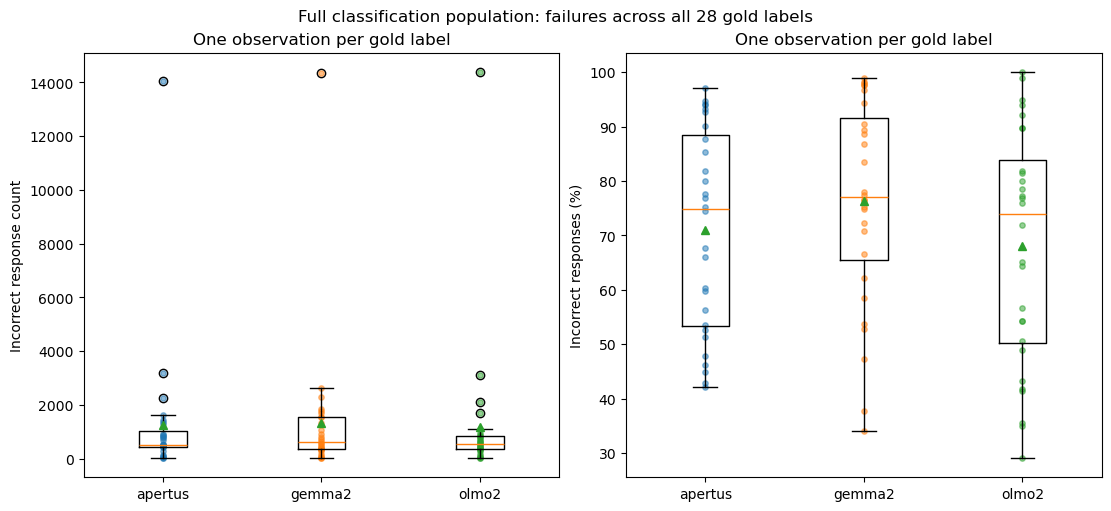

In [3]:
population = pd.read_csv(CSV / "population.csv")
display(population[["model", "gold", "n", "correct", "incorrect", "incorrect_pct", "sampled_per_subset", "reason"]])
display(count_summary(population).round(3))
population_boxplots(CSV, PLOTS)


## gemma2: sampled confusion and formatting
The first table gives each gold label's most common wrong emotion (ties retained), followed by full per-gold formatting counts and wrong-label count statistics. Missing sampled gold labels are marked `available=False`, with undefined diagnostics. The heatmap includes unparseable failures explicitly; the stacked bars distinguish rescued correct responses from remaining failures. Each per-gold box contains 27 wrong-emotion frequencies, including zeros.

,gold,prediction,count,pct_of_failures,pct_of_wrong_labels
17,admiration,joy,383,50.00,63.31
46,amusement,joy,177,35.05,62.99
69,anger,disgust,65,10.89,20.63
114,confusion,neutral,29,20.86,31.87
143,curiosity,neutral,27,16.56,24.32
170,disappointment,sadness,76,34.08,51.70
201,disapproval,neutral,24,23.76,38.71
205,disgust,anger,47,17.80,25.97
249,excitement,joy,99,57.56,65.56
272,fear,disgust,49,18.77,28.82


,gold,available,n,incorrect,unparseable,strict_format_issue,format_issue_among_failures,wrong_label_with_format_issue,rescued_correct,unparseable_pct_of_failures
0,admiration,True,1532,766.0,161.0,788.0,428.0,267.0,360.0,21.02
1,amusement,True,1010,505.0,224.0,641.0,344.0,120.0,297.0,44.36
2,anger,True,1194,597.0,282.0,734.0,438.0,156.0,296.0,47.24
3,annoyance,False,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,approval,False,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,caring,False,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,confusion,True,278,139.0,48.0,131.0,84.0,36.0,47.0,34.53
7,curiosity,True,326,163.0,52.0,173.0,103.0,51.0,70.0,31.90
8,desire,False,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,disappointment,True,446,223.0,76.0,197.0,122.0,46.0,75.0,34.08


,gold,min,max,mean,median
0,admiration,0,383,22.407,3.0
1,amusement,0,177,10.407,1.0
2,anger,0,65,11.667,4.0
3,confusion,0,29,3.370,1.0
4,curiosity,0,27,4.111,2.0
5,disappointment,0,76,5.444,1.0
6,disapproval,0,24,2.296,0.0
7,disgust,0,47,6.704,1.0
8,excitement,0,99,5.593,1.0
9,fear,0,49,6.296,1.0


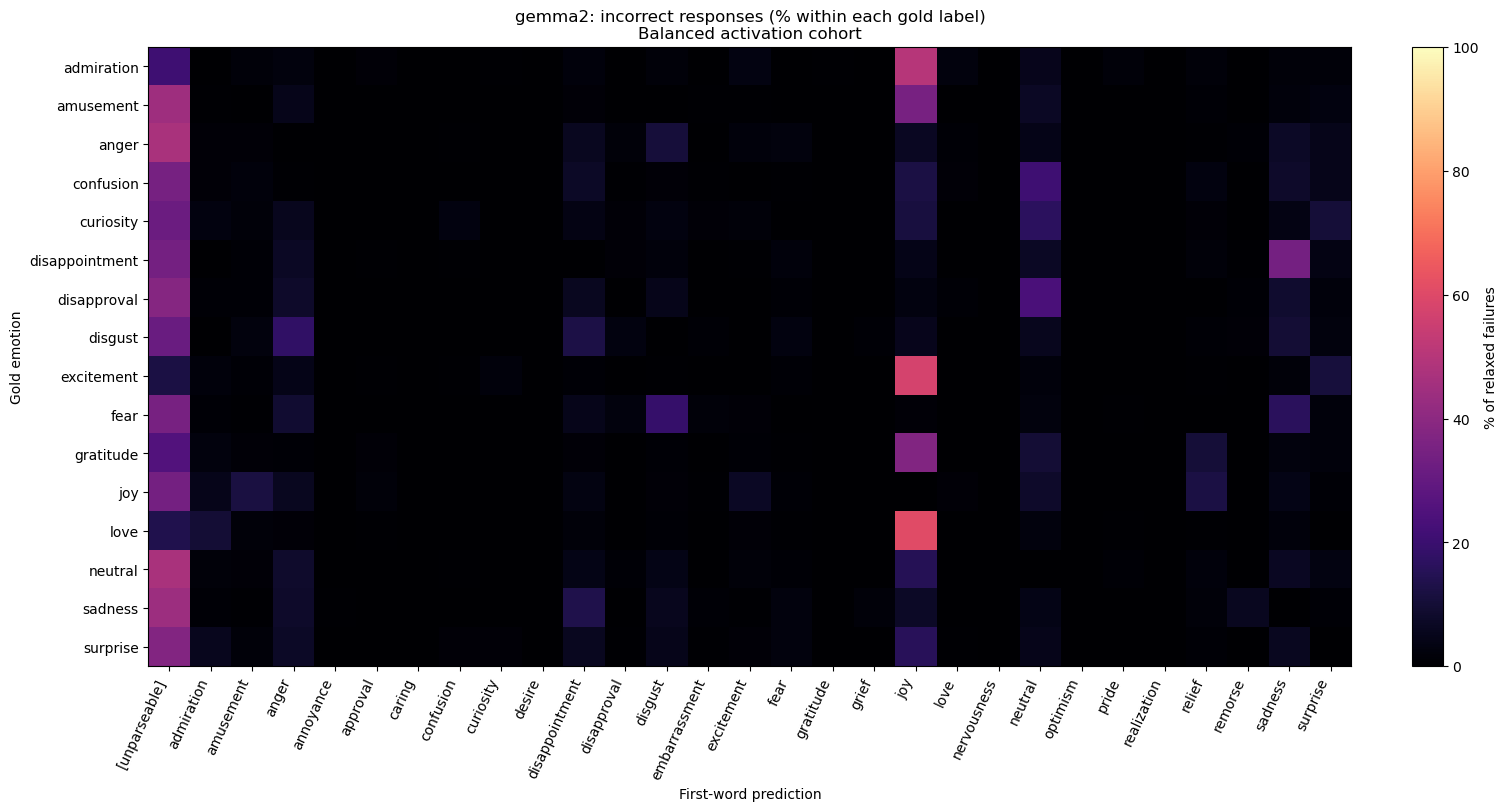

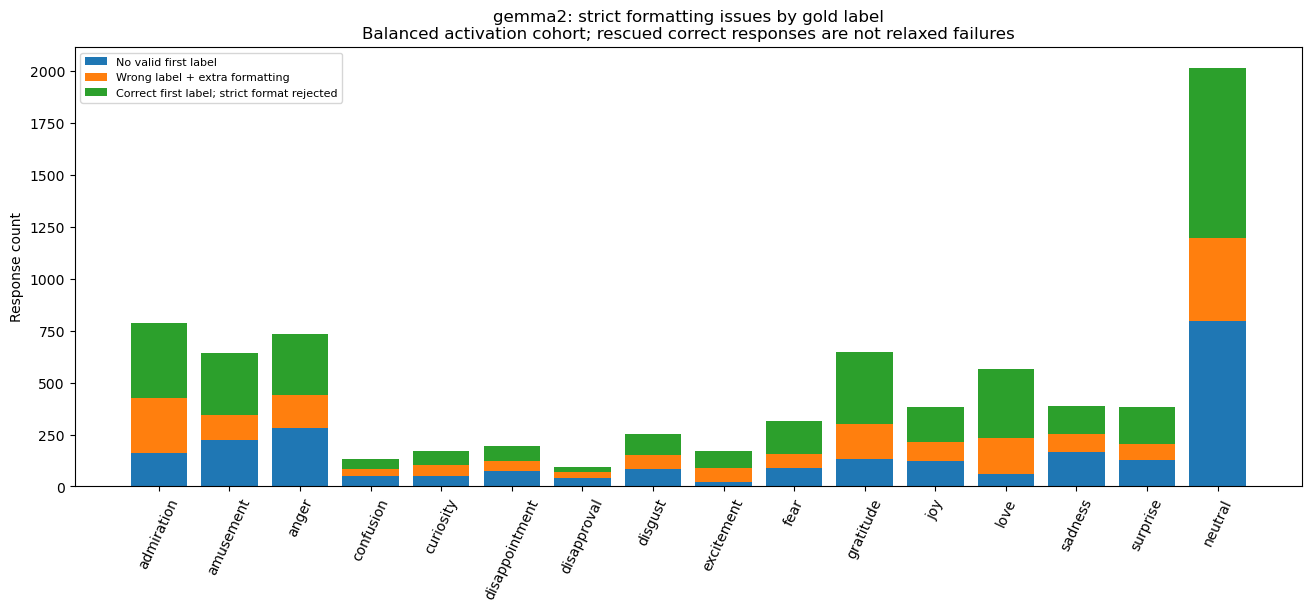

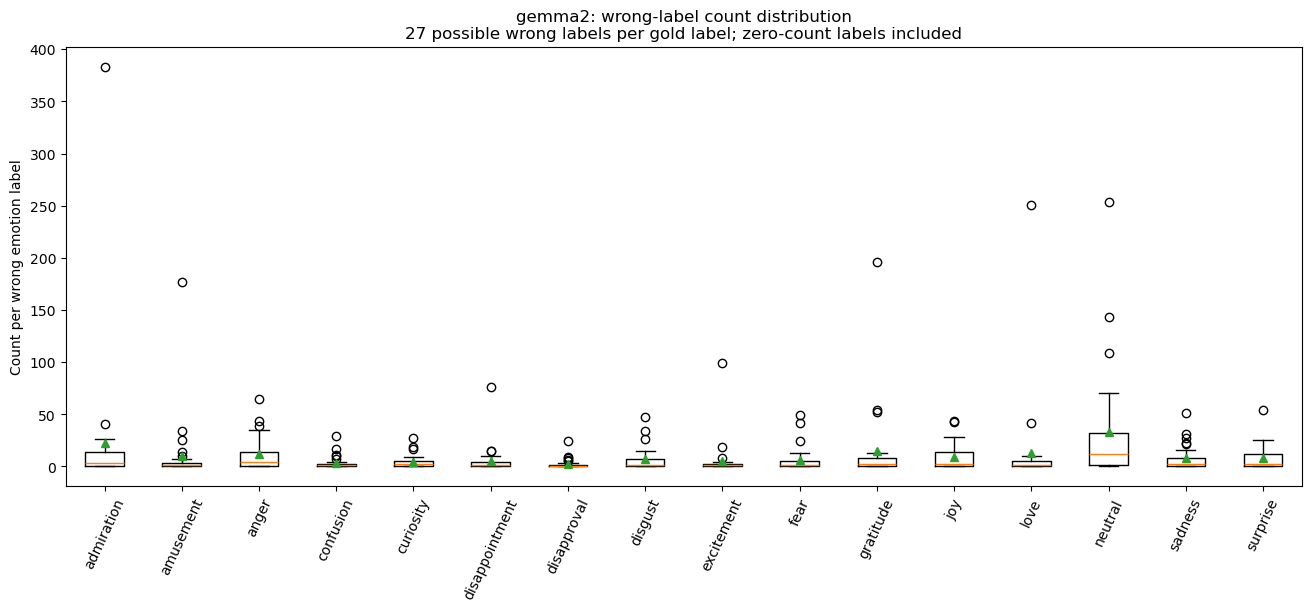

In [4]:
model = "gemma2"
distribution = pd.read_csv(CSV / "distribution.csv").query("model == @model")
wrong = distribution[(distribution.gold != distribution.prediction) & distribution.prediction.ne("[unparseable]")]
top = wrong[wrong["count"].eq(wrong.groupby("gold")["count"].transform("max")) & wrong["count"].gt(0)]
display(top[["gold", "prediction", "count", "pct_of_failures", "pct_of_wrong_labels"]].round(2))
display(pd.read_csv(CSV / "per_gold.csv").query("model == @model")[["gold", "available", "n", "incorrect", "unparseable", "strict_format_issue", "format_issue_among_failures", "wrong_label_with_format_issue", "rescued_correct", "unparseable_pct_of_failures"]].round(2))
display(pd.read_csv(CSV / "stats.csv").query("model == @model")[["gold", "min", "max", "mean", "median"]].round(3))
model_figures(CSV, model, PLOTS)


### gemma2: wrong-label histograms for every available gold label

Each categorical histogram has two panels: **response count** and **percentage among valid wrong-emotion responses for that gold label**. Percentages sum to 100% when at least one valid wrong label exists. The correct gold label is excluded; all 27 alternative emotions, including zero-count categories, are shown. Unparseable failures are counted in the title but excluded from this percentage denominator because they are not emotion labels. The earlier heatmap instead uses all relaxed failures as its denominator.

Labels without sampled records are listed explicitly rather than shown as zero-error histograms. These plots use `plot-ready/distribution.csv` and are saved under `analysis-report/plots/per-gold-histograms/gemma2/`.

**gemma2: gold labels without sampled response records:** annoyance, approval, caring, desire, embarrassment, grief, nervousness, optimism, pride, realization, relief, remorse. No histogram can be estimated for these labels; absence is not zero errors.

gemma2: per-gold histograms:   0%|          | 0/16 [00:00<?, ?label/s]

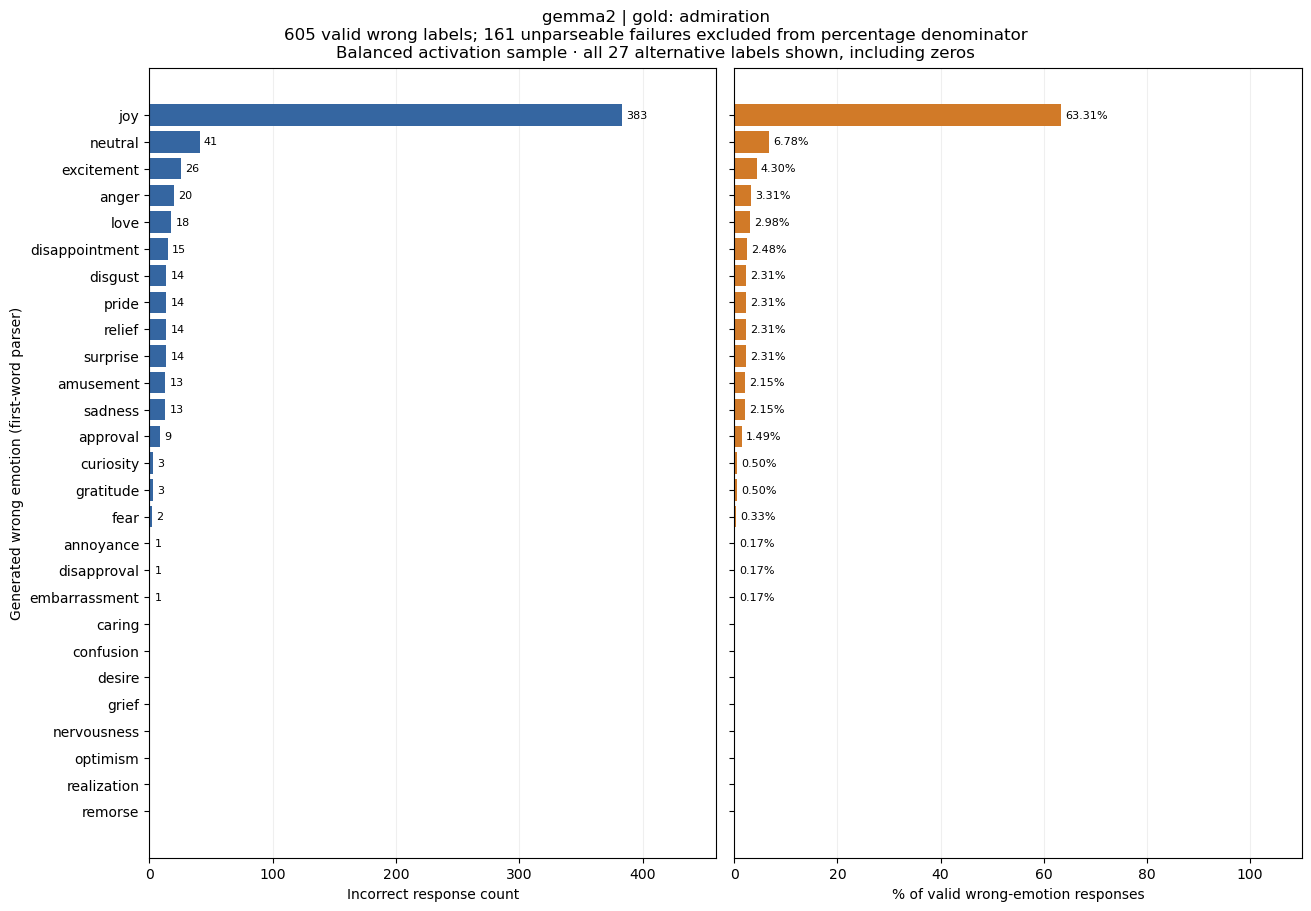

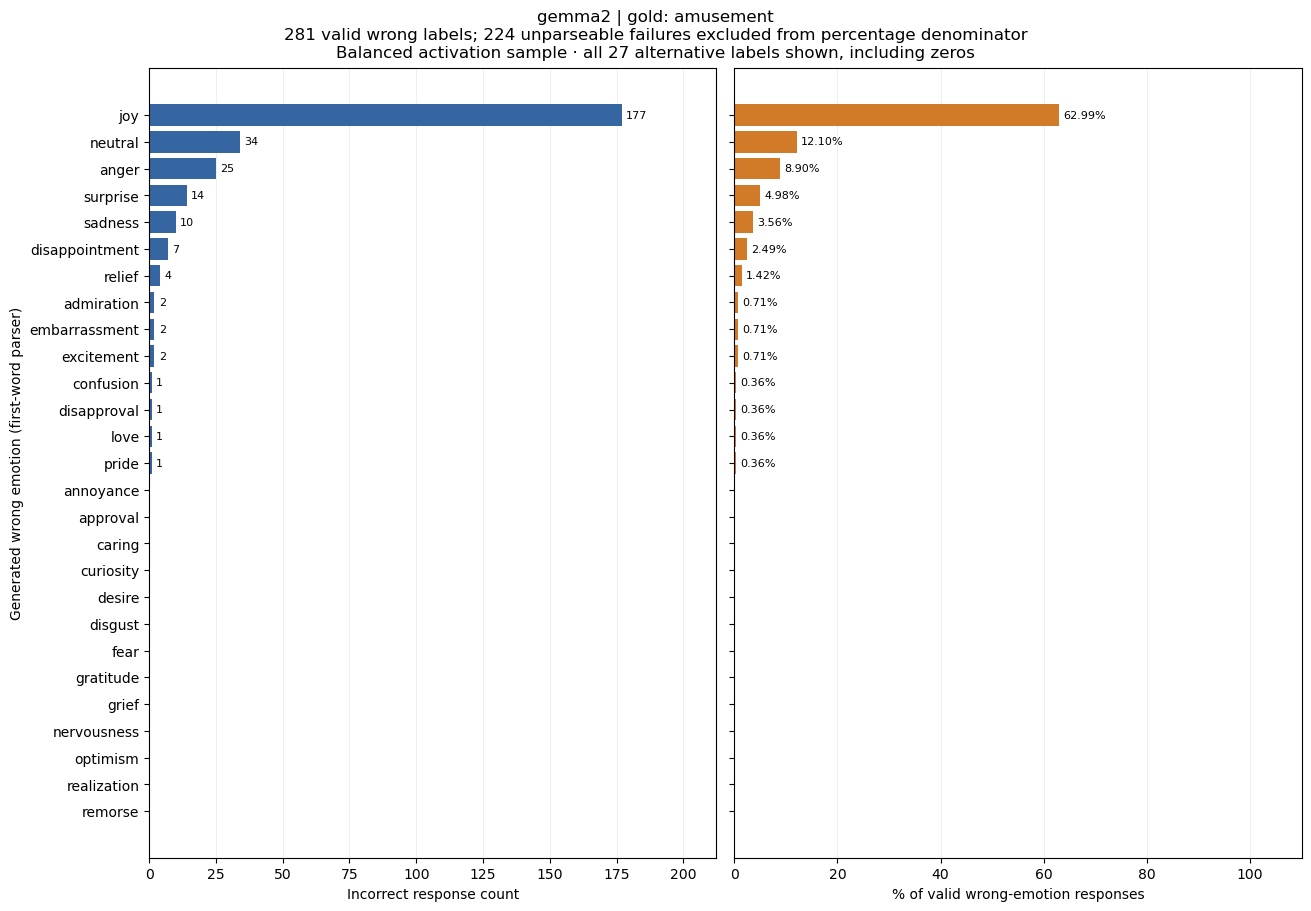

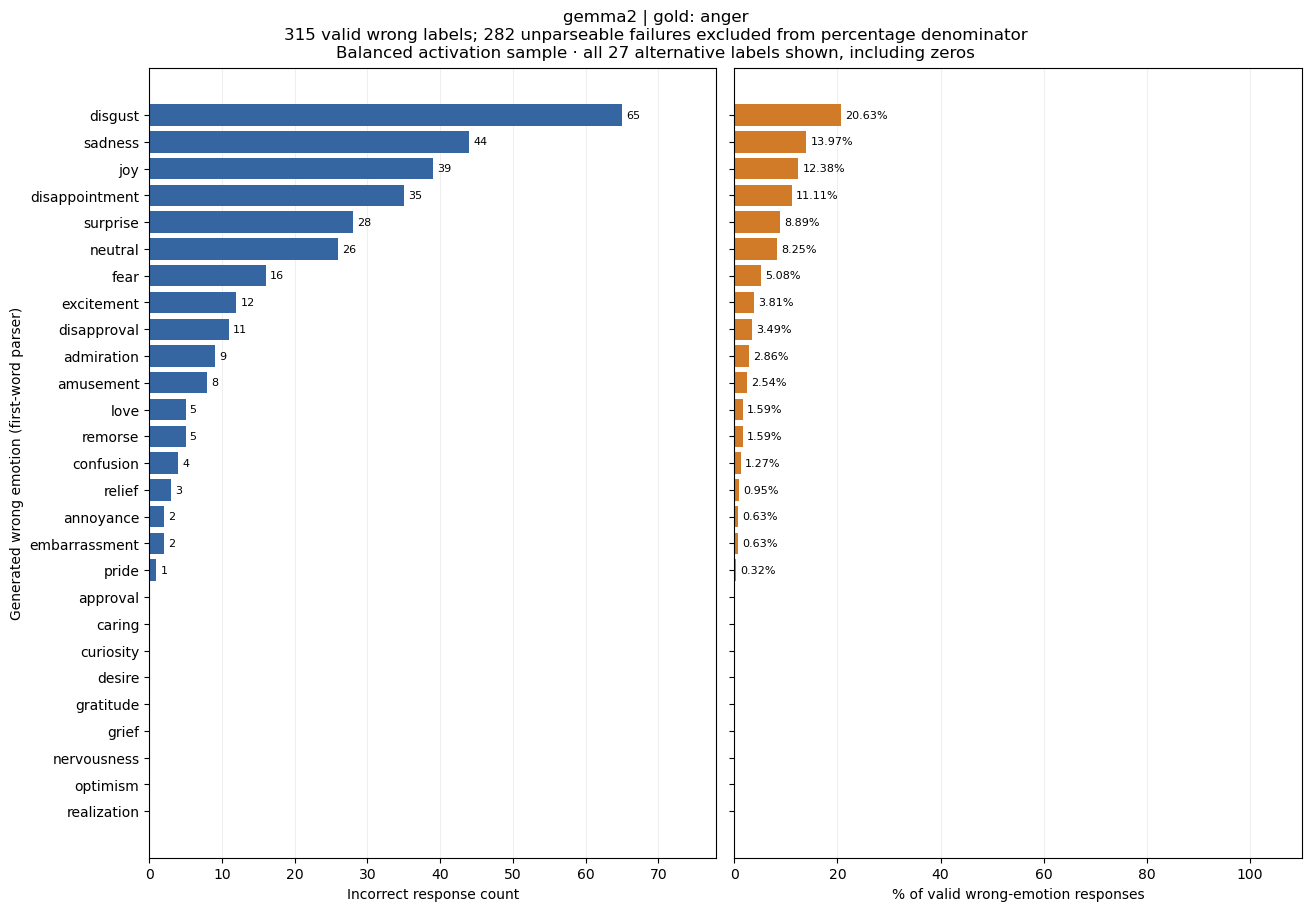

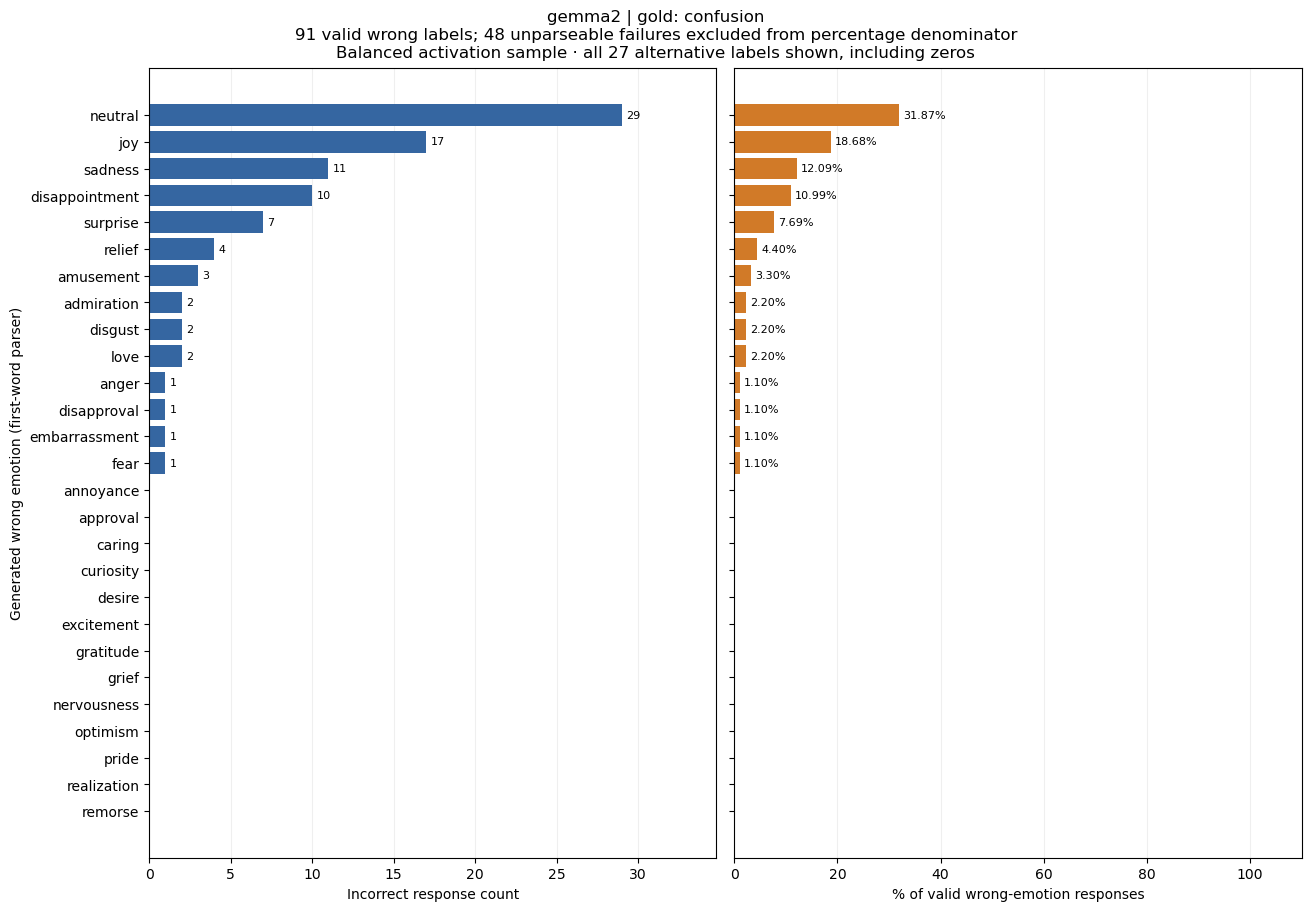

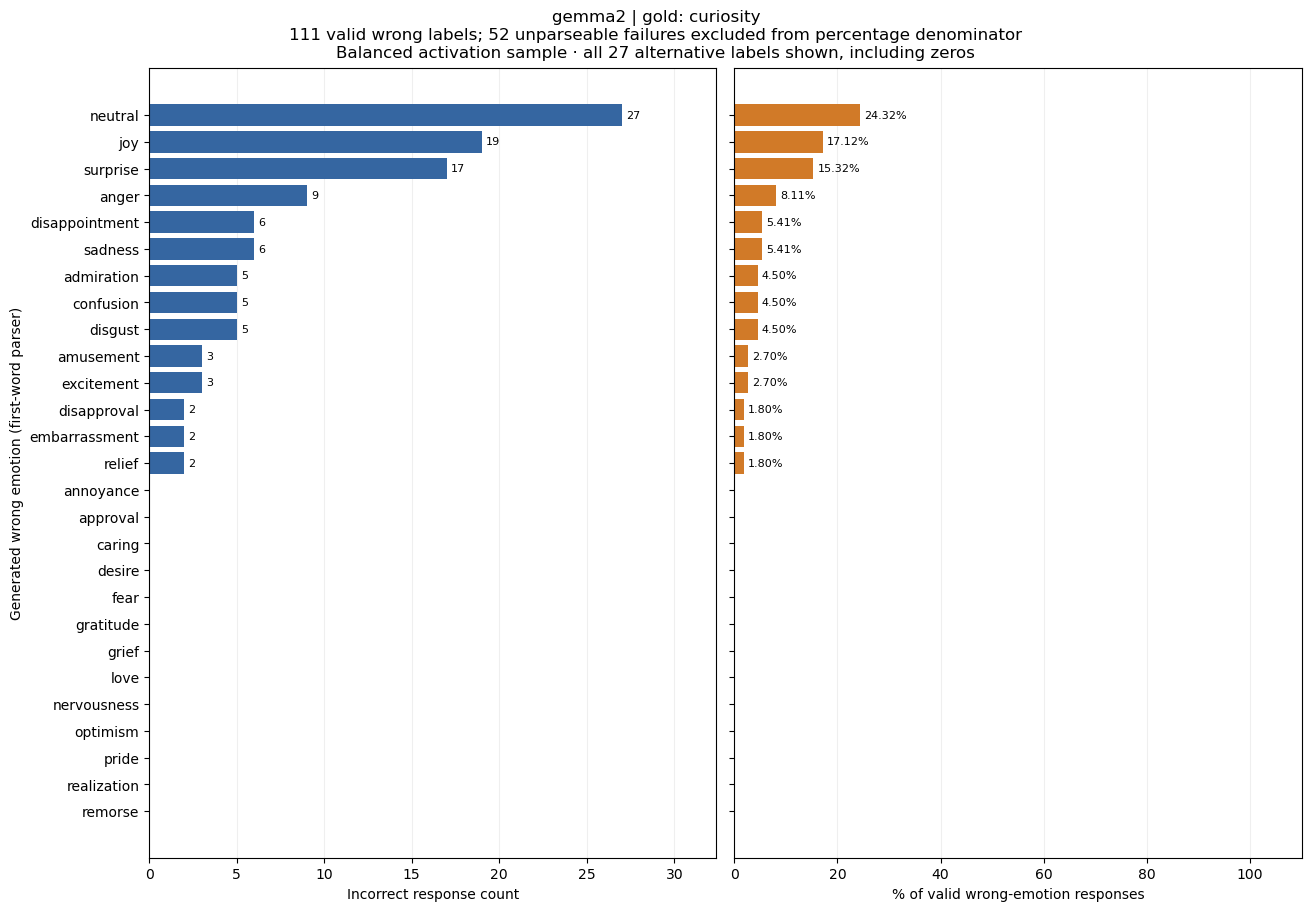

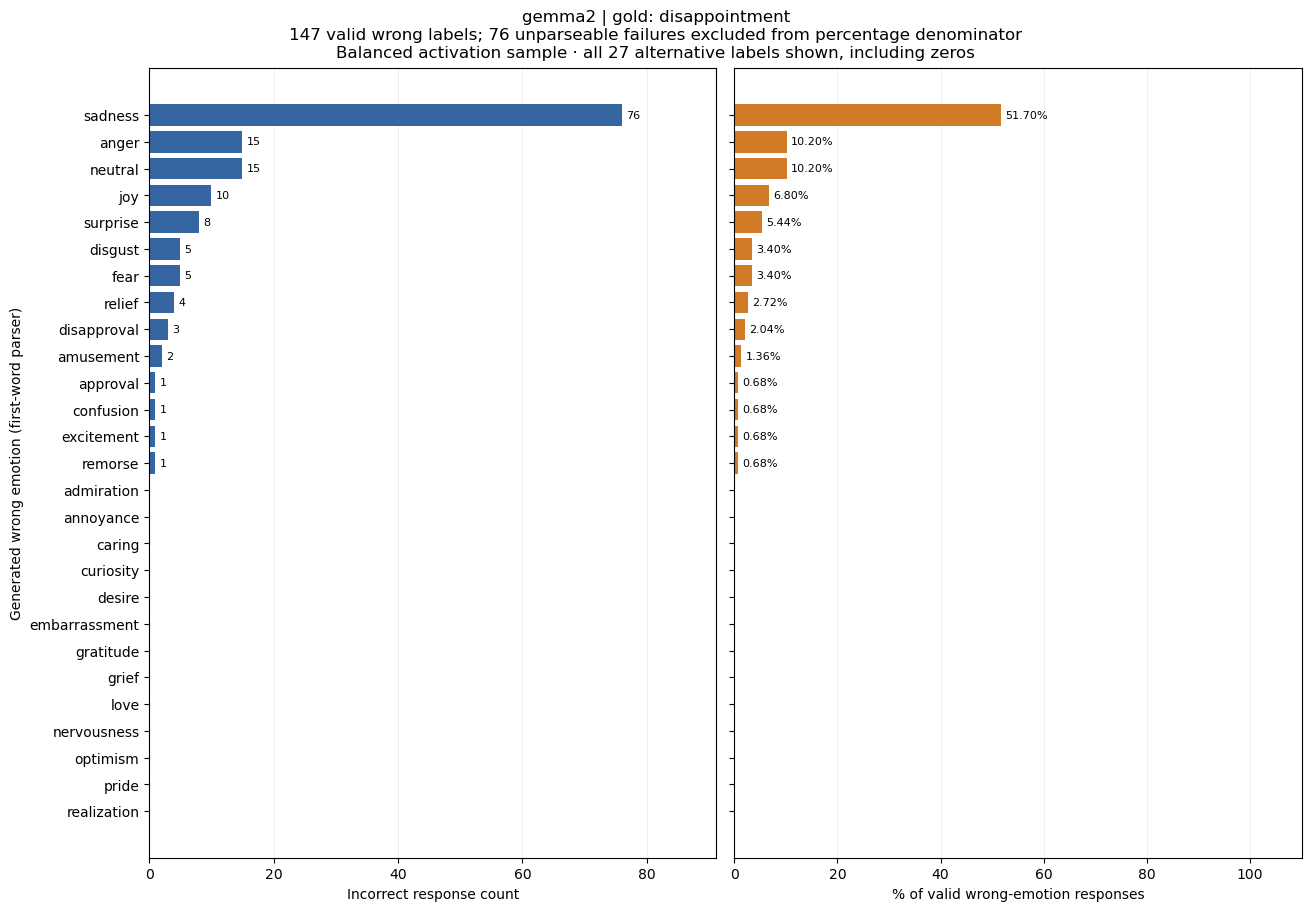

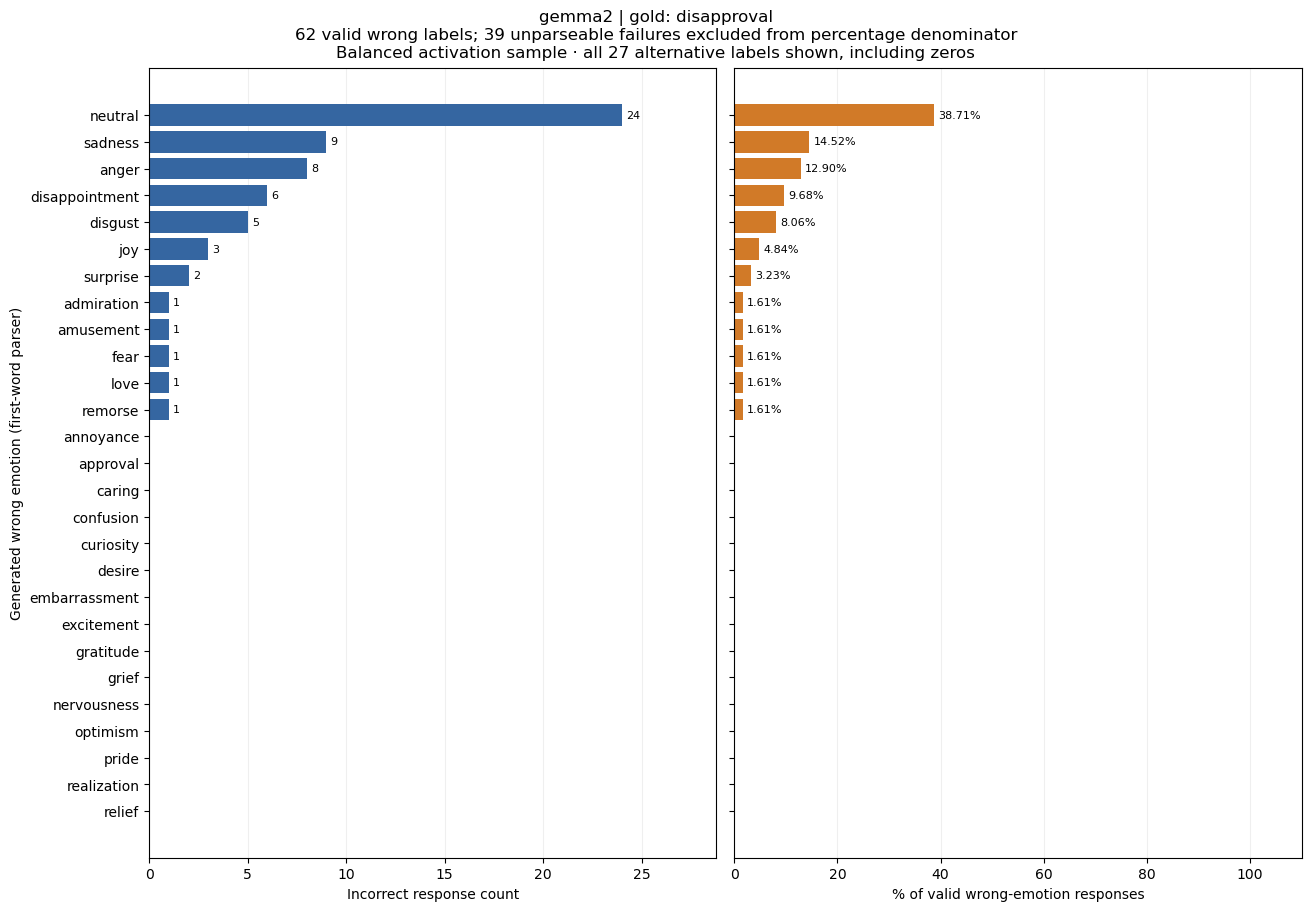

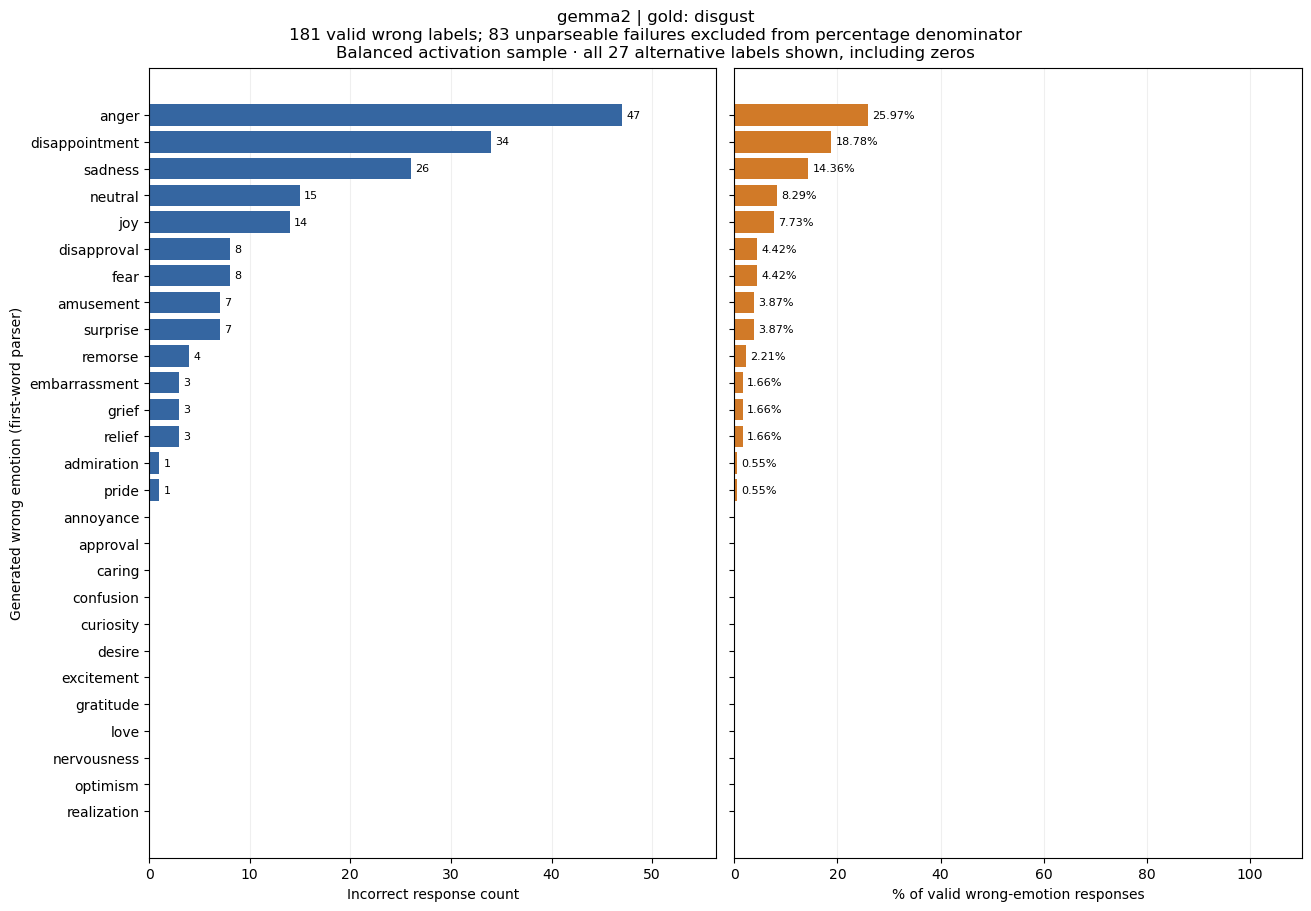

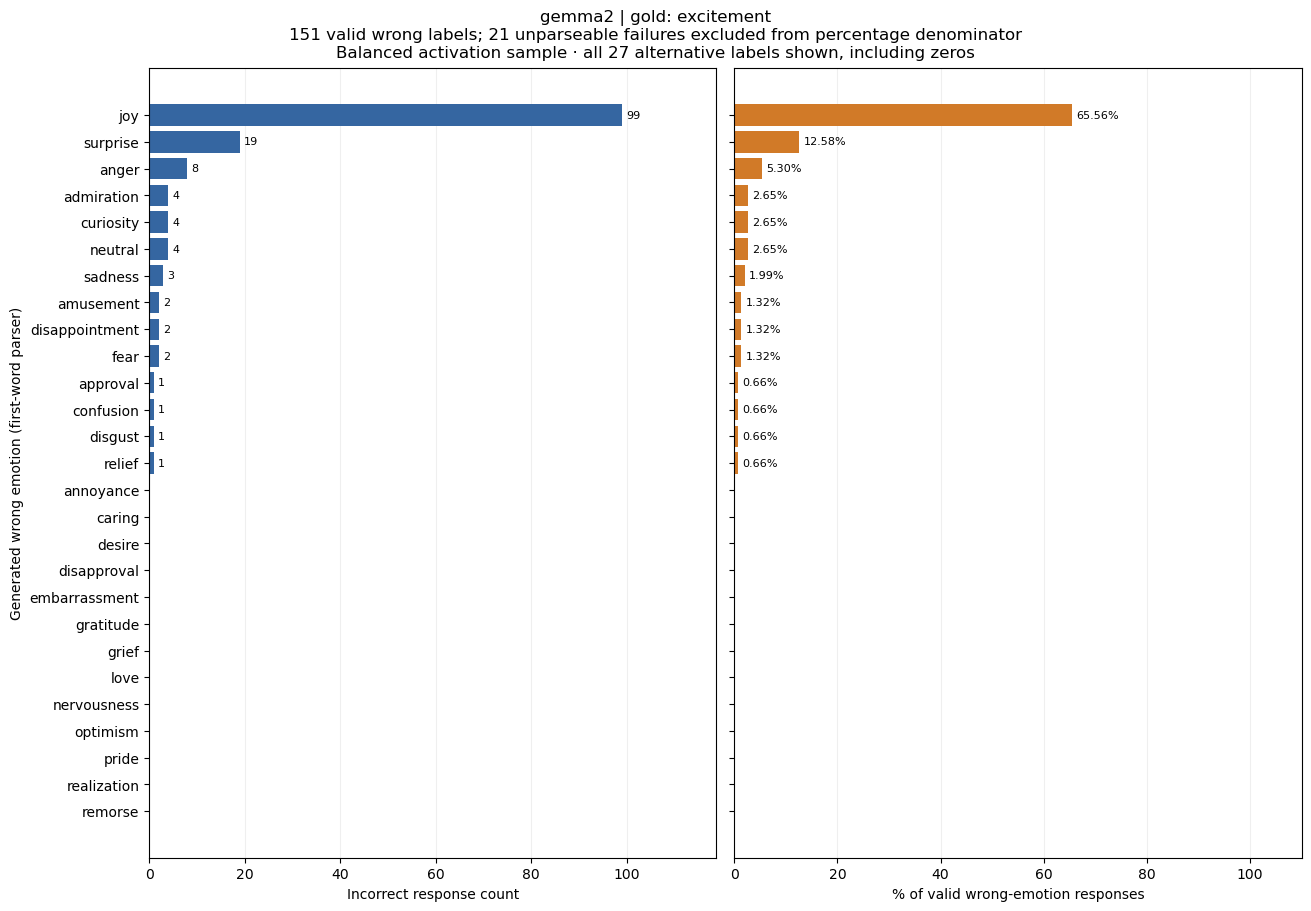

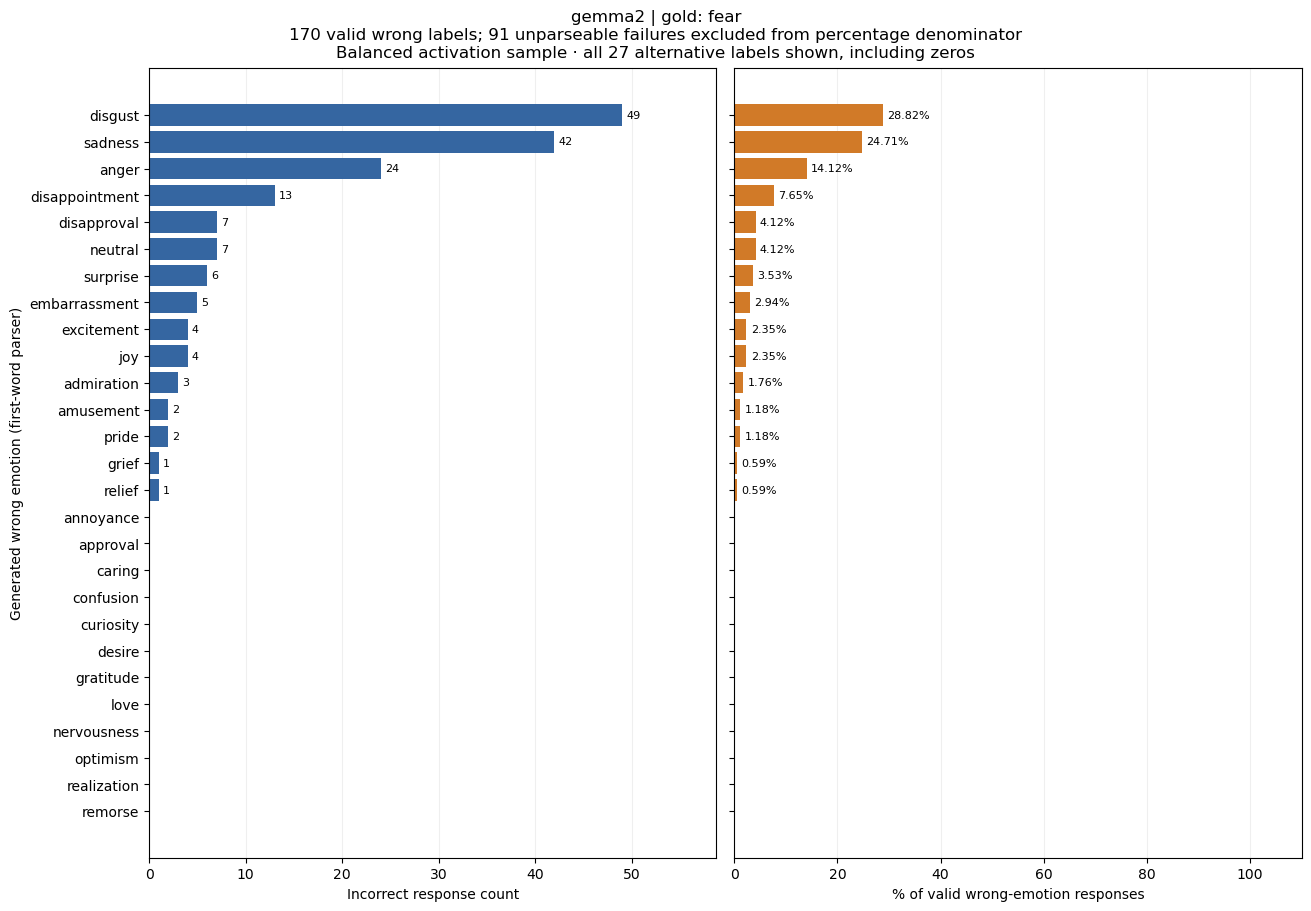

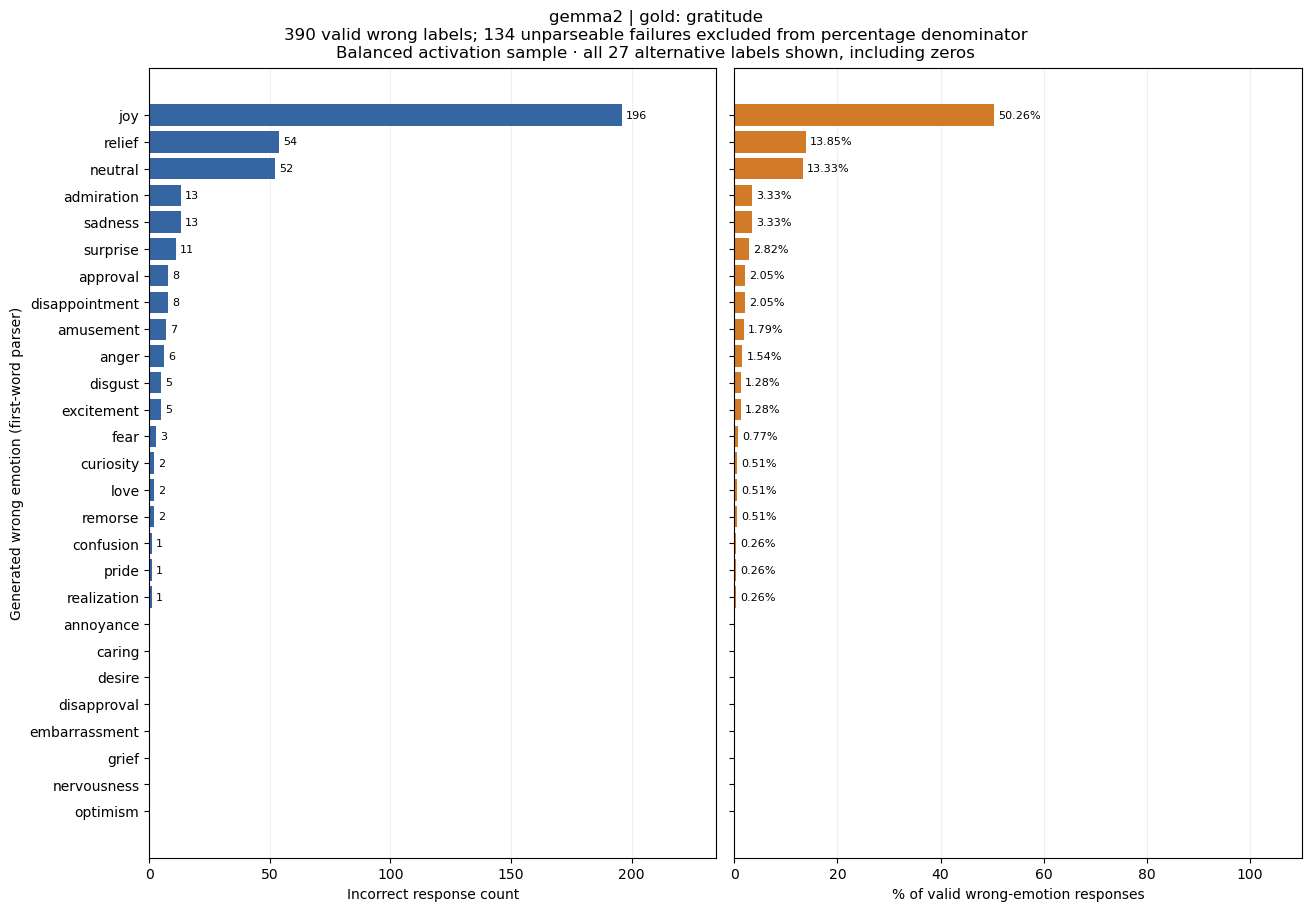

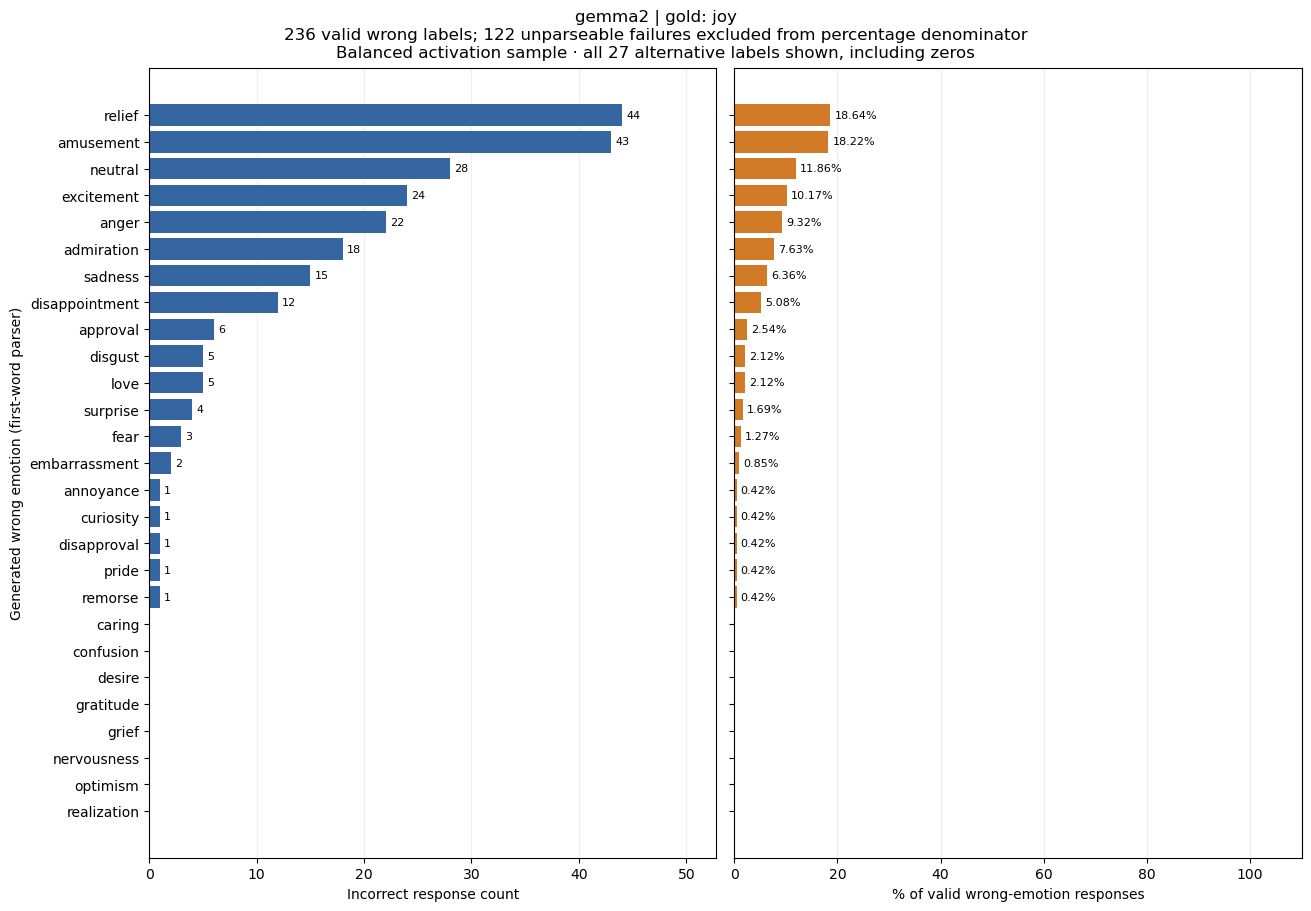

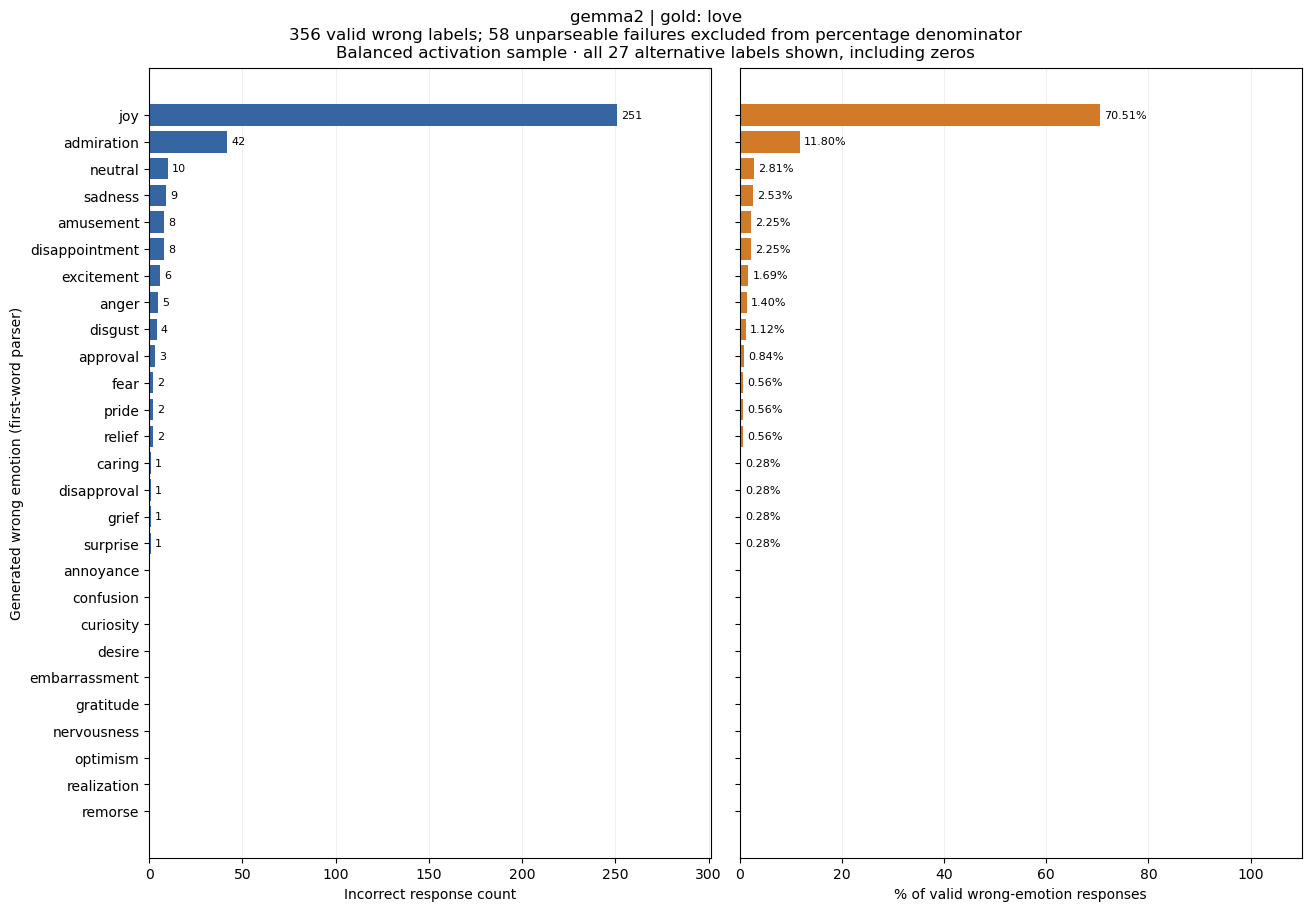

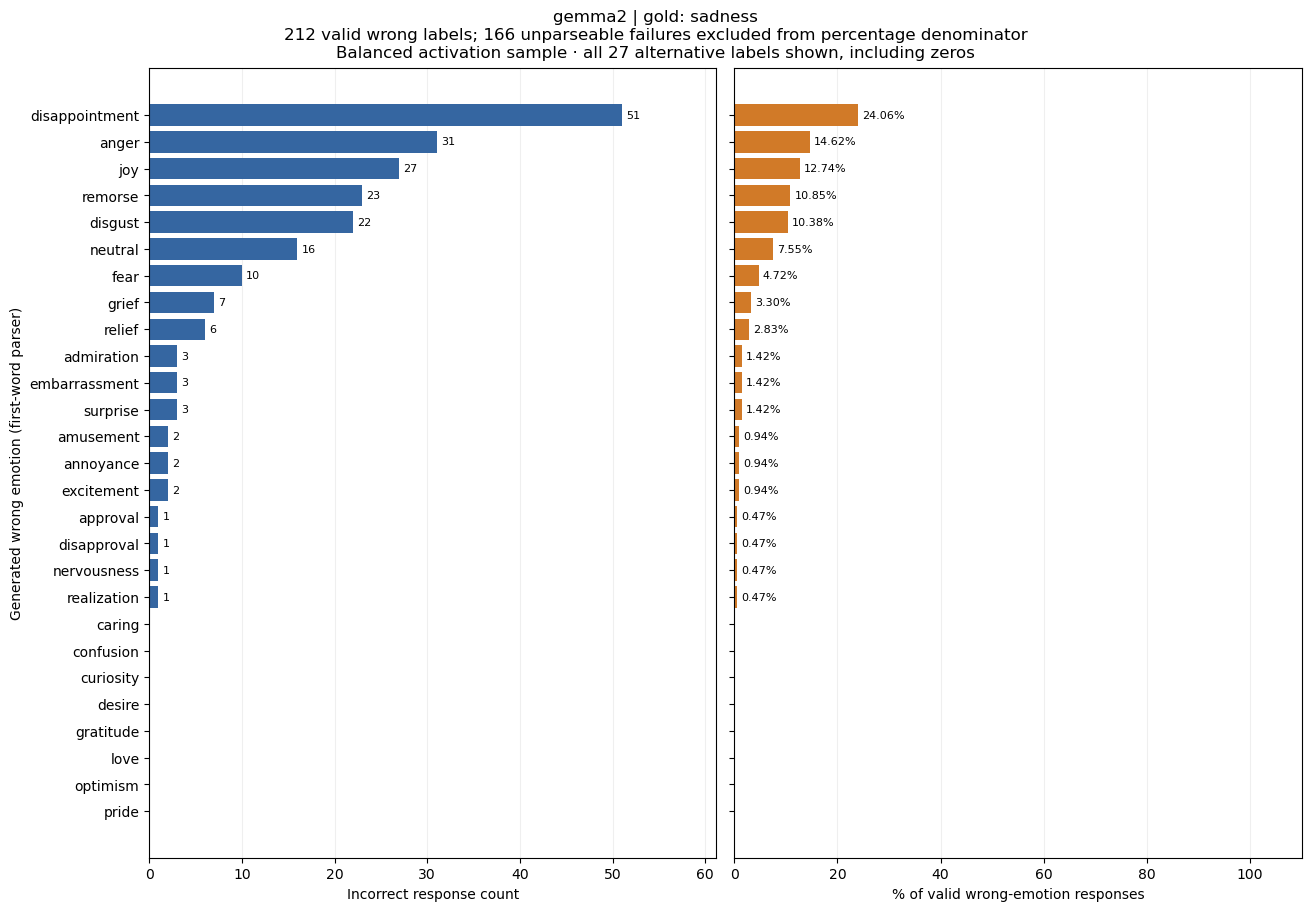

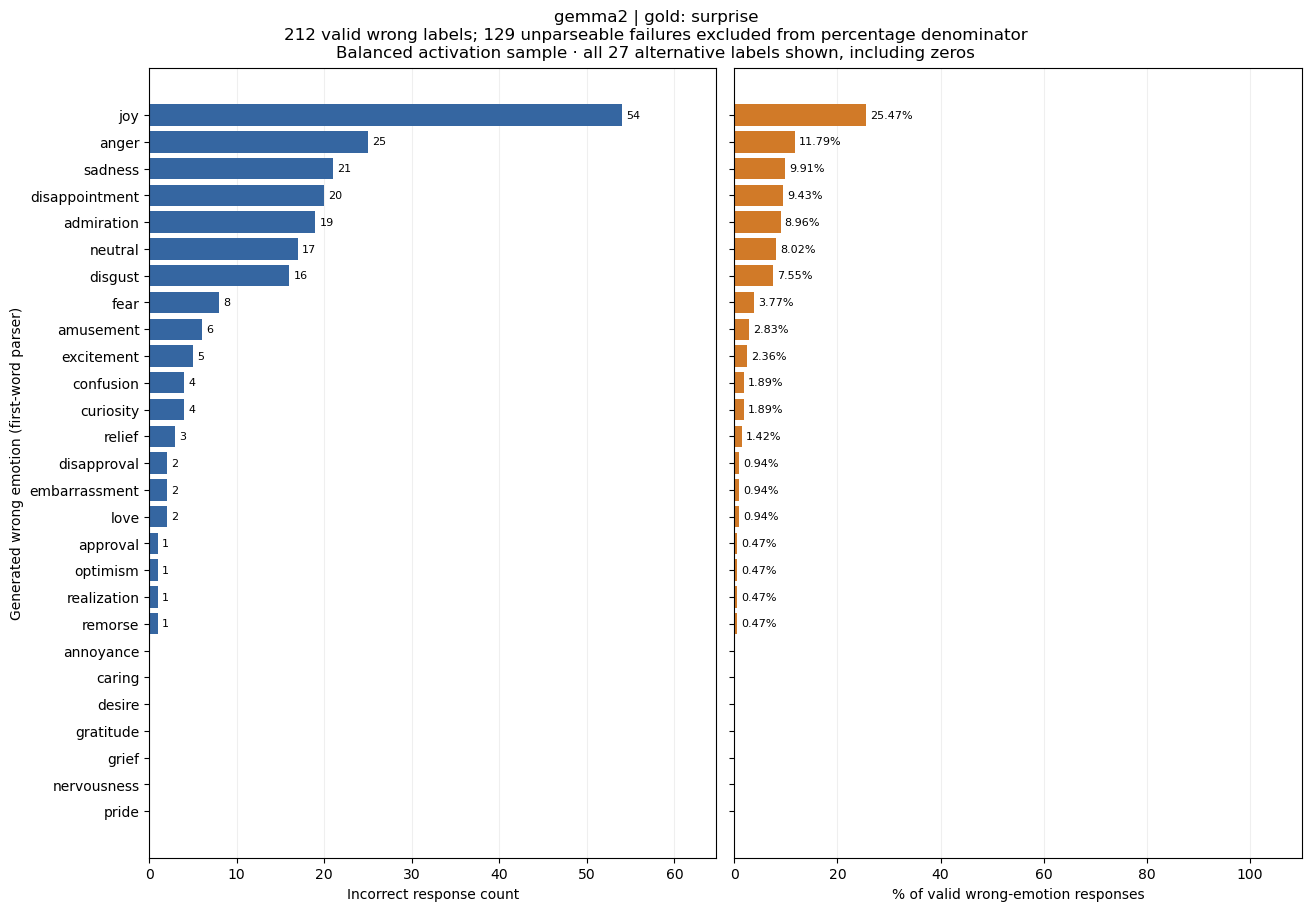

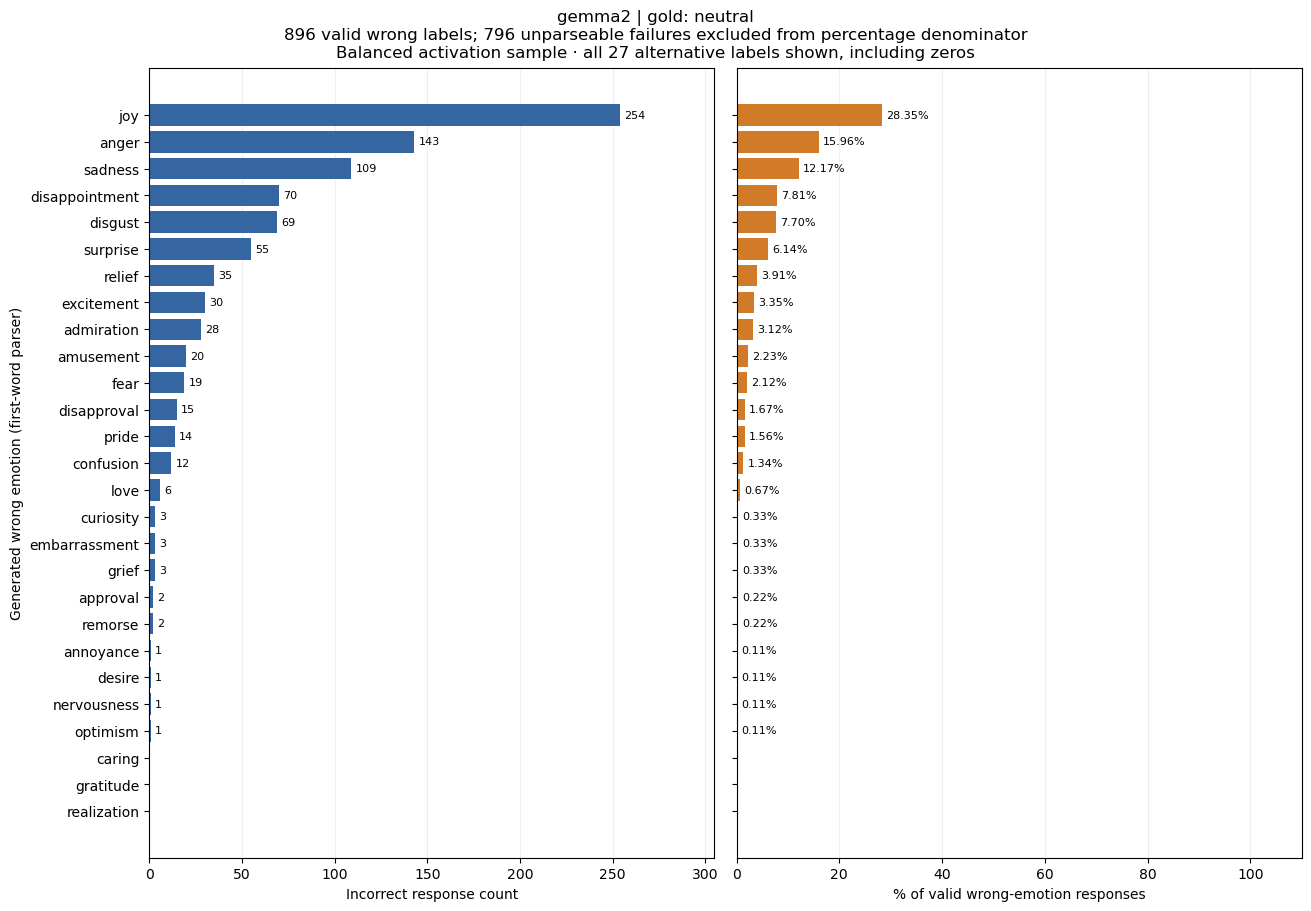

In [5]:
from affect_geometry.reporting.compat_exploration import wrong_label_histograms
wrong_label_histograms(CSV, "gemma2", PLOTS)

## olmo2: sampled confusion and formatting
The first table gives each gold label's most common wrong emotion (ties retained), followed by full per-gold formatting counts and wrong-label count statistics. Missing sampled gold labels are marked `available=False`, with undefined diagnostics. The heatmap includes unparseable failures explicitly; the stacked bars distinguish rescued correct responses from remaining failures. Each per-gold box contains 27 wrong-emotion frequencies, including zeros.

,gold,prediction,count,pct_of_failures,pct_of_wrong_labels
481,admiration,joy,51,19.39,19.92
503,amusement,disapproval,151,25.38,25.46
532,anger,disapproval,361,69.02,69.69
561,annoyance,disapproval,61,55.96,56.48
590,approval,disapproval,65,26.97,27.43
619,confusion,disapproval,126,42.42,42.86
648,curiosity,disapproval,226,36.75,37.11
677,disappointment,disapproval,108,50.47,51.18
698,disapproval,anger,106,16.54,16.80
735,disgust,disapproval,88,61.11,61.11


,gold,available,n,incorrect,unparseable,strict_format_issue,format_issue_among_failures,wrong_label_with_format_issue,rescued_correct,unparseable_pct_of_failures
28,admiration,True,526,263.0,7.0,7.0,7.0,0.0,0.0,2.66
29,amusement,True,1190,595.0,2.0,2.0,2.0,0.0,0.0,0.34
30,anger,True,1046,523.0,5.0,5.0,5.0,0.0,0.0,0.96
31,annoyance,True,218,109.0,1.0,1.0,1.0,0.0,0.0,0.92
32,approval,True,482,241.0,4.0,4.0,4.0,0.0,0.0,1.66
33,caring,False,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
34,confusion,True,594,297.0,3.0,3.0,3.0,0.0,0.0,1.01
35,curiosity,True,1230,615.0,6.0,6.0,6.0,0.0,0.0,0.98
36,desire,False,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
37,disappointment,True,428,214.0,3.0,3.0,3.0,0.0,0.0,1.40


,gold,min,max,mean,median
16,admiration,0,51,9.481,2.0
17,amusement,0,151,21.963,3.0
18,anger,0,361,19.185,2.0
19,annoyance,0,61,4.000,0.0
20,approval,0,65,8.778,5.0
21,confusion,0,126,10.889,2.0
22,curiosity,0,226,22.556,7.0
23,disappointment,0,108,7.815,1.0
24,disapproval,0,106,23.370,9.0
25,disgust,0,88,5.333,0.0


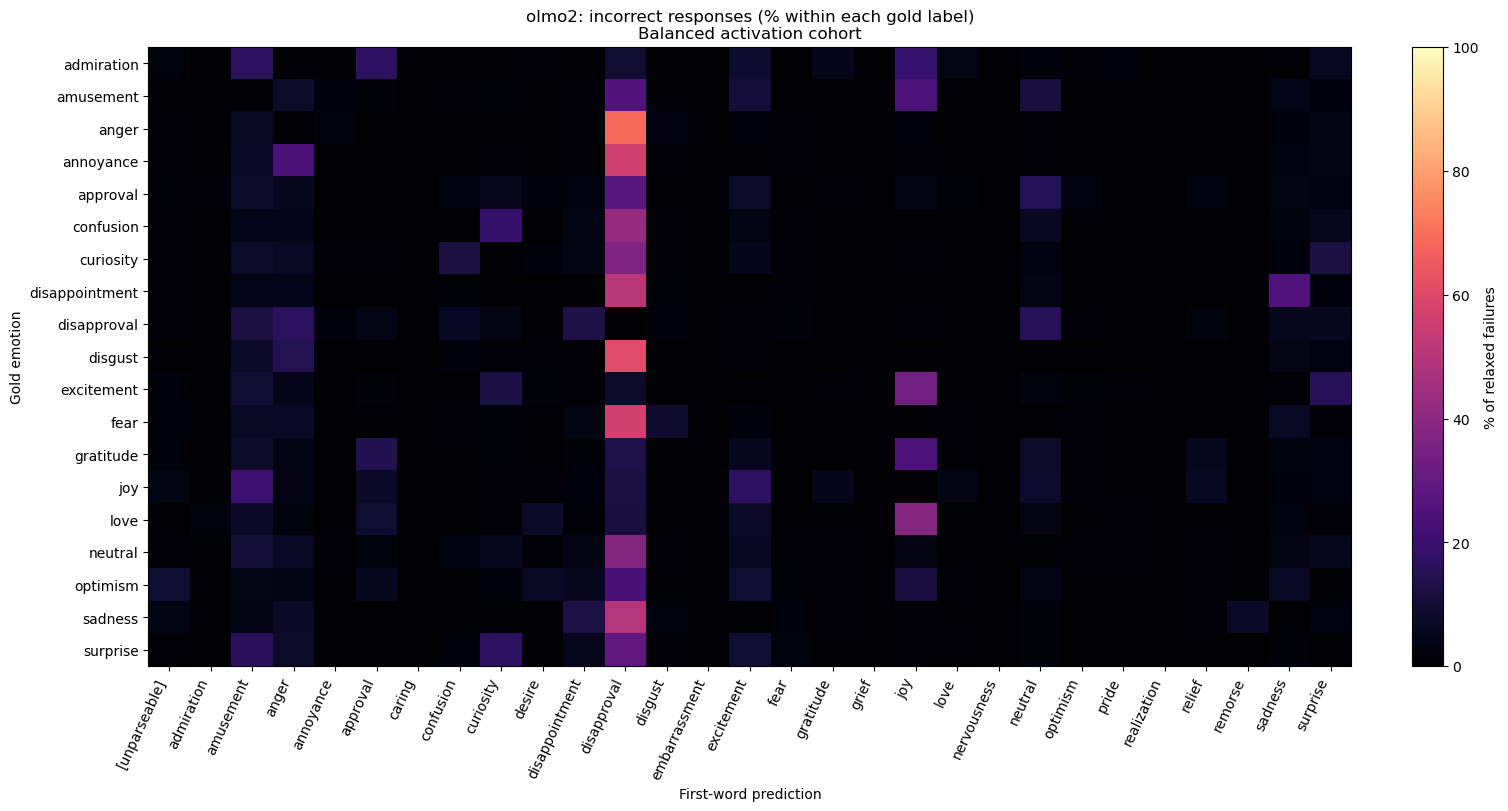

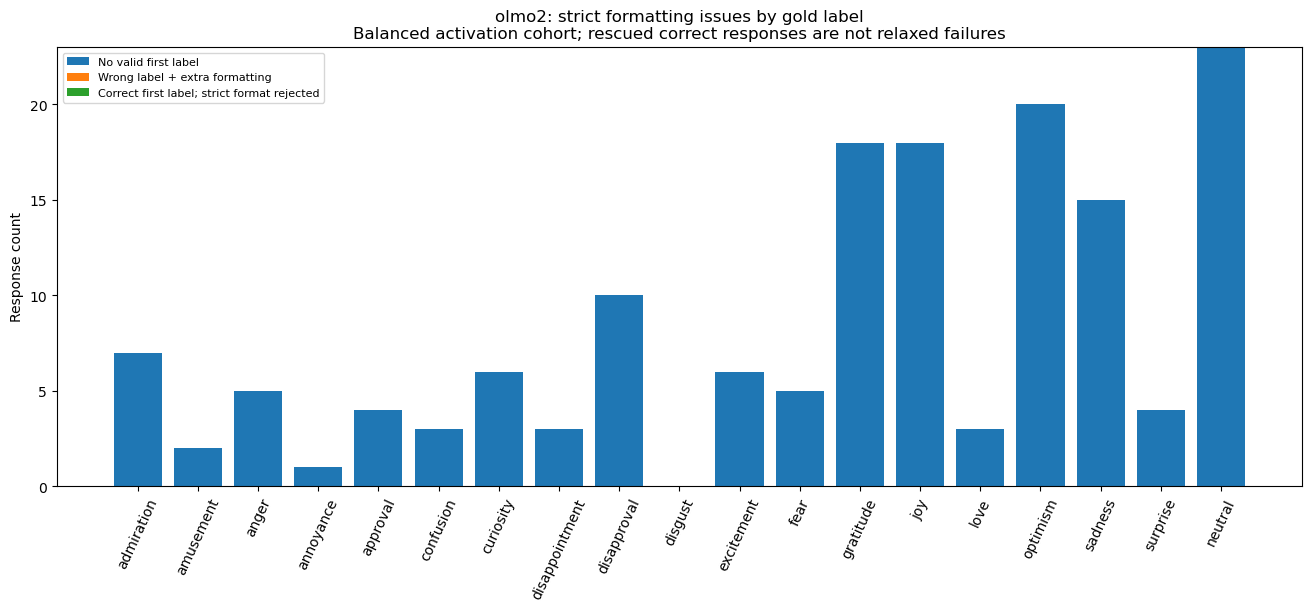

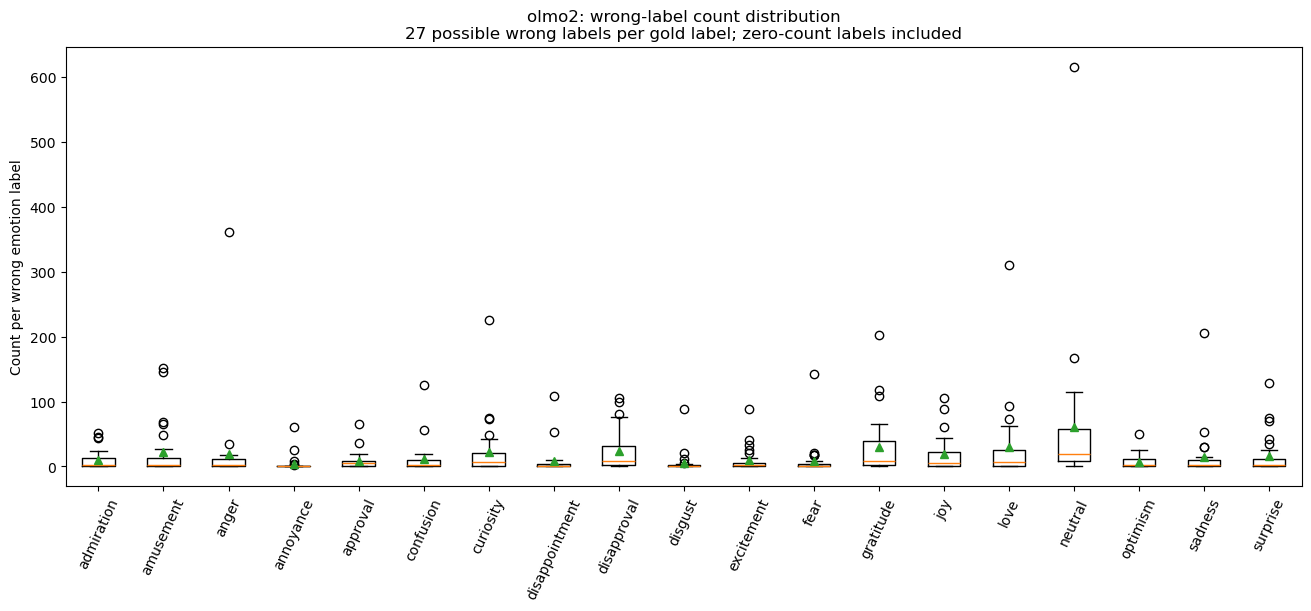

In [6]:
model = "olmo2"
distribution = pd.read_csv(CSV / "distribution.csv").query("model == @model")
wrong = distribution[(distribution.gold != distribution.prediction) & distribution.prediction.ne("[unparseable]")]
top = wrong[wrong["count"].eq(wrong.groupby("gold")["count"].transform("max")) & wrong["count"].gt(0)]
display(top[["gold", "prediction", "count", "pct_of_failures", "pct_of_wrong_labels"]].round(2))
display(pd.read_csv(CSV / "per_gold.csv").query("model == @model")[["gold", "available", "n", "incorrect", "unparseable", "strict_format_issue", "format_issue_among_failures", "wrong_label_with_format_issue", "rescued_correct", "unparseable_pct_of_failures"]].round(2))
display(pd.read_csv(CSV / "stats.csv").query("model == @model")[["gold", "min", "max", "mean", "median"]].round(3))
model_figures(CSV, model, PLOTS)


### olmo2: wrong-label histograms for every available gold label

Each categorical histogram has two panels: **response count** and **percentage among valid wrong-emotion responses for that gold label**. Percentages sum to 100% when at least one valid wrong label exists. The correct gold label is excluded; all 27 alternative emotions, including zero-count categories, are shown. Unparseable failures are counted in the title but excluded from this percentage denominator because they are not emotion labels. The earlier heatmap instead uses all relaxed failures as its denominator.

Labels without sampled records are listed explicitly rather than shown as zero-error histograms. These plots use `plot-ready/distribution.csv` and are saved under `analysis-report/plots/per-gold-histograms/olmo2/`.

**olmo2: gold labels without sampled response records:** caring, desire, embarrassment, grief, nervousness, pride, realization, relief, remorse. No histogram can be estimated for these labels; absence is not zero errors.

olmo2: per-gold histograms:   0%|          | 0/19 [00:00<?, ?label/s]

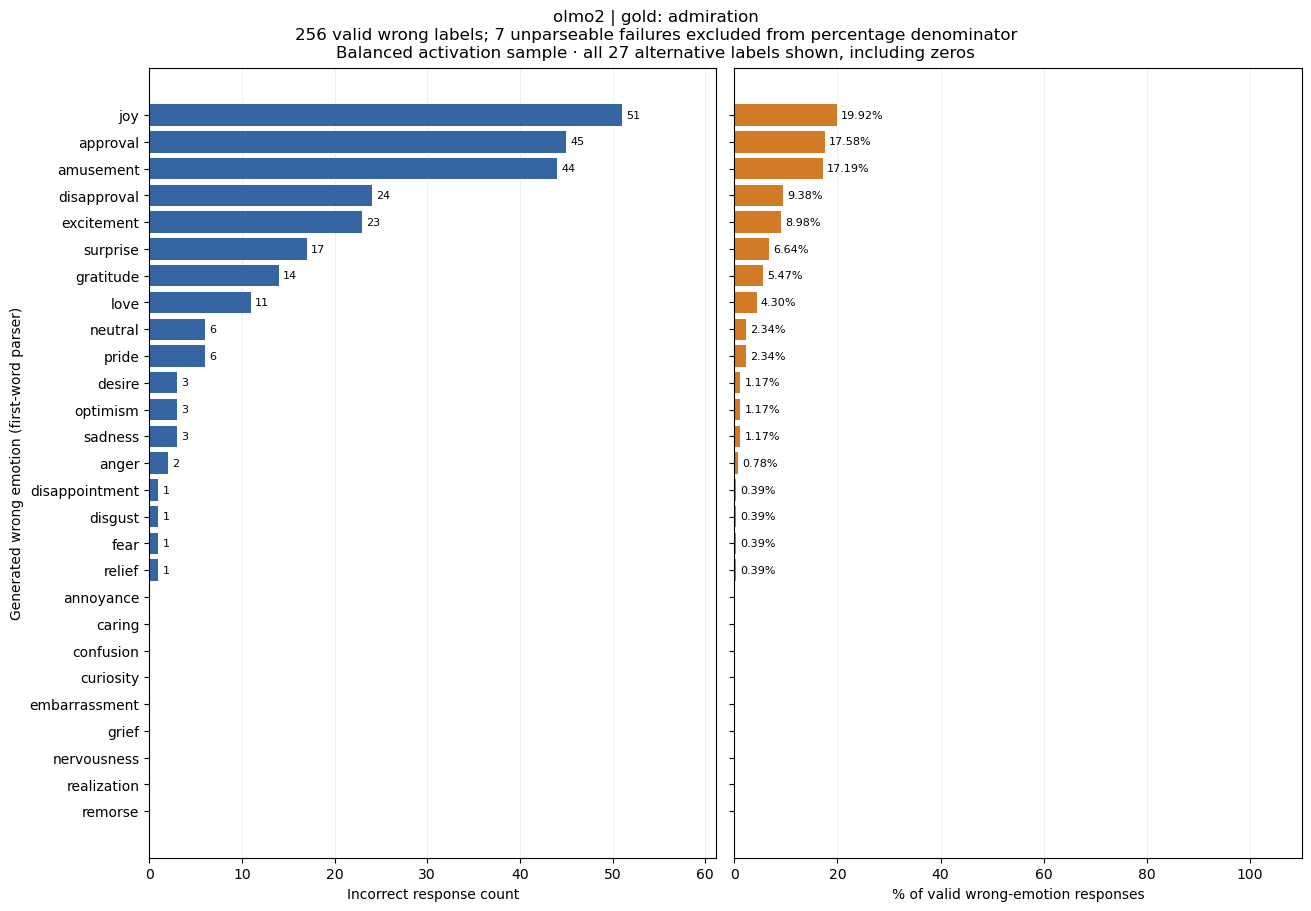

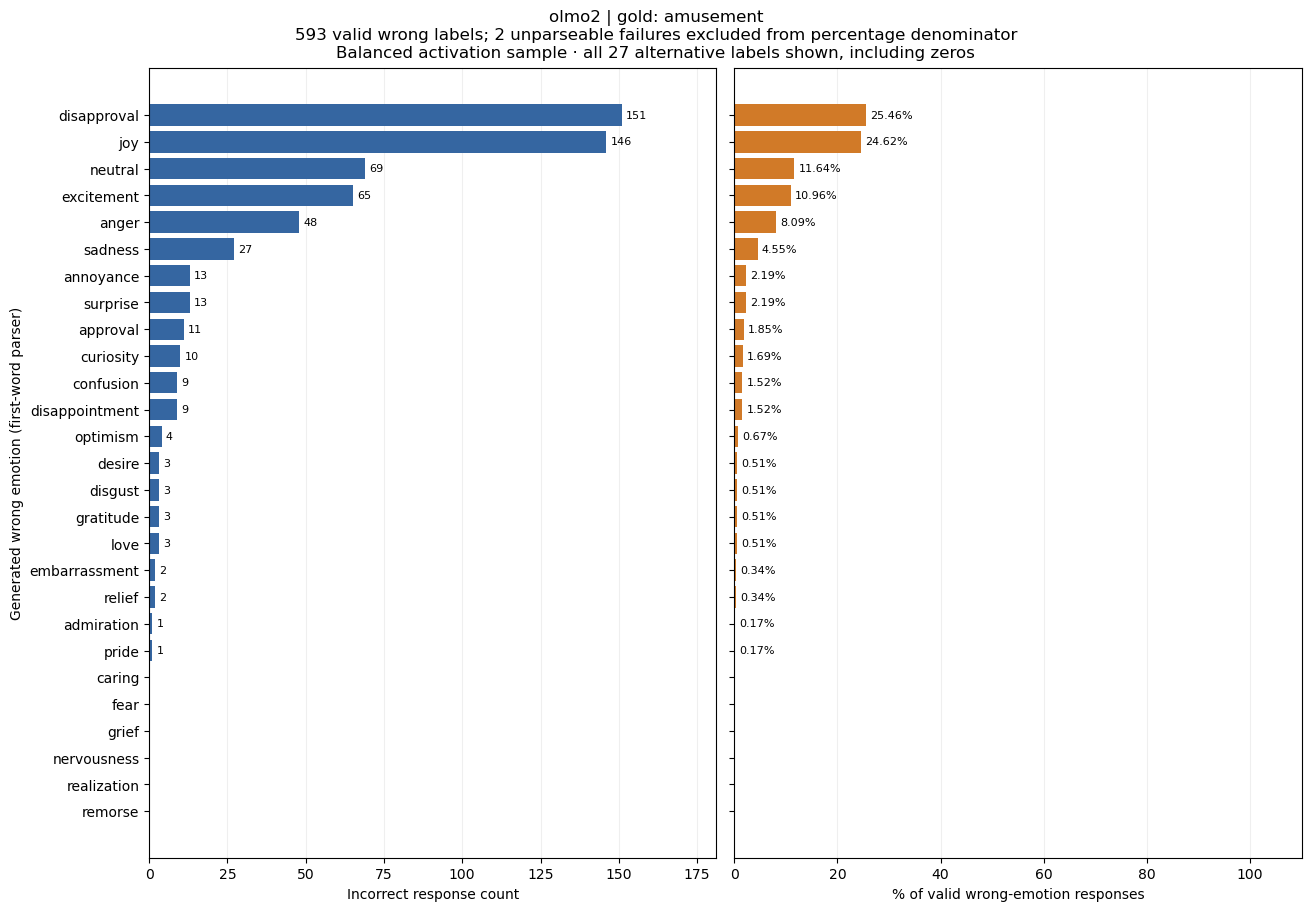

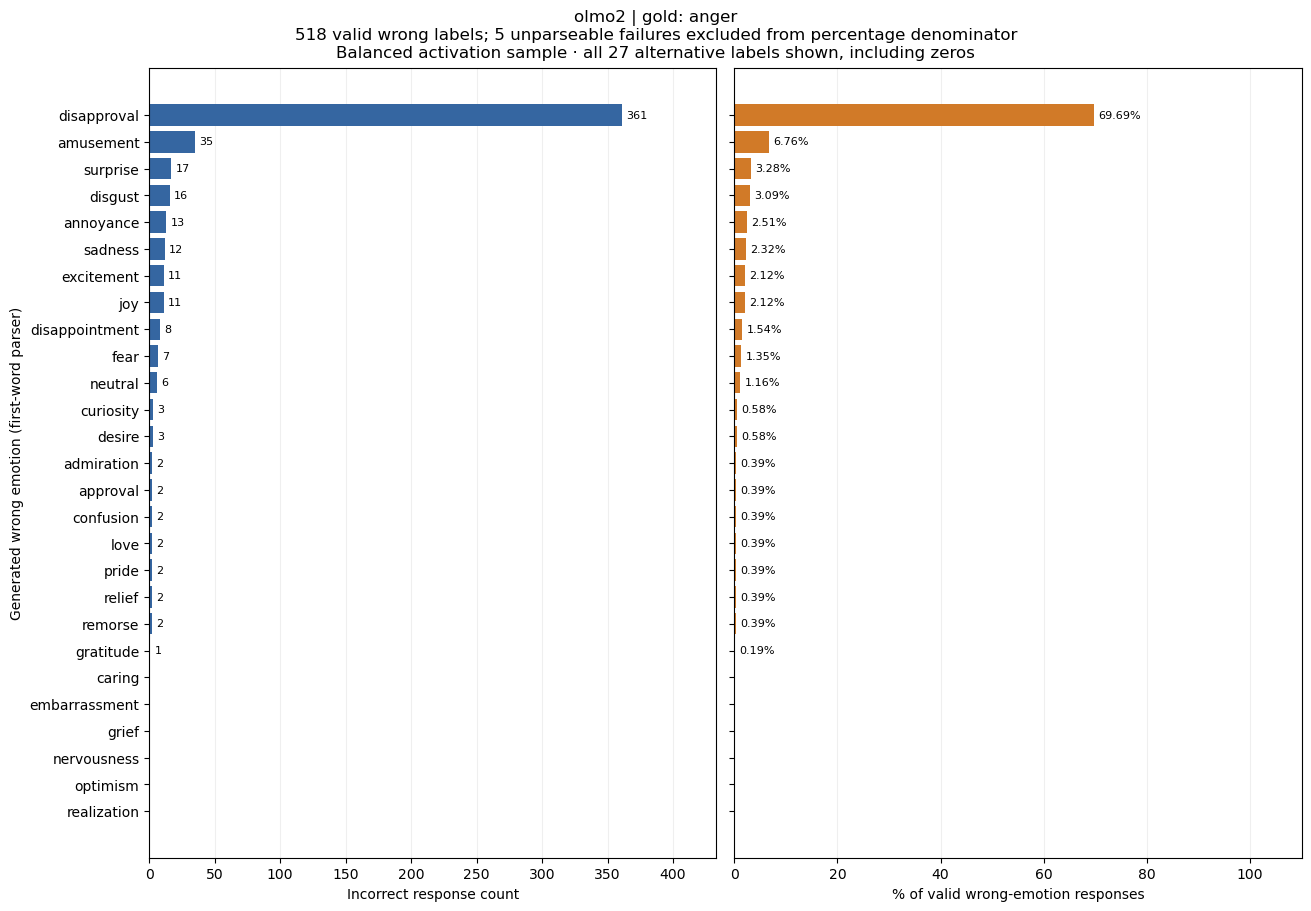

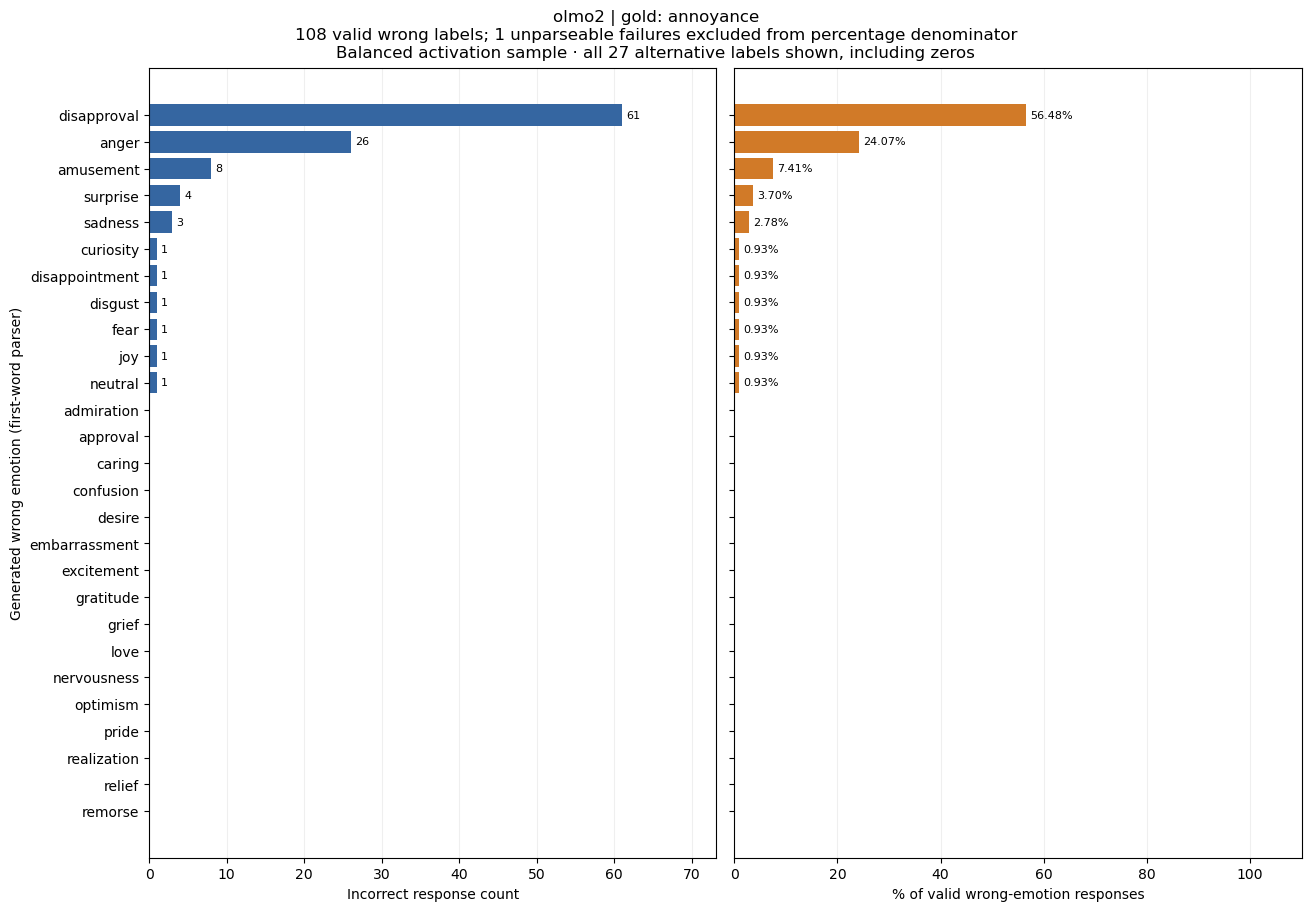

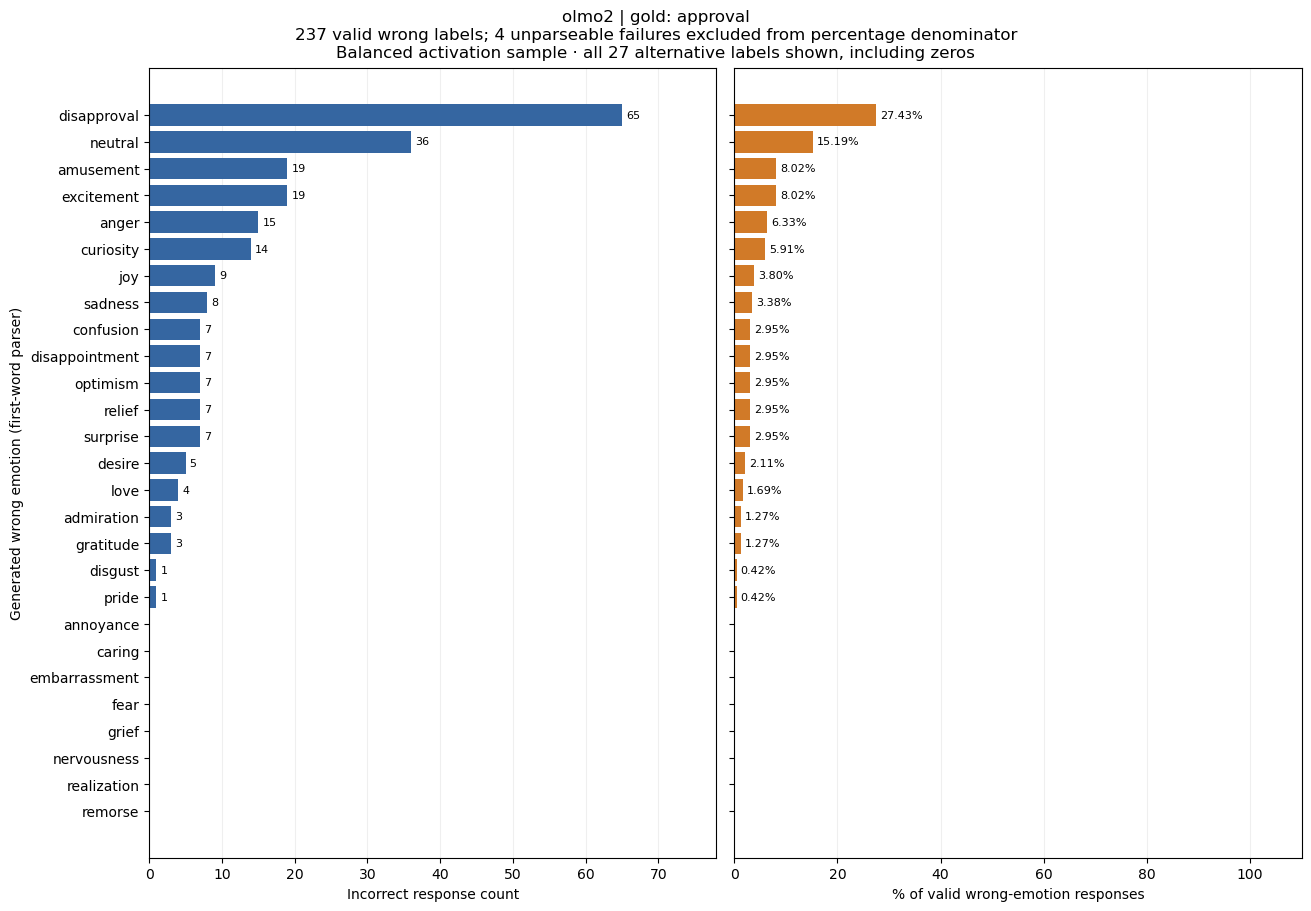

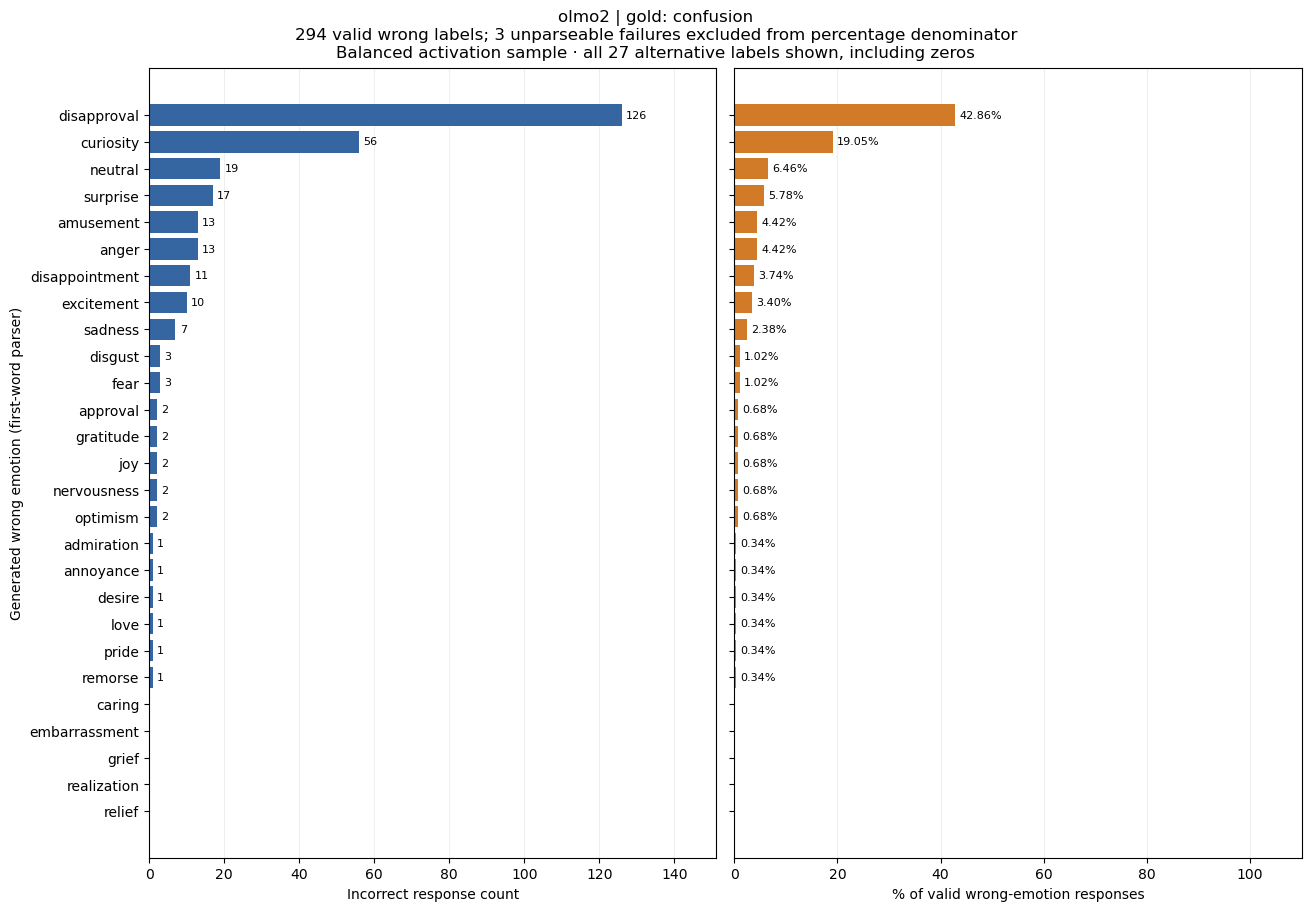

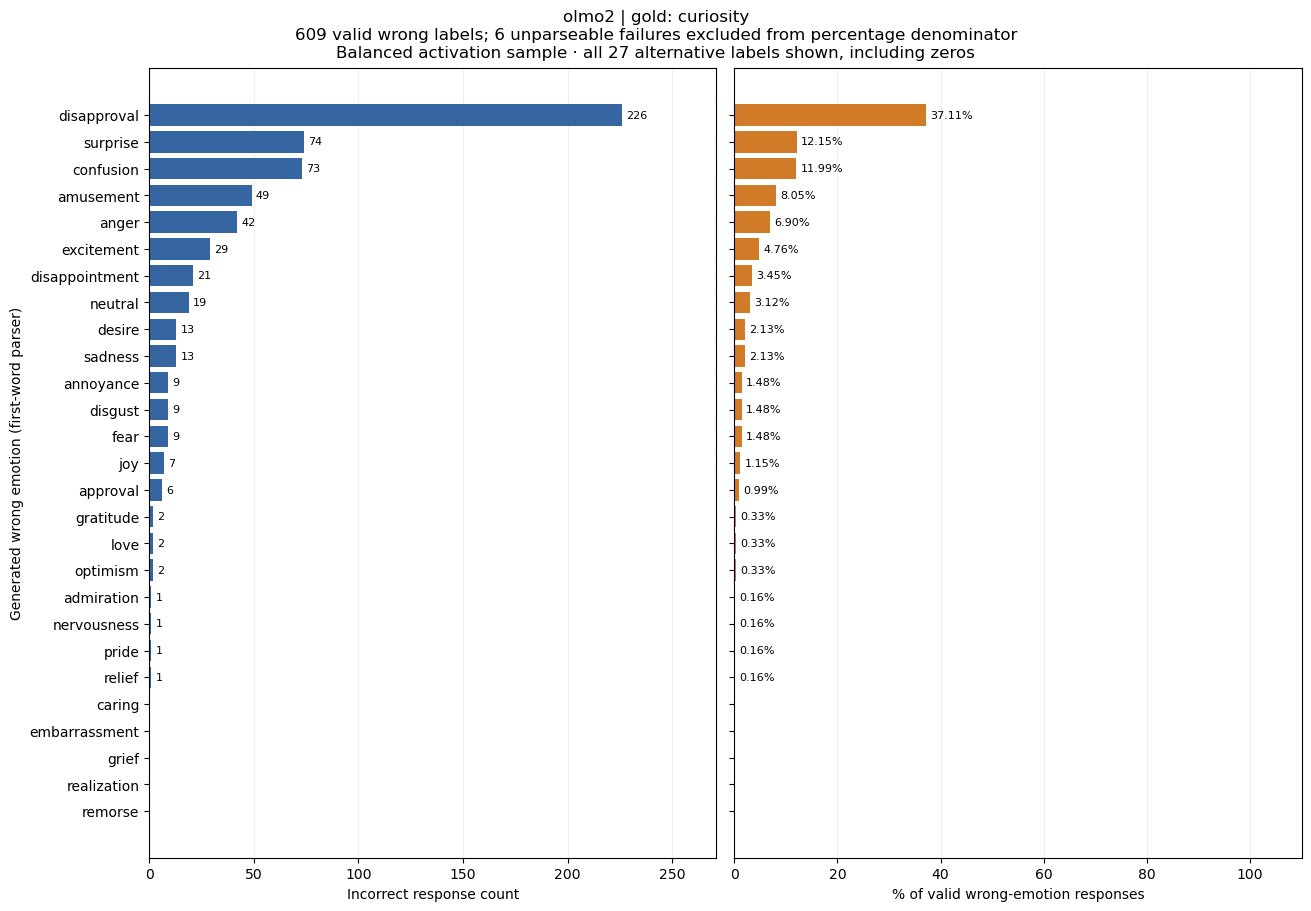

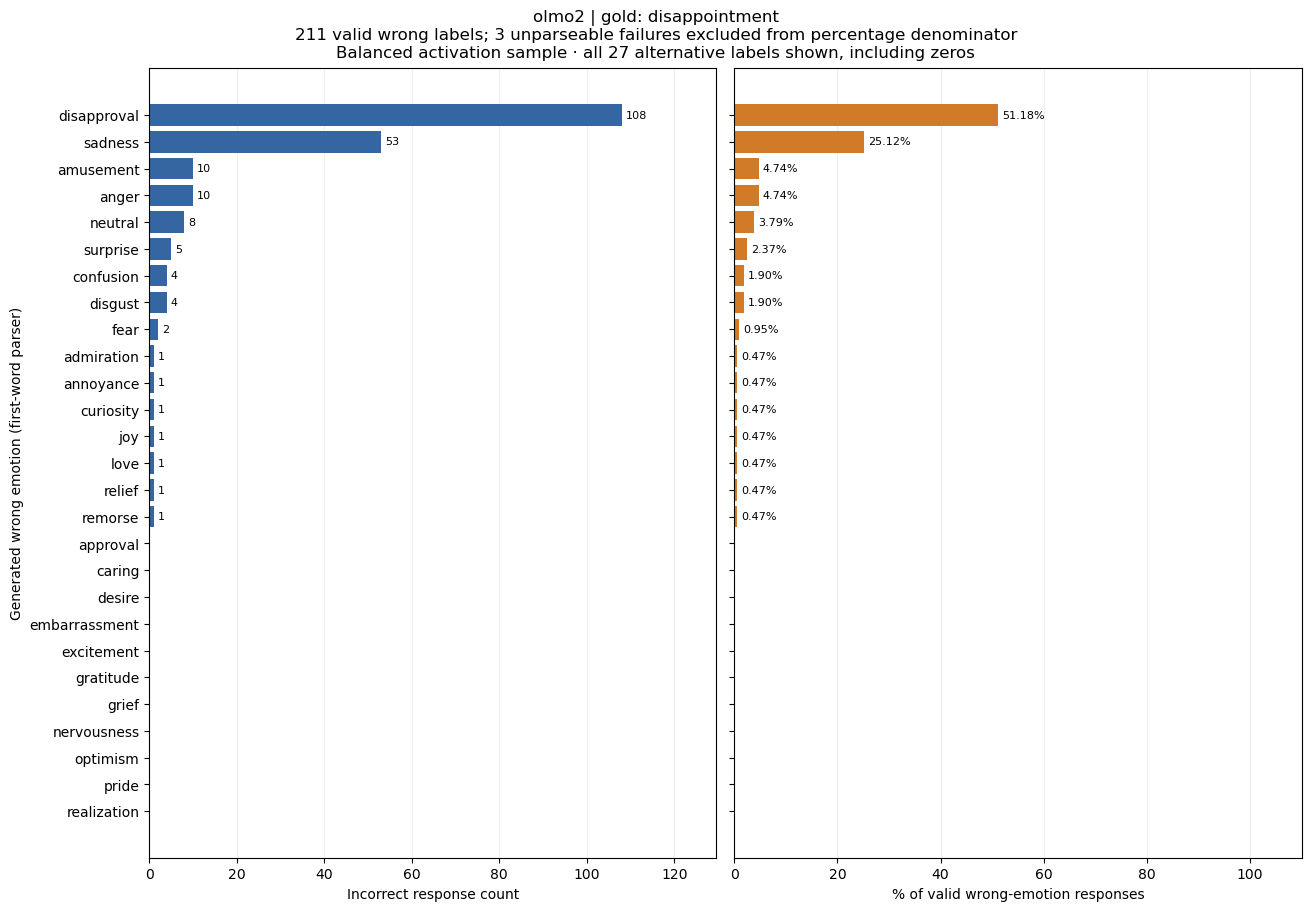

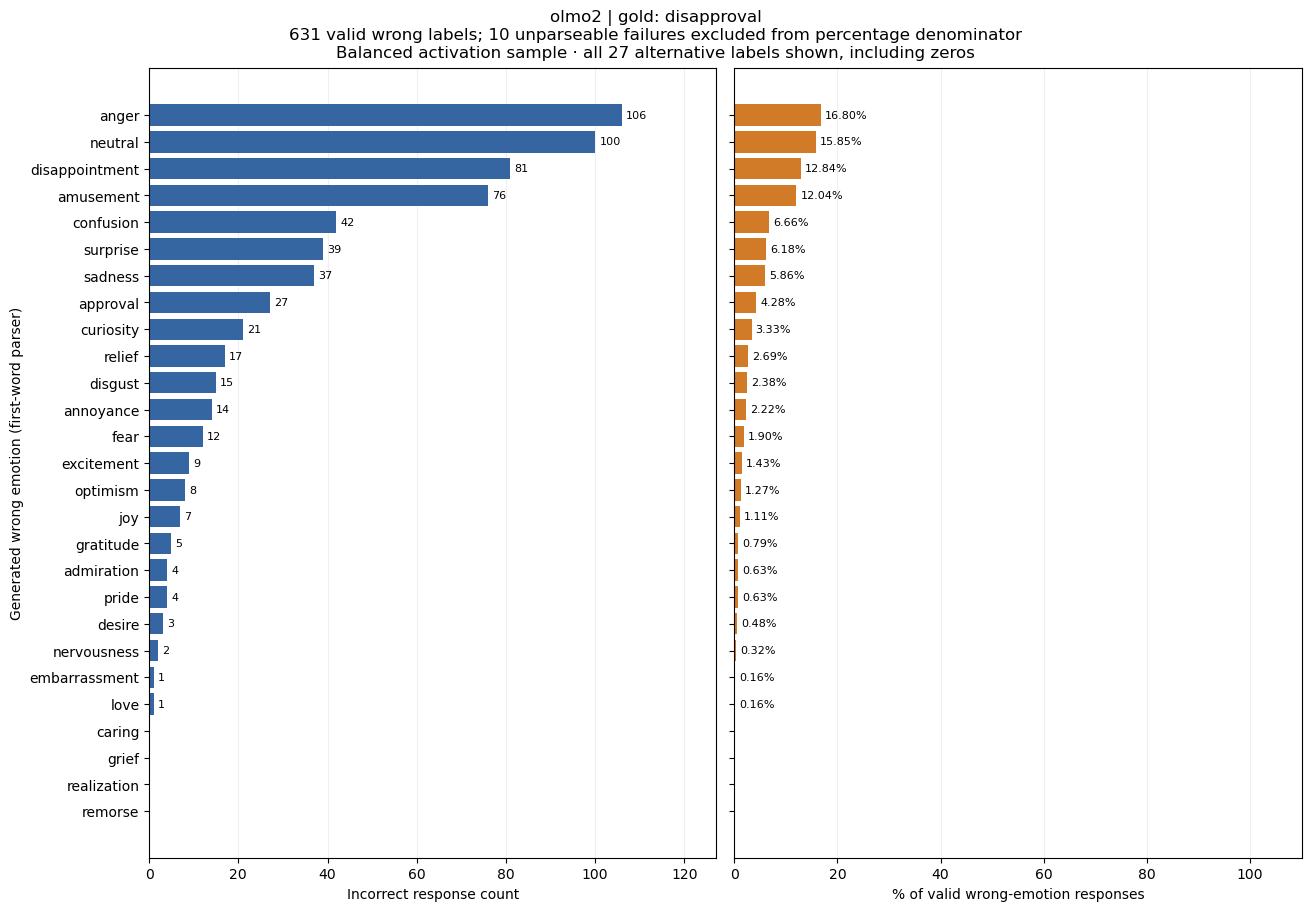

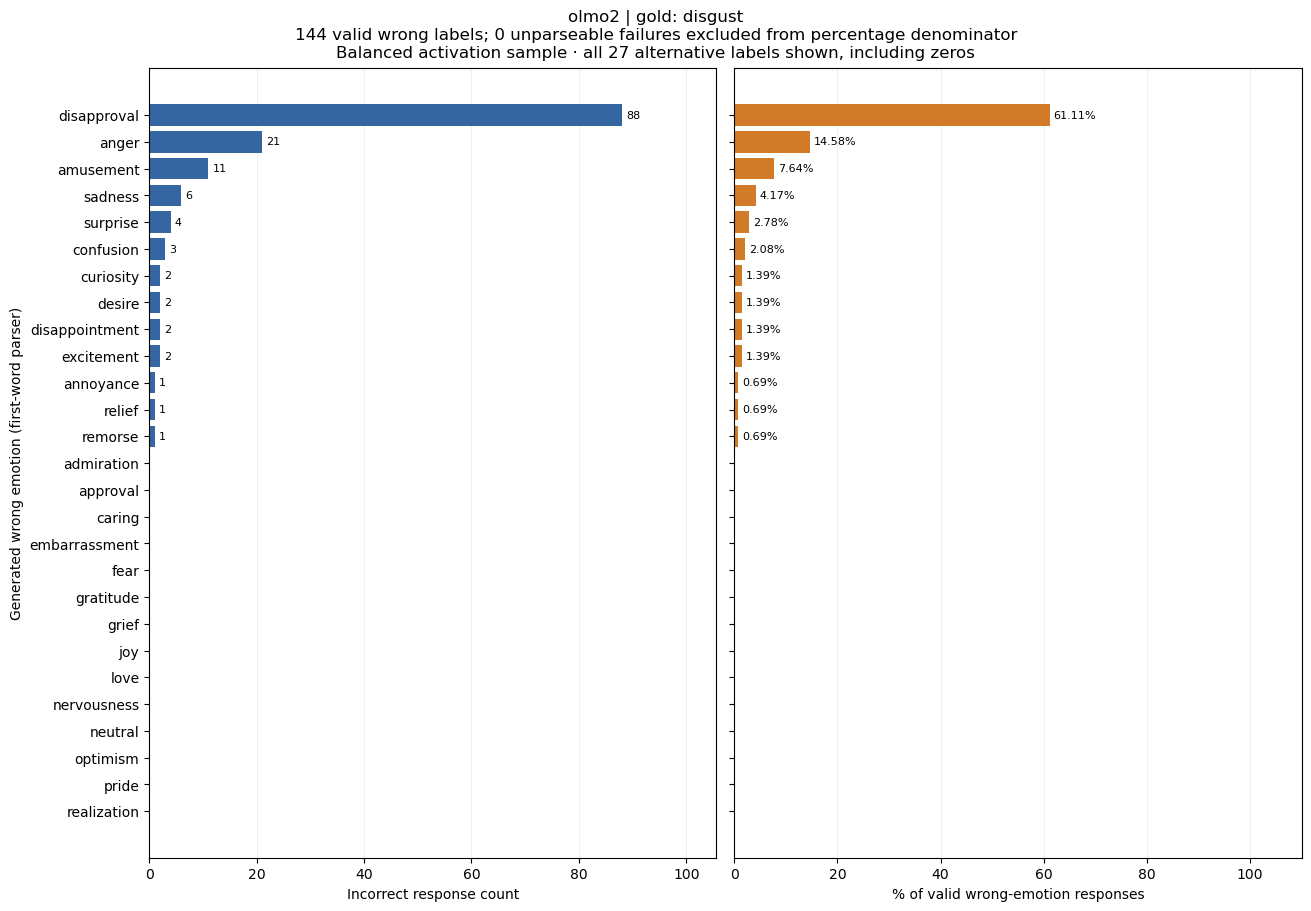

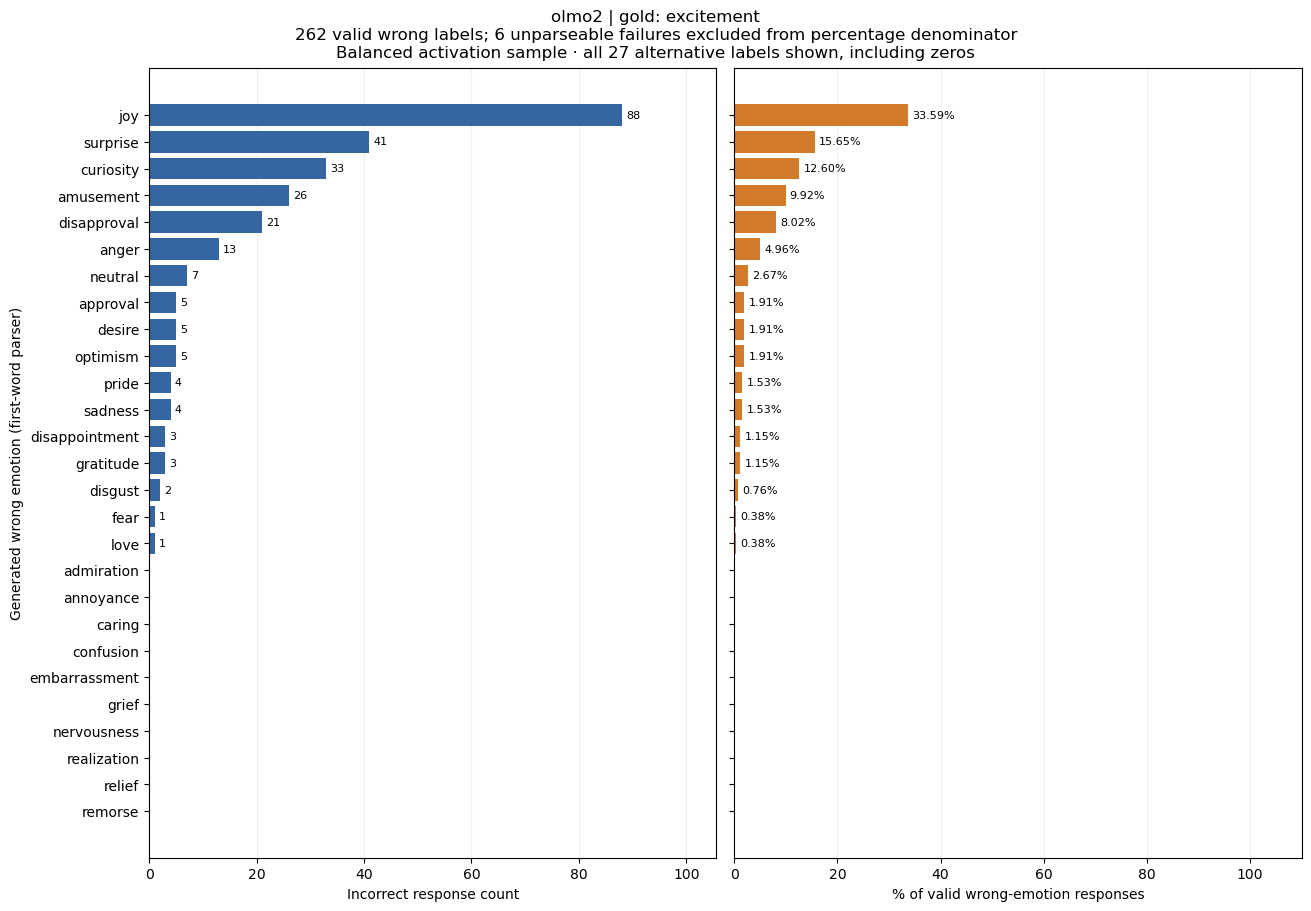

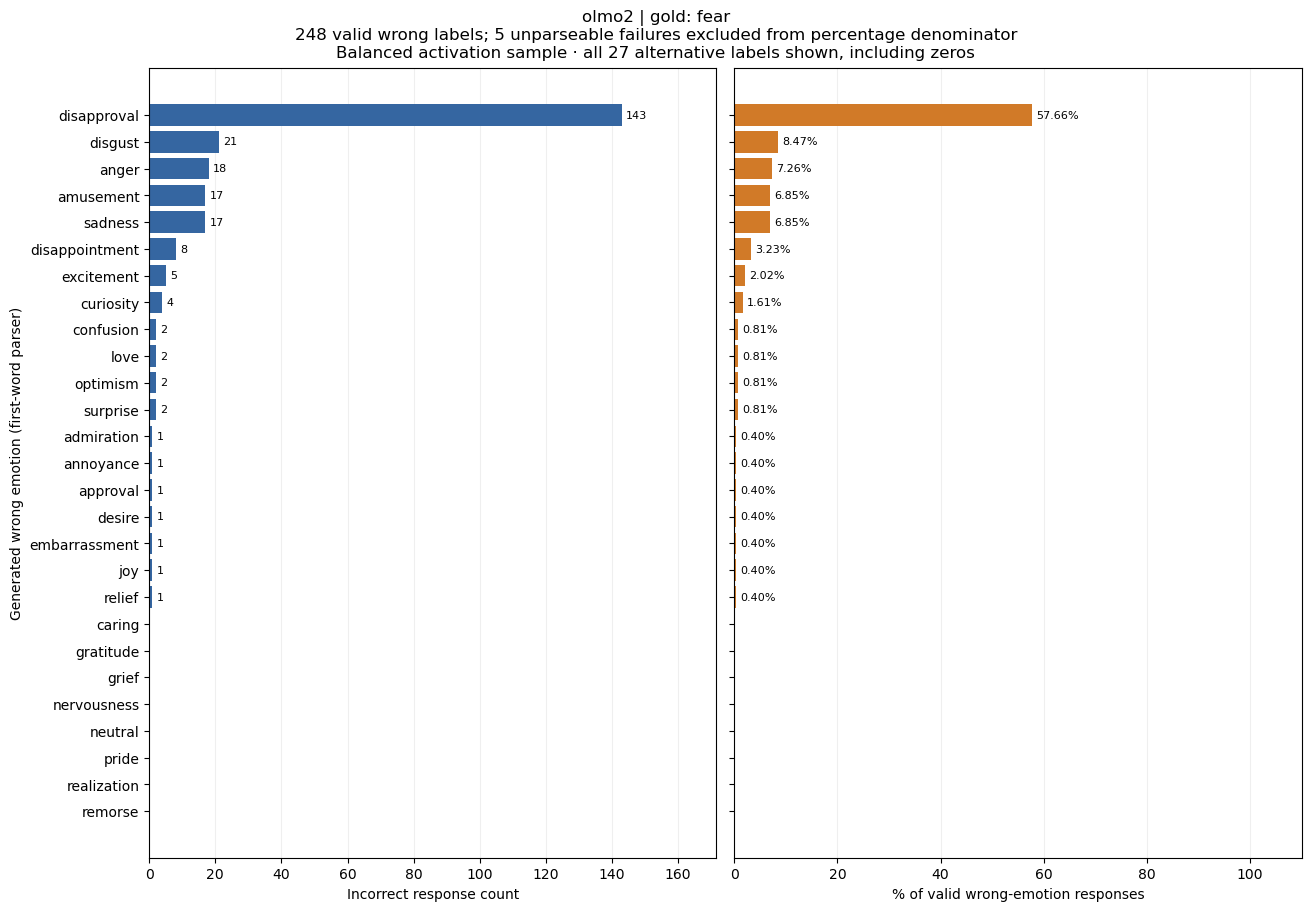

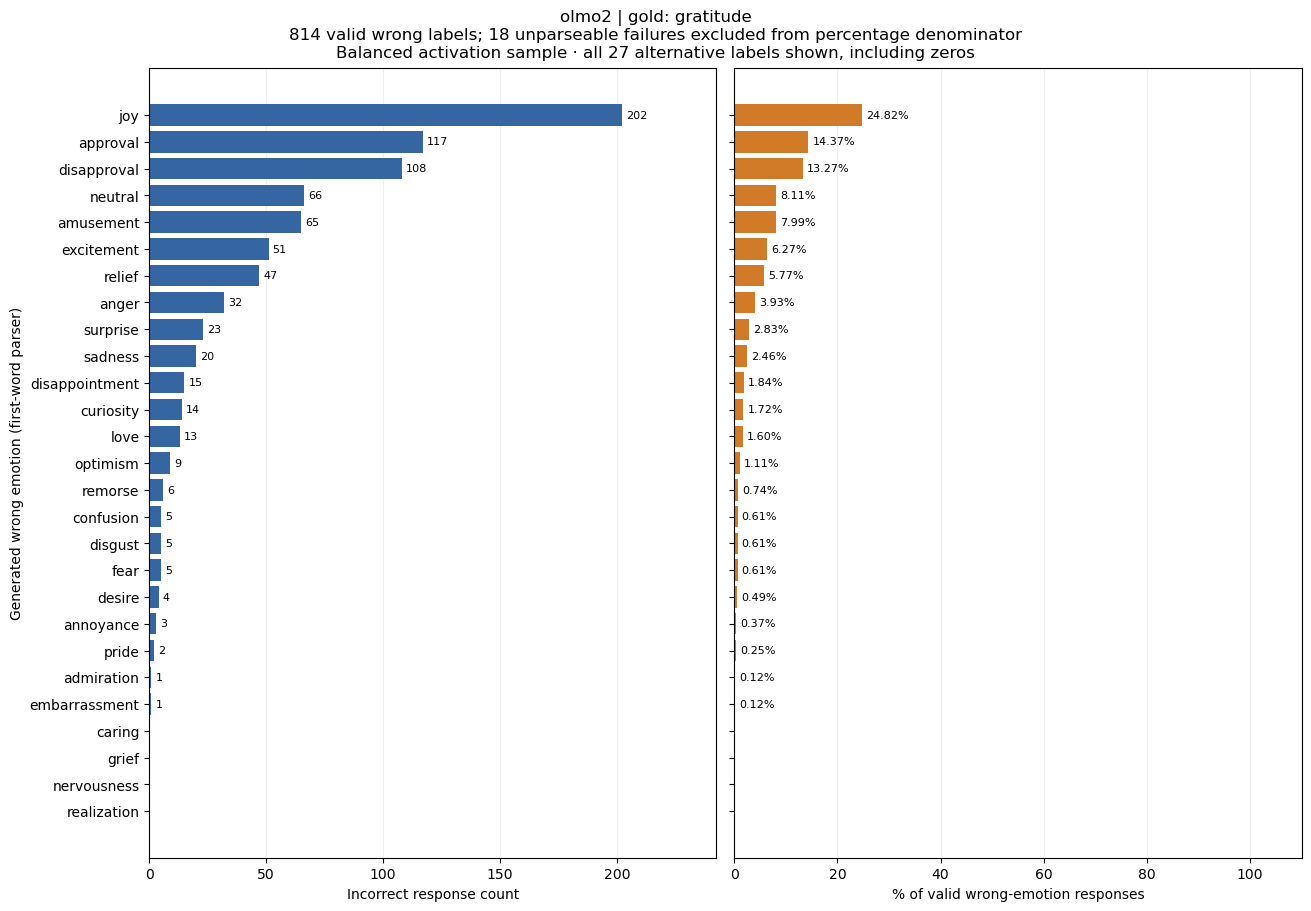

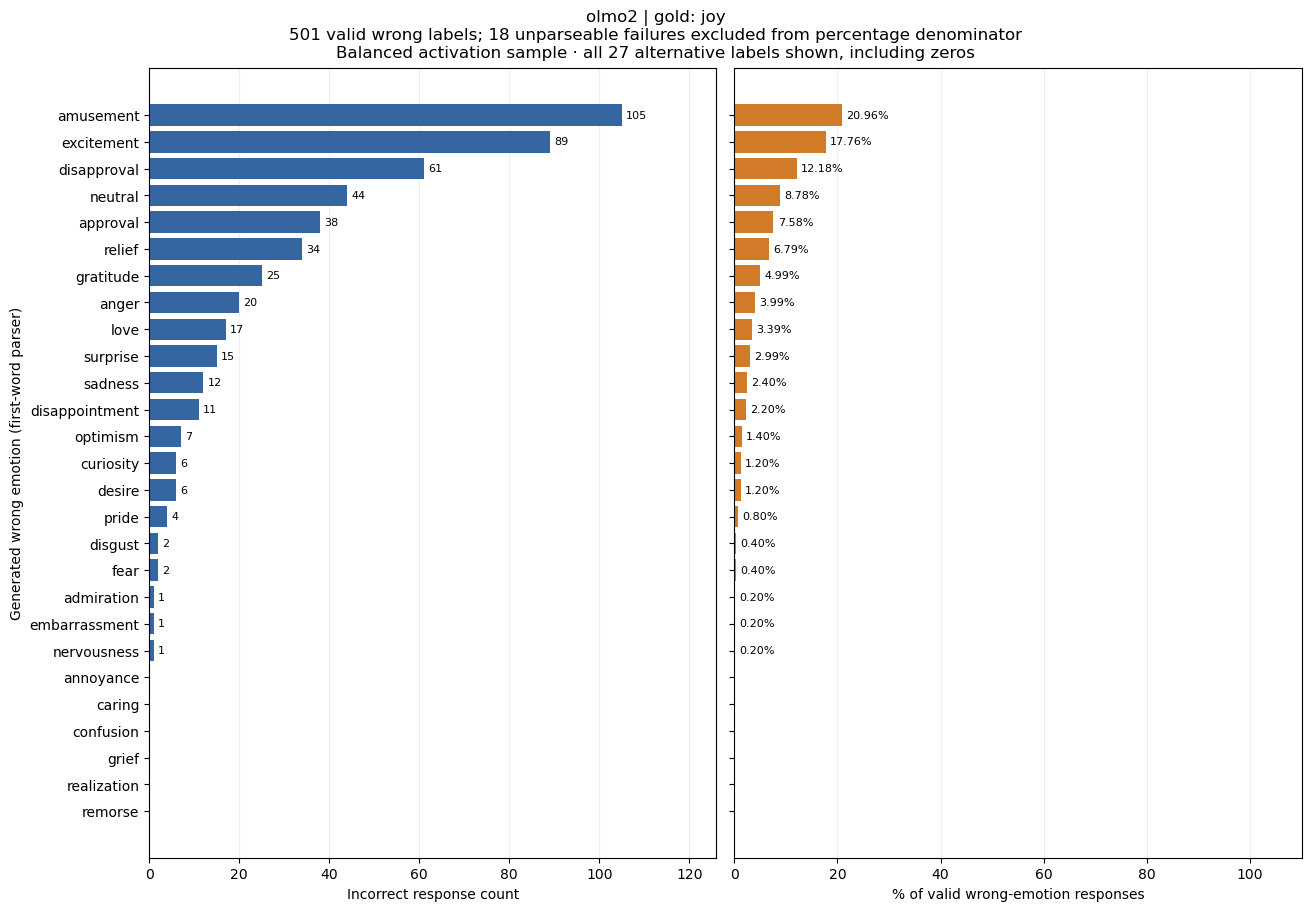

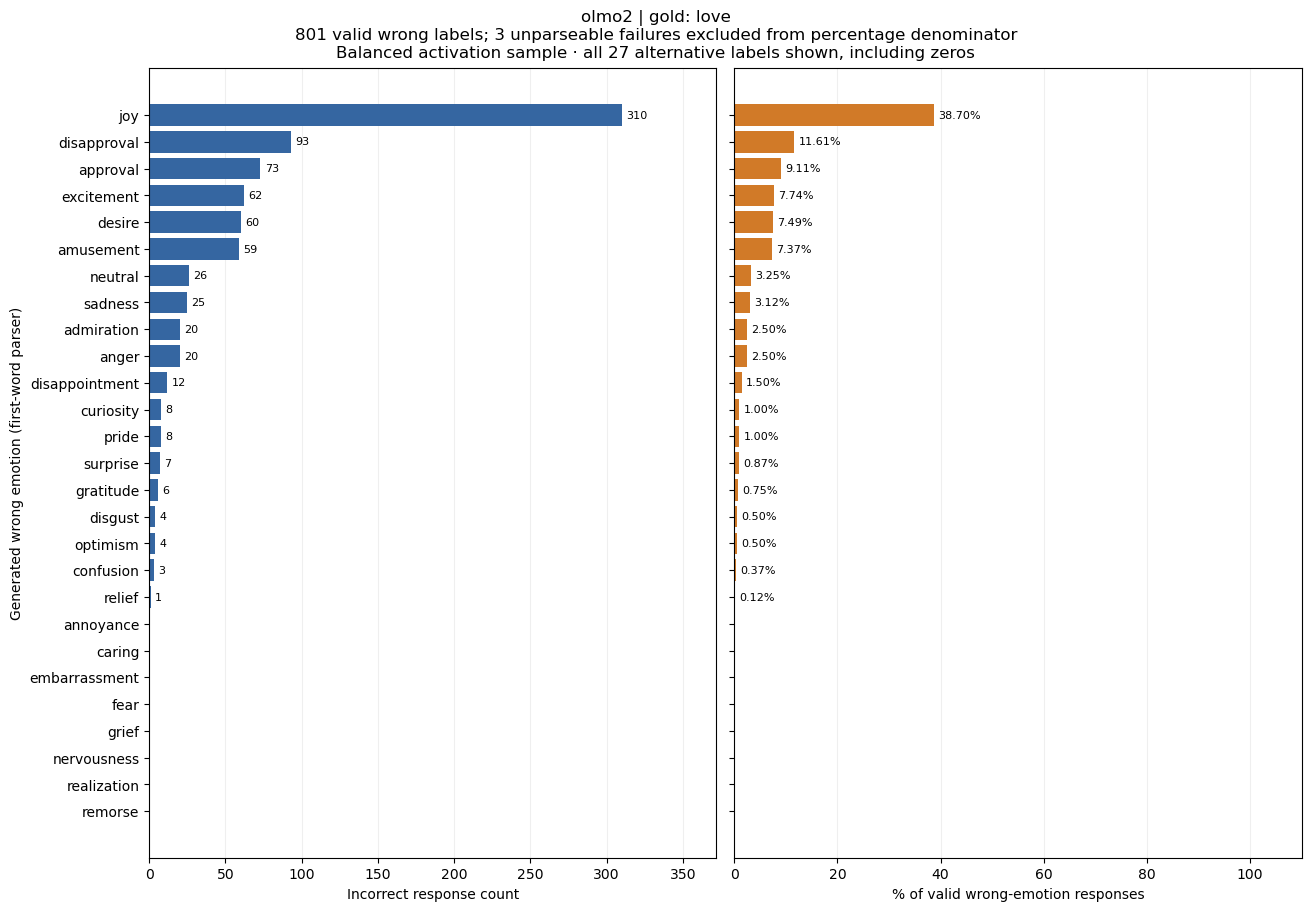

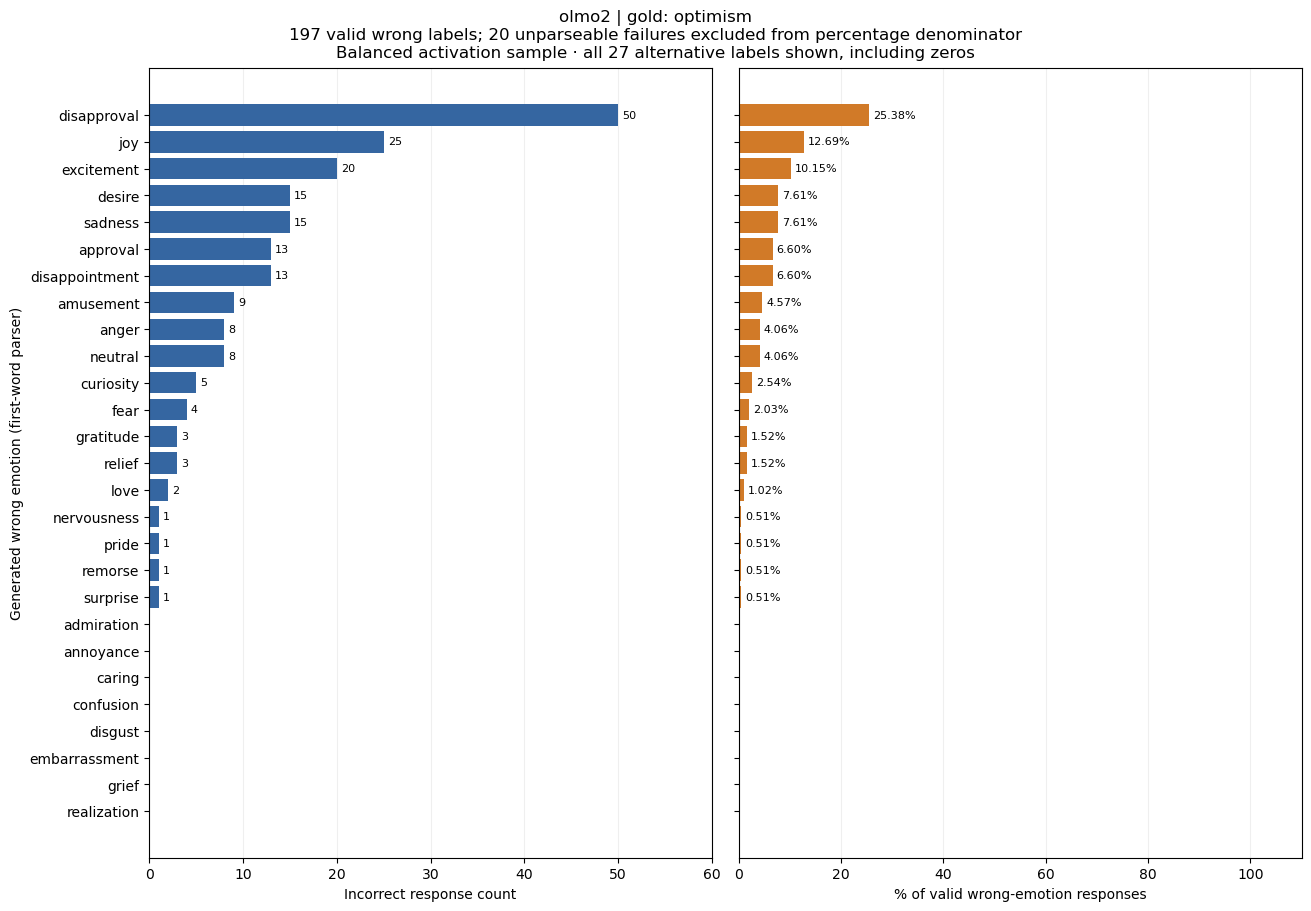

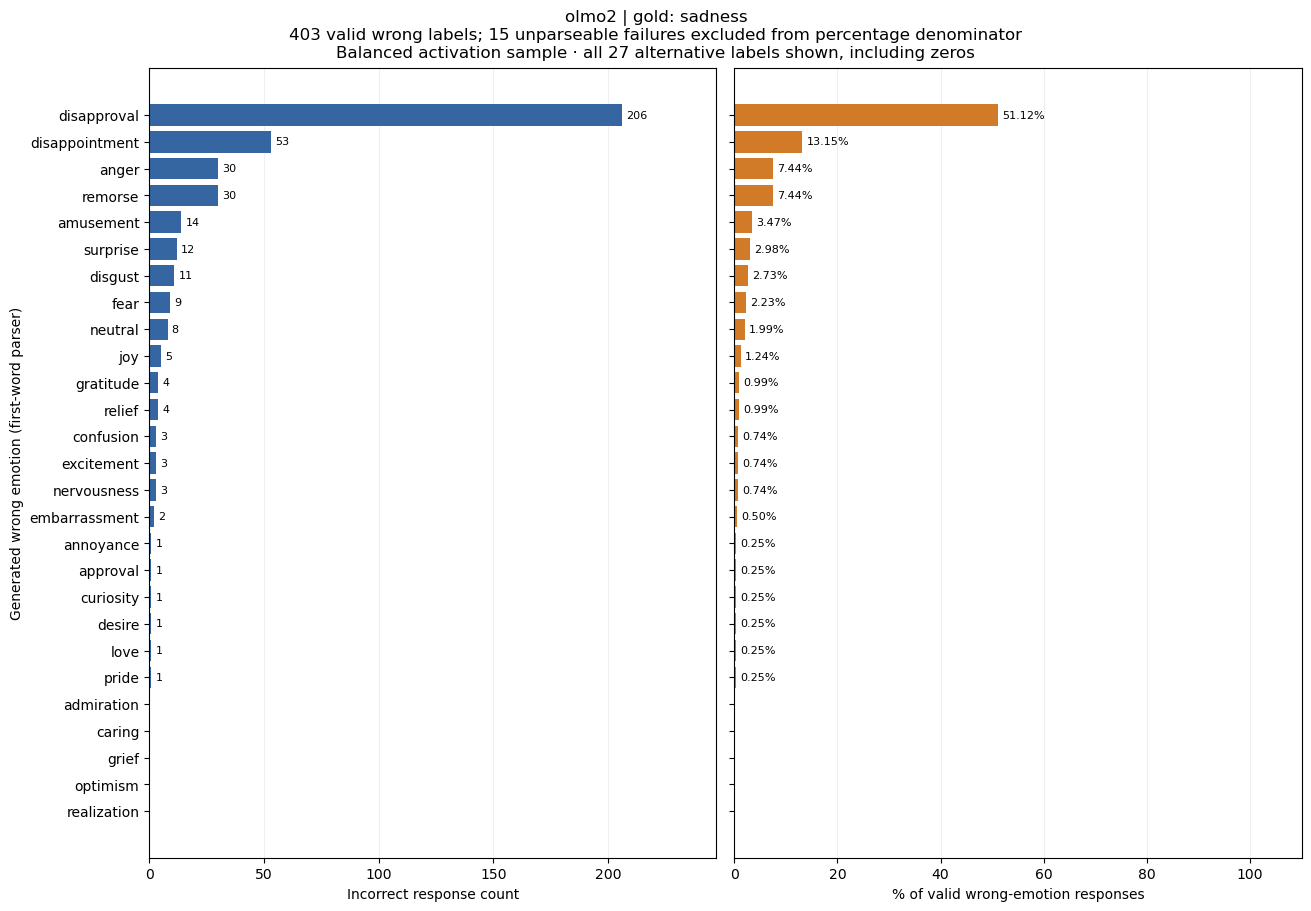

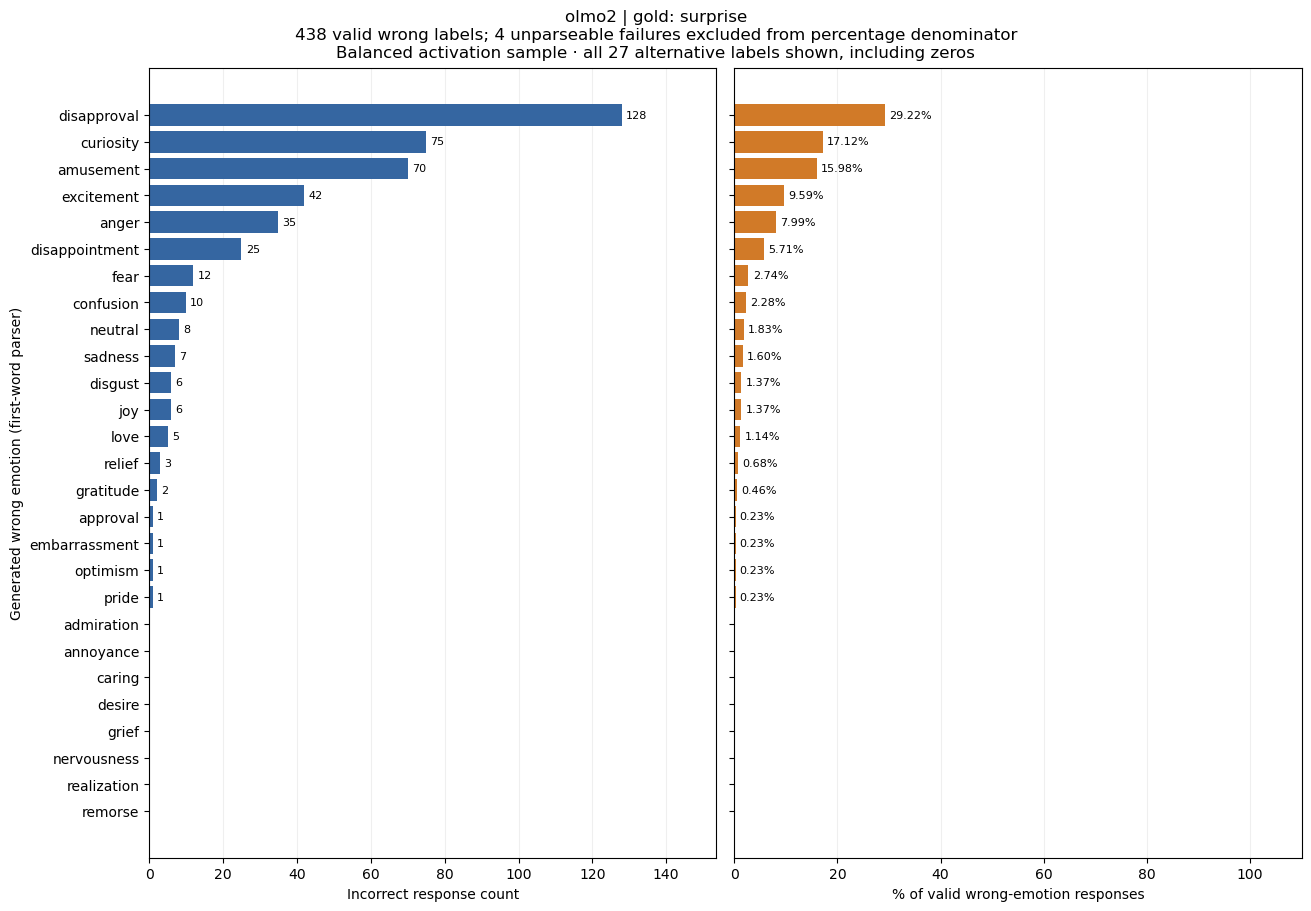

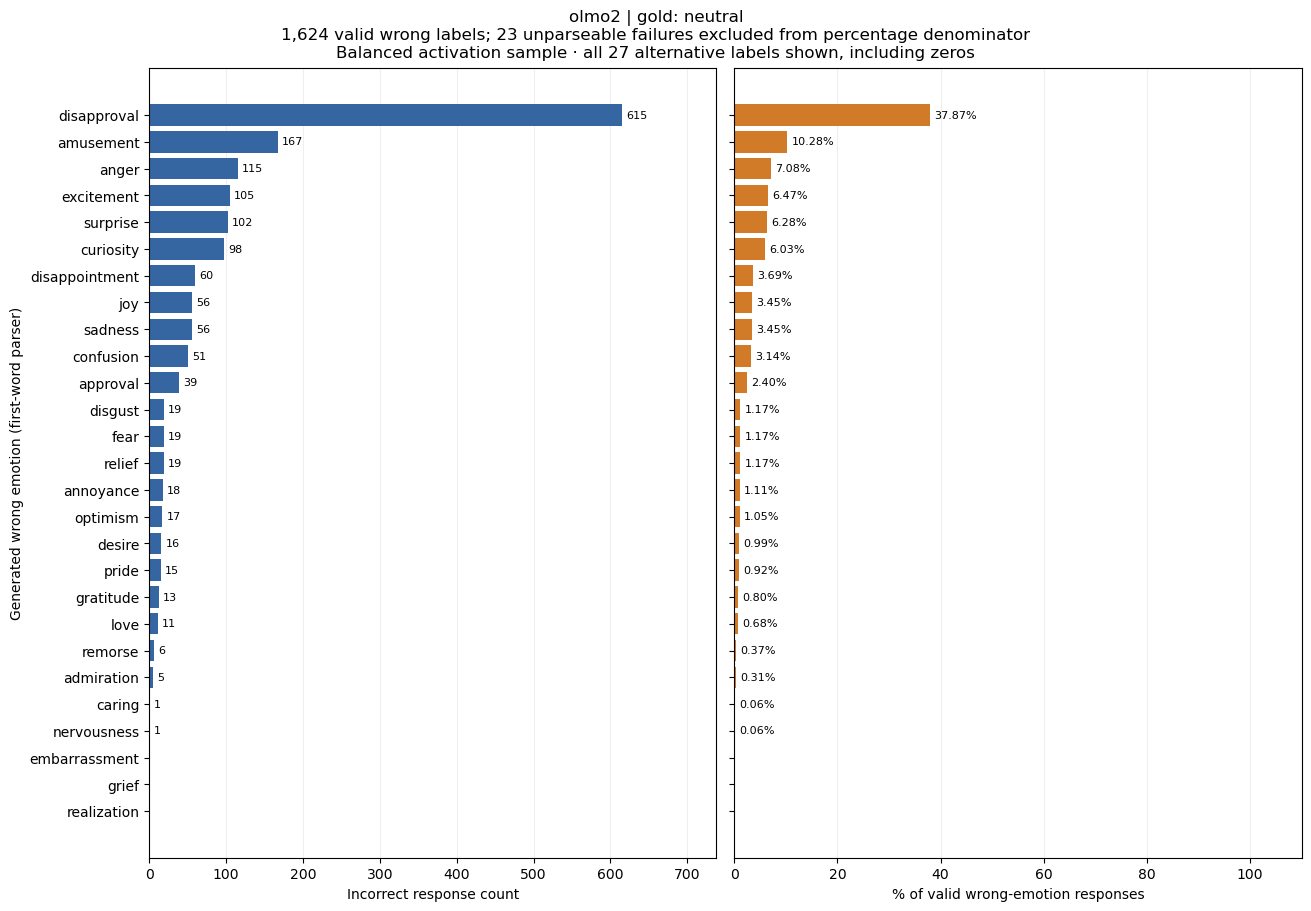

In [7]:
from affect_geometry.reporting.compat_exploration import wrong_label_histograms
wrong_label_histograms(CSV, "olmo2", PLOTS)

## apertus: sampled confusion and formatting
The first table gives each gold label's most common wrong emotion (ties retained), followed by full per-gold formatting counts and wrong-label count statistics. Missing sampled gold labels are marked `available=False`, with undefined diagnostics. The heatmap includes unparseable failures explicitly; the stacked bars distinguish rescued correct responses from remaining failures. Each per-gold box contains 27 wrong-emotion frequencies, including zeros.

,gold,prediction,count,pct_of_failures,pct_of_wrong_labels
1032,admiration,joy,67,32.52,33.17
1054,amusement,disapproval,210,23.92,25.21
1083,anger,disapproval,268,50.28,50.95
1112,annoyance,disapproval,67,37.85,39.64
1141,approval,disapproval,33,26.61,27.05
1170,confusion,disapproval,57,26.89,27.80
1199,curiosity,disapproval,117,27.40,27.53
1228,disappointment,disapproval,179,43.34,45.20
1256,disapproval,disappointment,307,37.76,39.26
1286,disgust,disapproval,98,47.80,48.04


,gold,available,n,incorrect,unparseable,strict_format_issue,format_issue_among_failures,wrong_label_with_format_issue,rescued_correct,unparseable_pct_of_failures
56,admiration,True,412,206.0,4.0,4.0,4.0,0.0,0.0,1.94
57,amusement,True,1756,878.0,45.0,45.0,45.0,0.0,0.0,5.13
58,anger,True,1066,533.0,7.0,7.0,7.0,0.0,0.0,1.31
59,annoyance,True,354,177.0,8.0,8.0,8.0,0.0,0.0,4.52
60,approval,True,248,124.0,2.0,2.0,2.0,0.0,0.0,1.61
61,caring,False,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
62,confusion,True,424,212.0,7.0,7.0,7.0,0.0,0.0,3.30
63,curiosity,True,854,427.0,2.0,2.0,2.0,0.0,0.0,0.47
64,desire,False,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
65,disappointment,True,826,413.0,17.0,17.0,17.0,0.0,0.0,4.12


,gold,min,max,mean,median
35,admiration,0,67,7.481,3.0
36,amusement,0,210,30.852,4.0
37,anger,0,268,19.481,3.0
38,annoyance,0,67,6.259,1.0
39,approval,0,33,4.519,2.0
40,confusion,0,57,7.593,2.0
41,curiosity,0,117,15.741,4.0
42,disappointment,0,179,14.667,4.0
43,disapproval,0,307,28.963,10.0
44,disgust,0,98,7.556,1.0


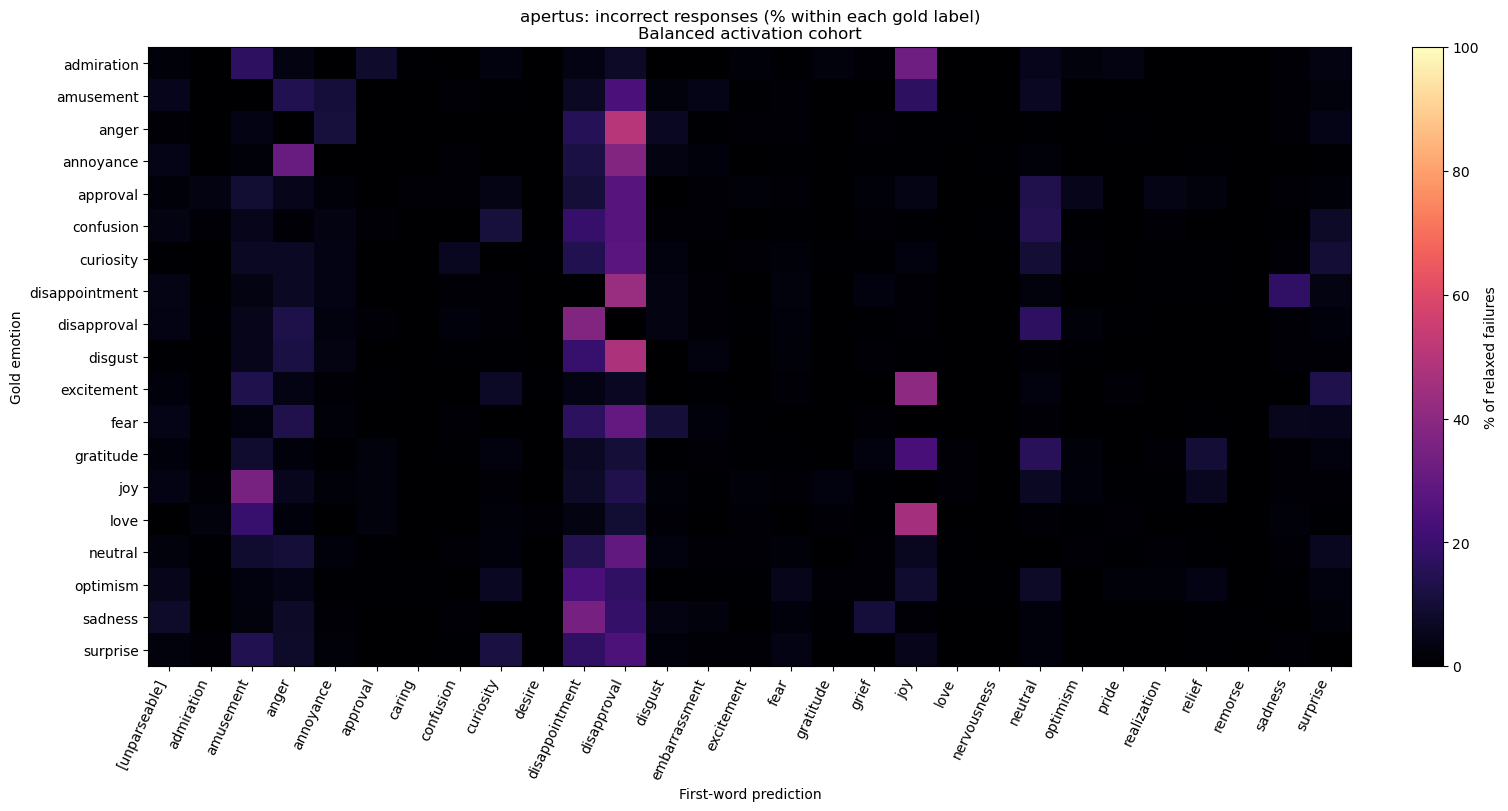

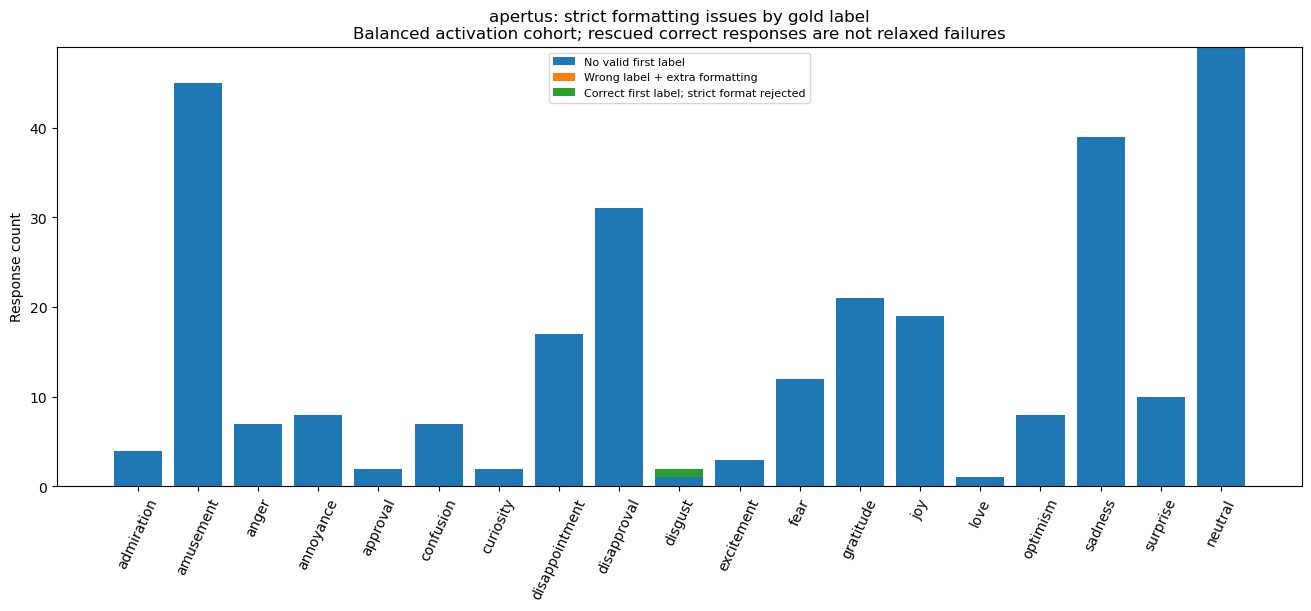

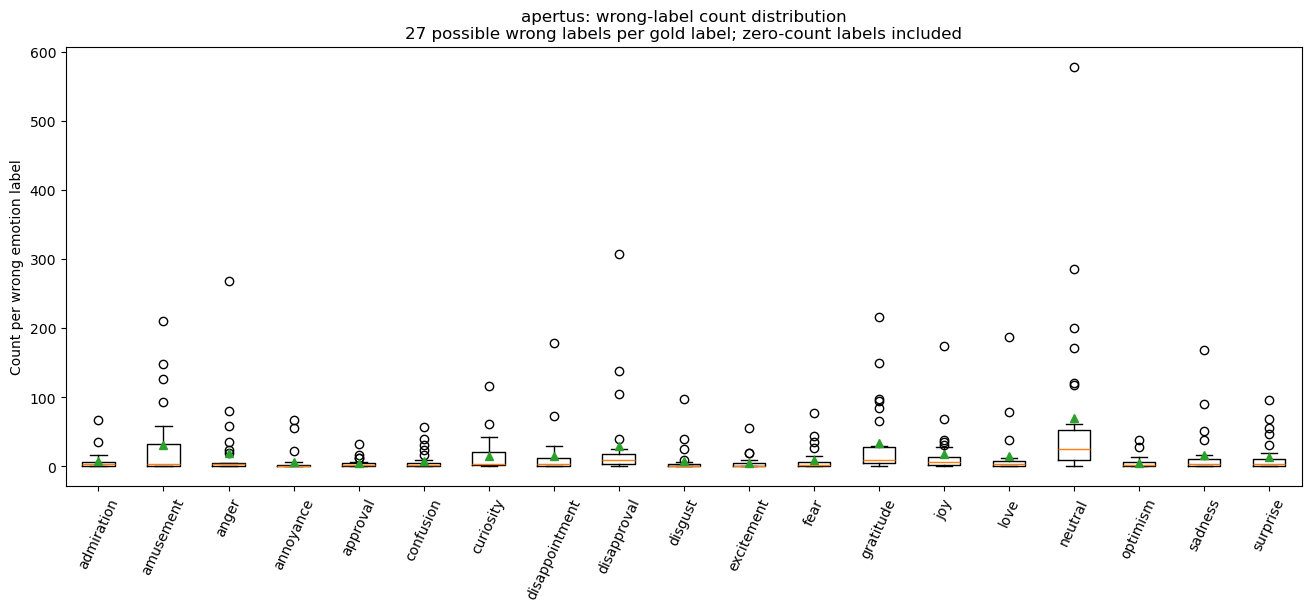

In [8]:
model = "apertus"
distribution = pd.read_csv(CSV / "distribution.csv").query("model == @model")
wrong = distribution[(distribution.gold != distribution.prediction) & distribution.prediction.ne("[unparseable]")]
top = wrong[wrong["count"].eq(wrong.groupby("gold")["count"].transform("max")) & wrong["count"].gt(0)]
display(top[["gold", "prediction", "count", "pct_of_failures", "pct_of_wrong_labels"]].round(2))
display(pd.read_csv(CSV / "per_gold.csv").query("model == @model")[["gold", "available", "n", "incorrect", "unparseable", "strict_format_issue", "format_issue_among_failures", "wrong_label_with_format_issue", "rescued_correct", "unparseable_pct_of_failures"]].round(2))
display(pd.read_csv(CSV / "stats.csv").query("model == @model")[["gold", "min", "max", "mean", "median"]].round(3))
model_figures(CSV, model, PLOTS)


### apertus: wrong-label histograms for every available gold label

Each categorical histogram has two panels: **response count** and **percentage among valid wrong-emotion responses for that gold label**. Percentages sum to 100% when at least one valid wrong label exists. The correct gold label is excluded; all 27 alternative emotions, including zero-count categories, are shown. Unparseable failures are counted in the title but excluded from this percentage denominator because they are not emotion labels. The earlier heatmap instead uses all relaxed failures as its denominator.

Labels without sampled records are listed explicitly rather than shown as zero-error histograms. These plots use `plot-ready/distribution.csv` and are saved under `analysis-report/plots/per-gold-histograms/apertus/`.

**apertus: gold labels without sampled response records:** caring, desire, embarrassment, grief, nervousness, pride, realization, relief, remorse. No histogram can be estimated for these labels; absence is not zero errors.

apertus: per-gold histograms:   0%|          | 0/19 [00:00<?, ?label/s]

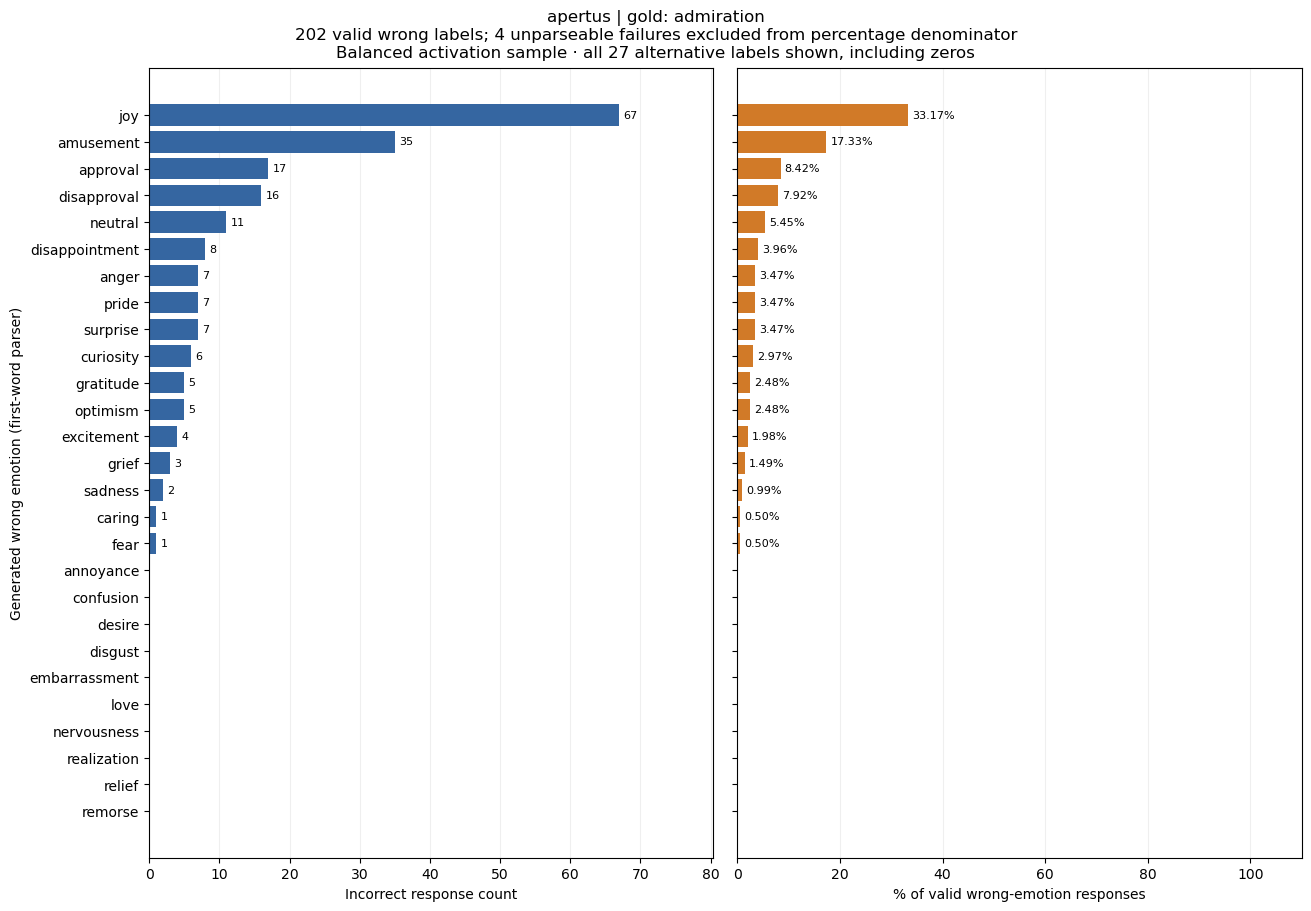

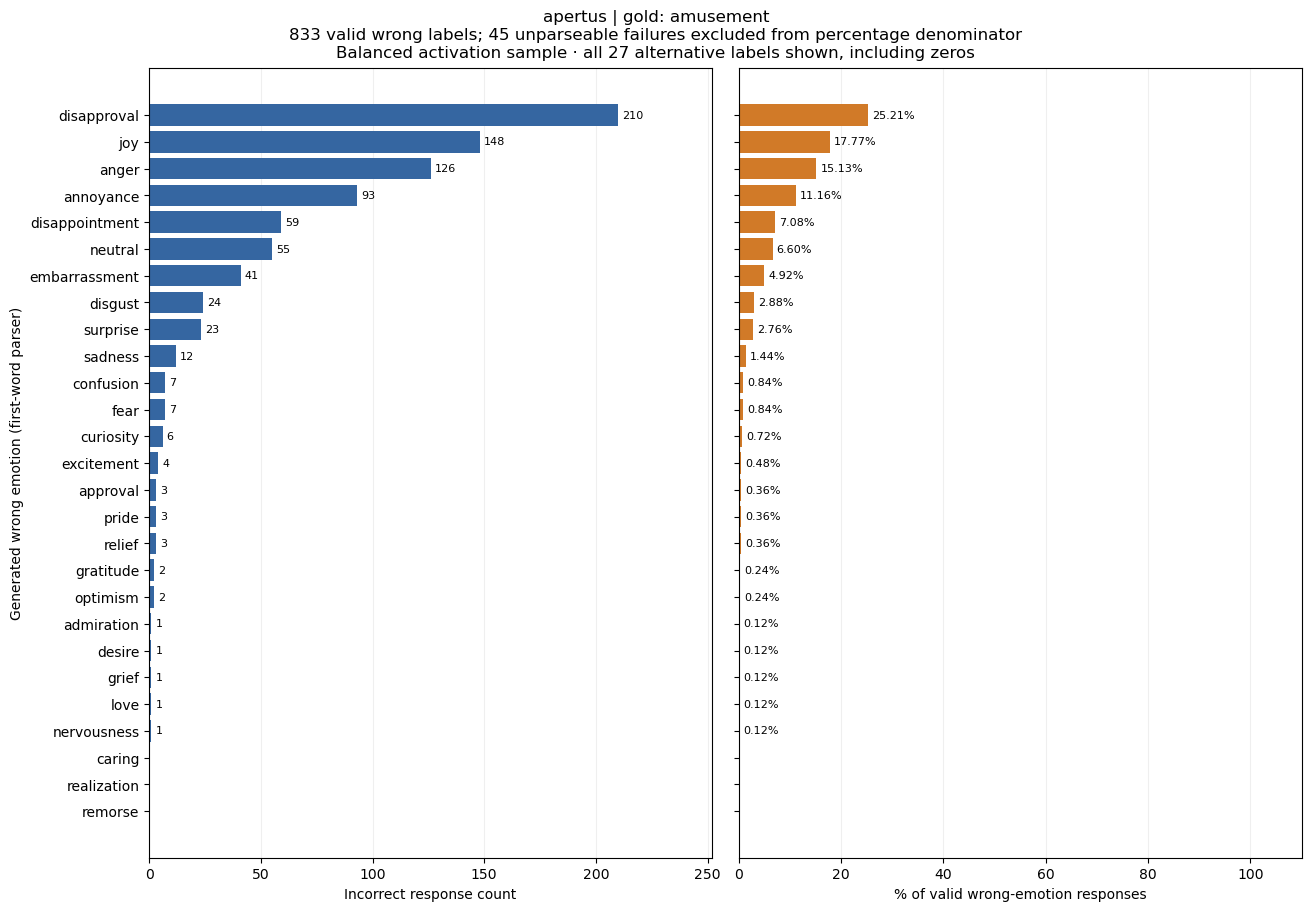

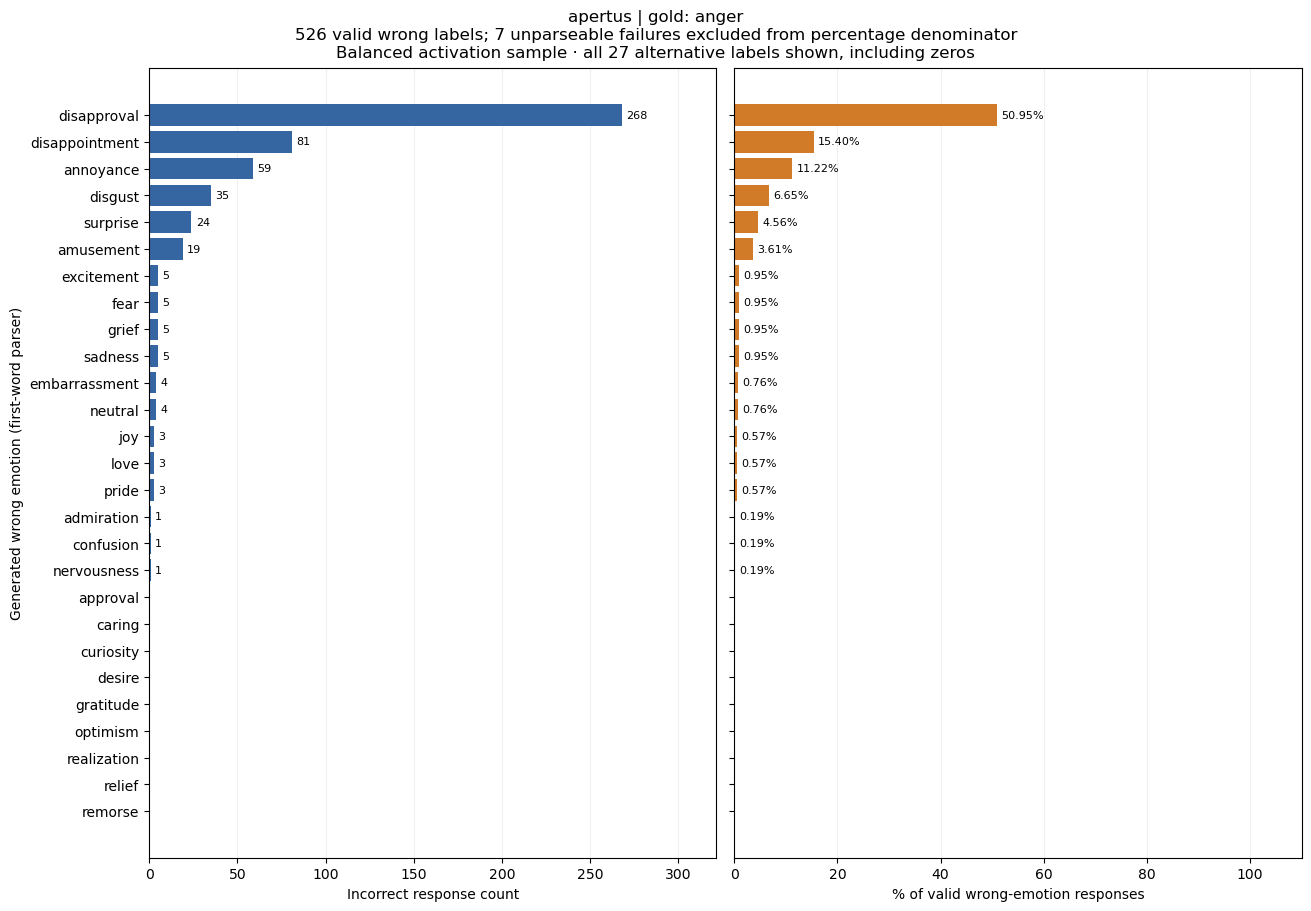

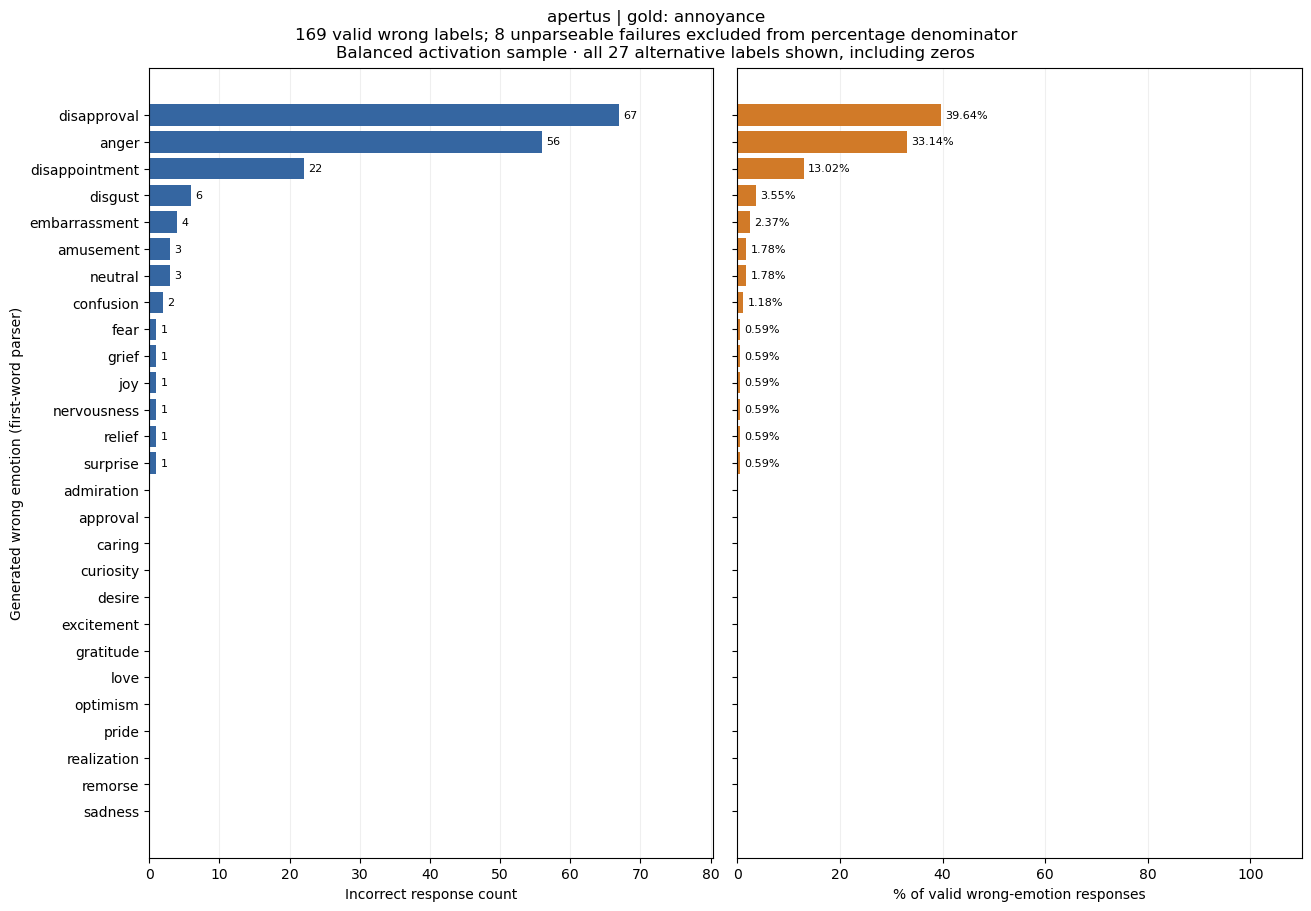

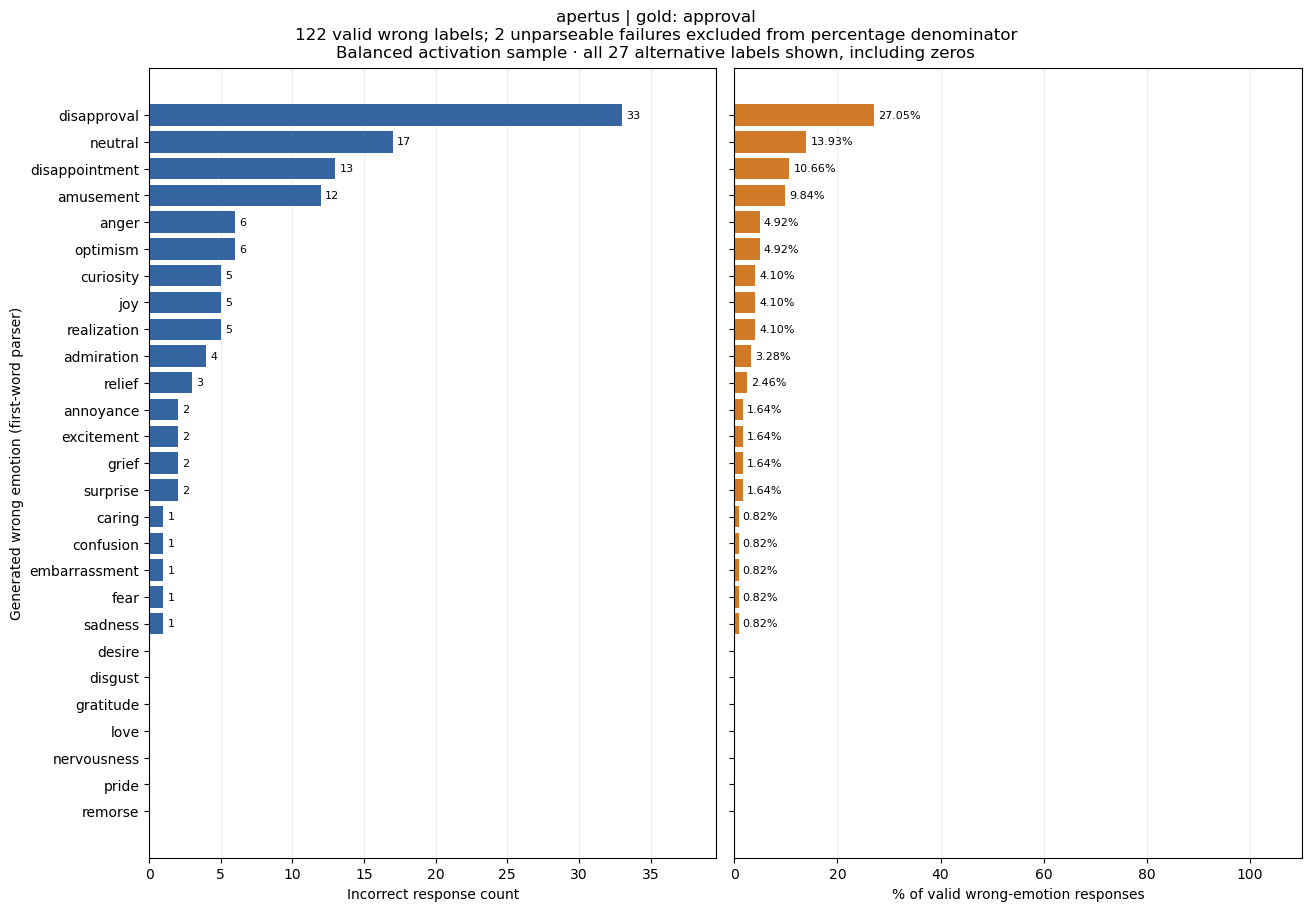

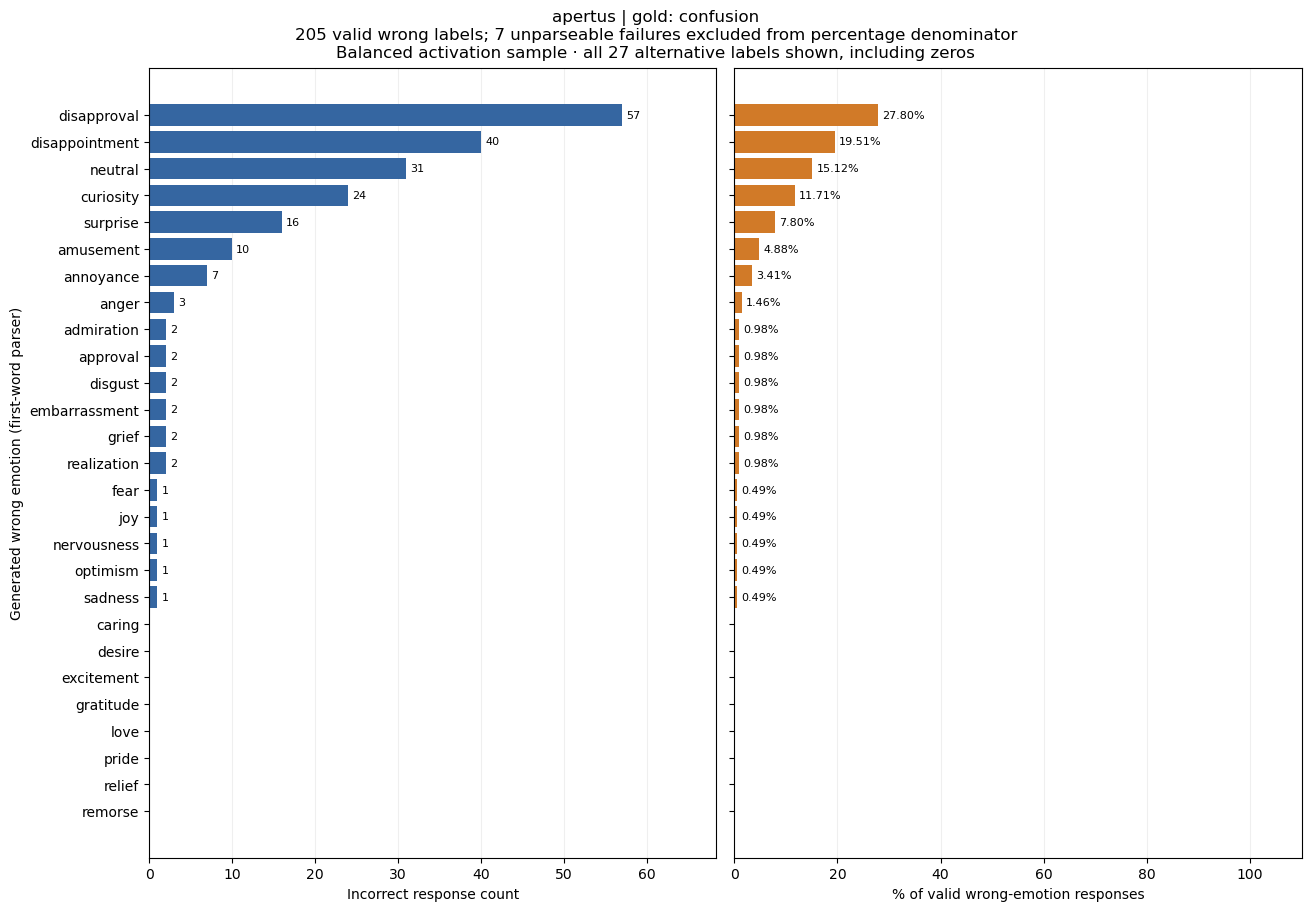

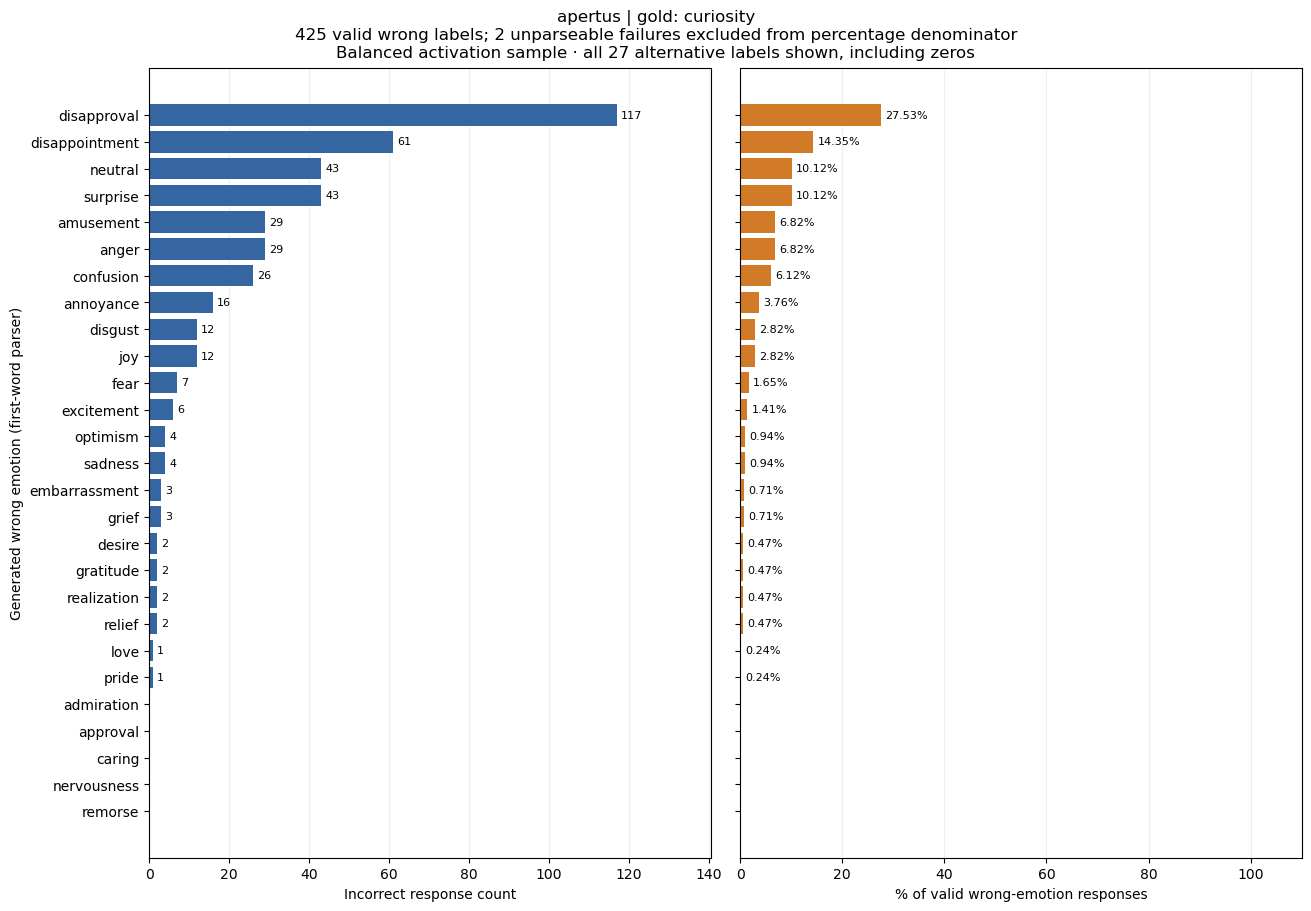

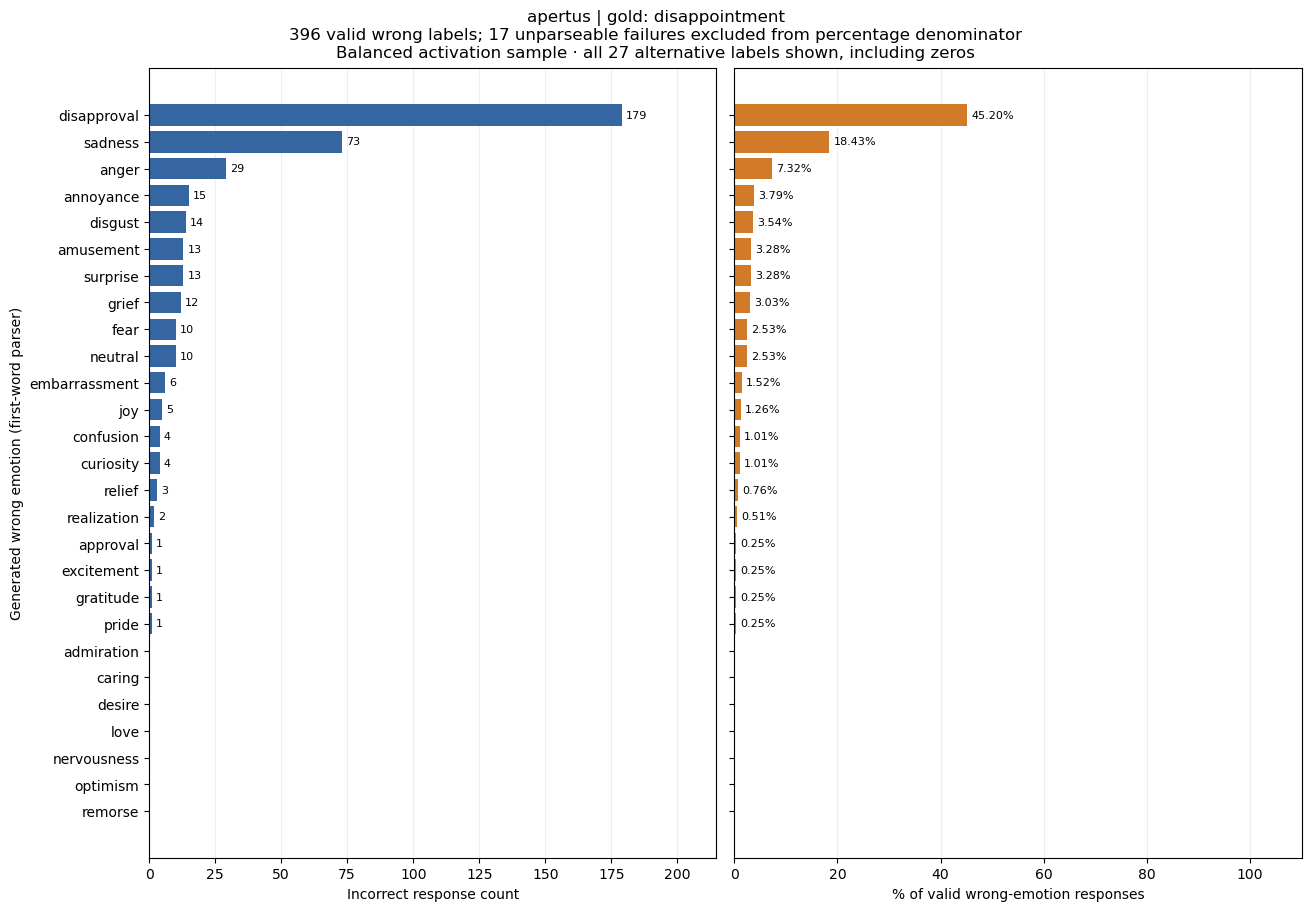

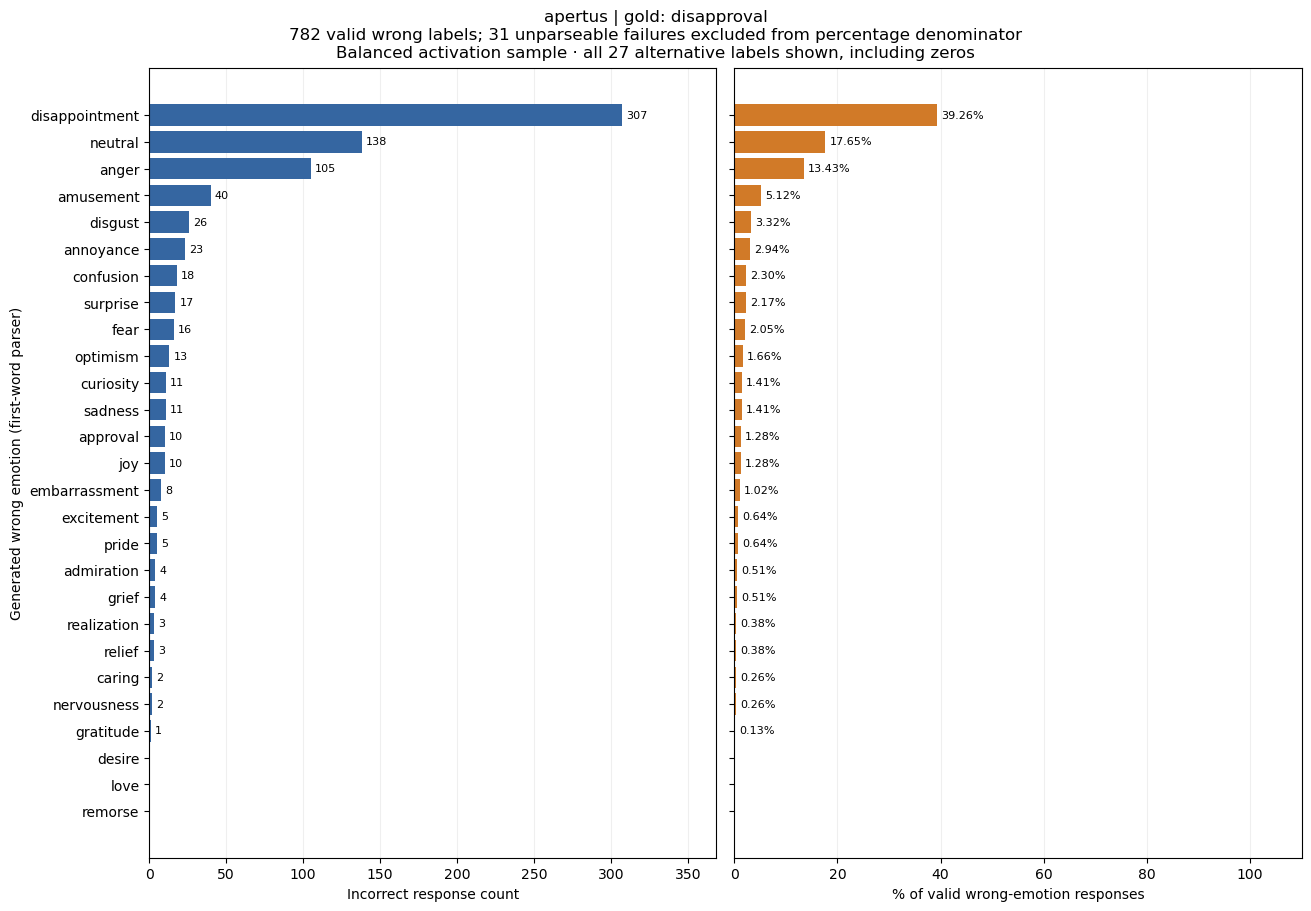

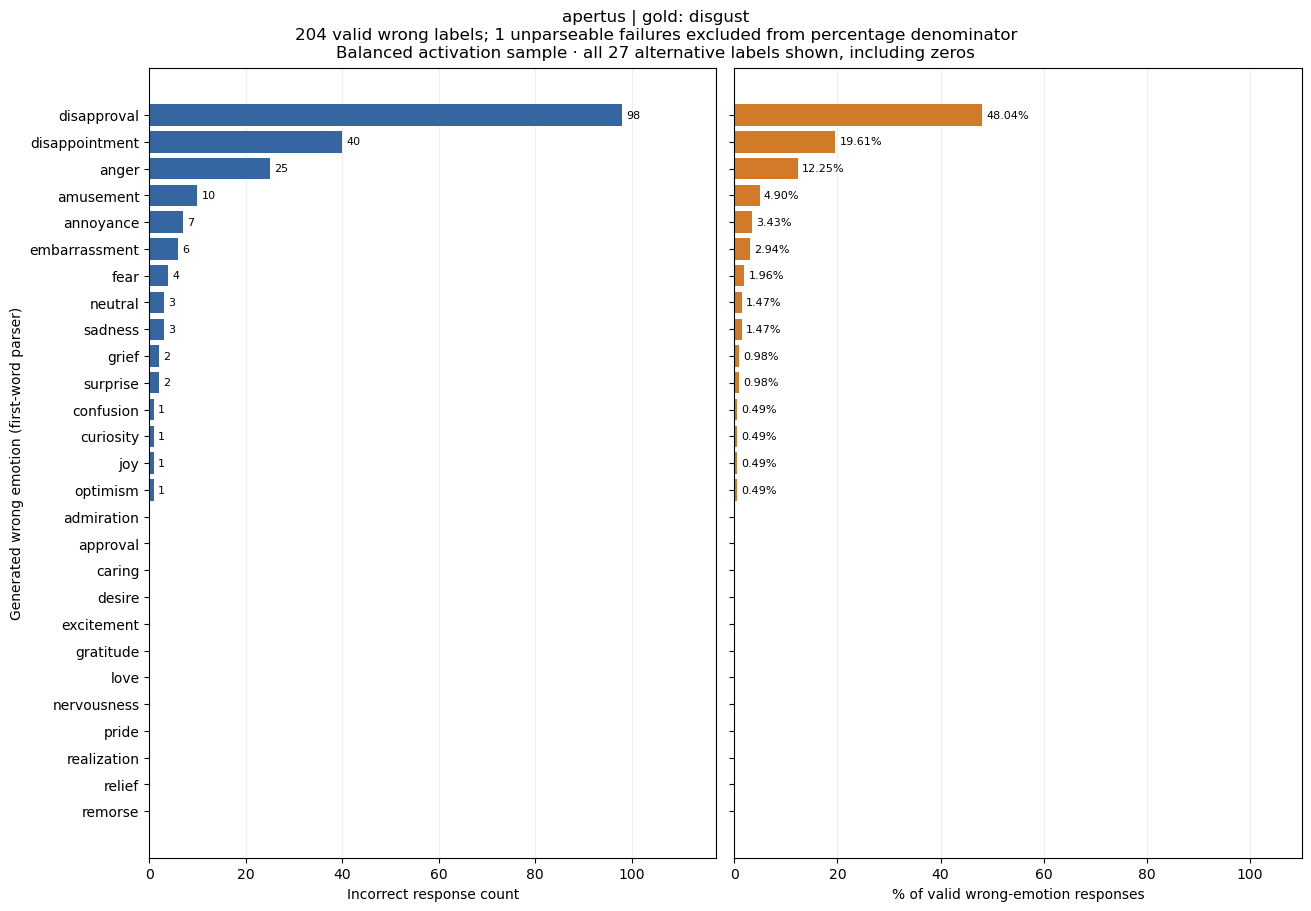

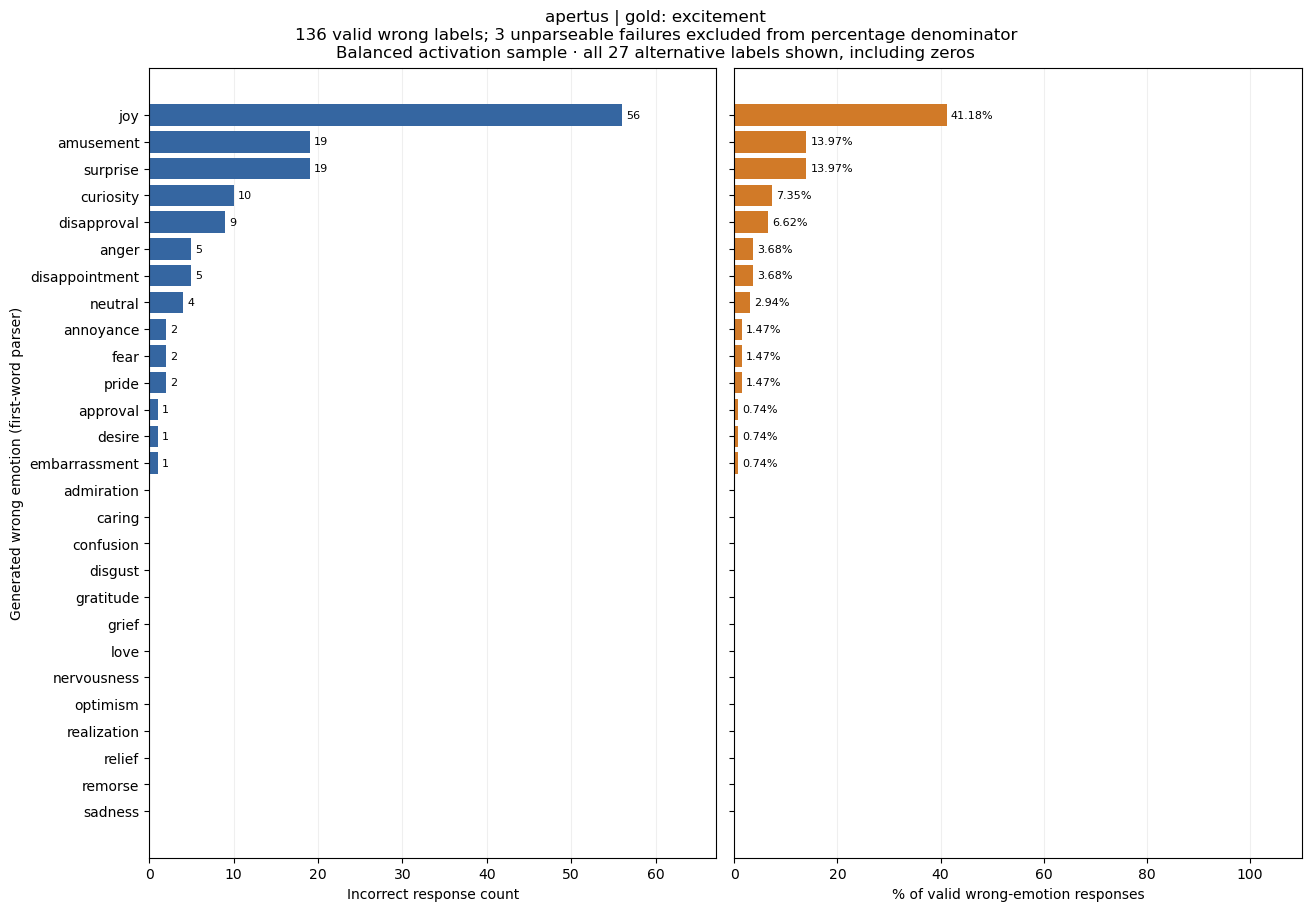

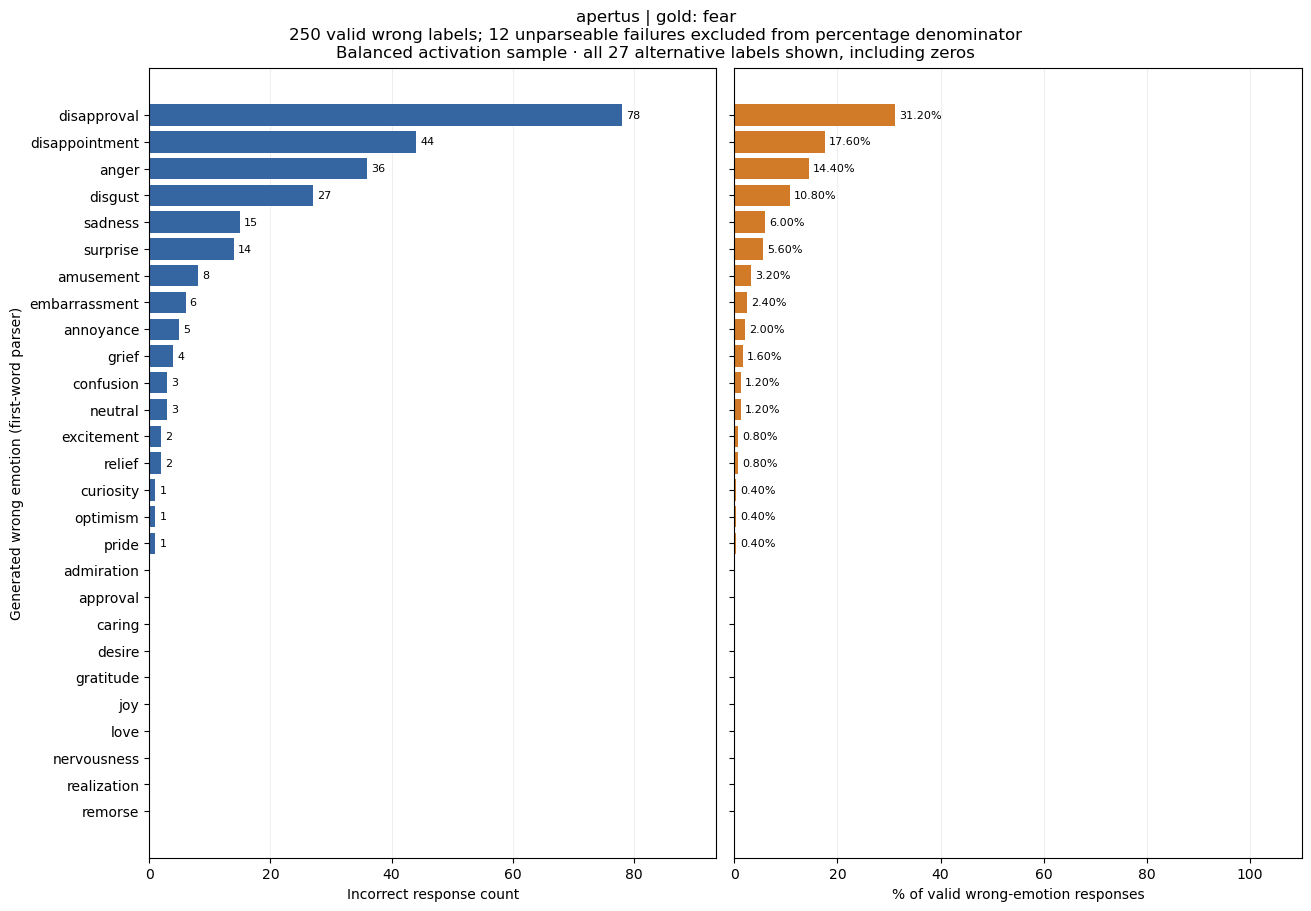

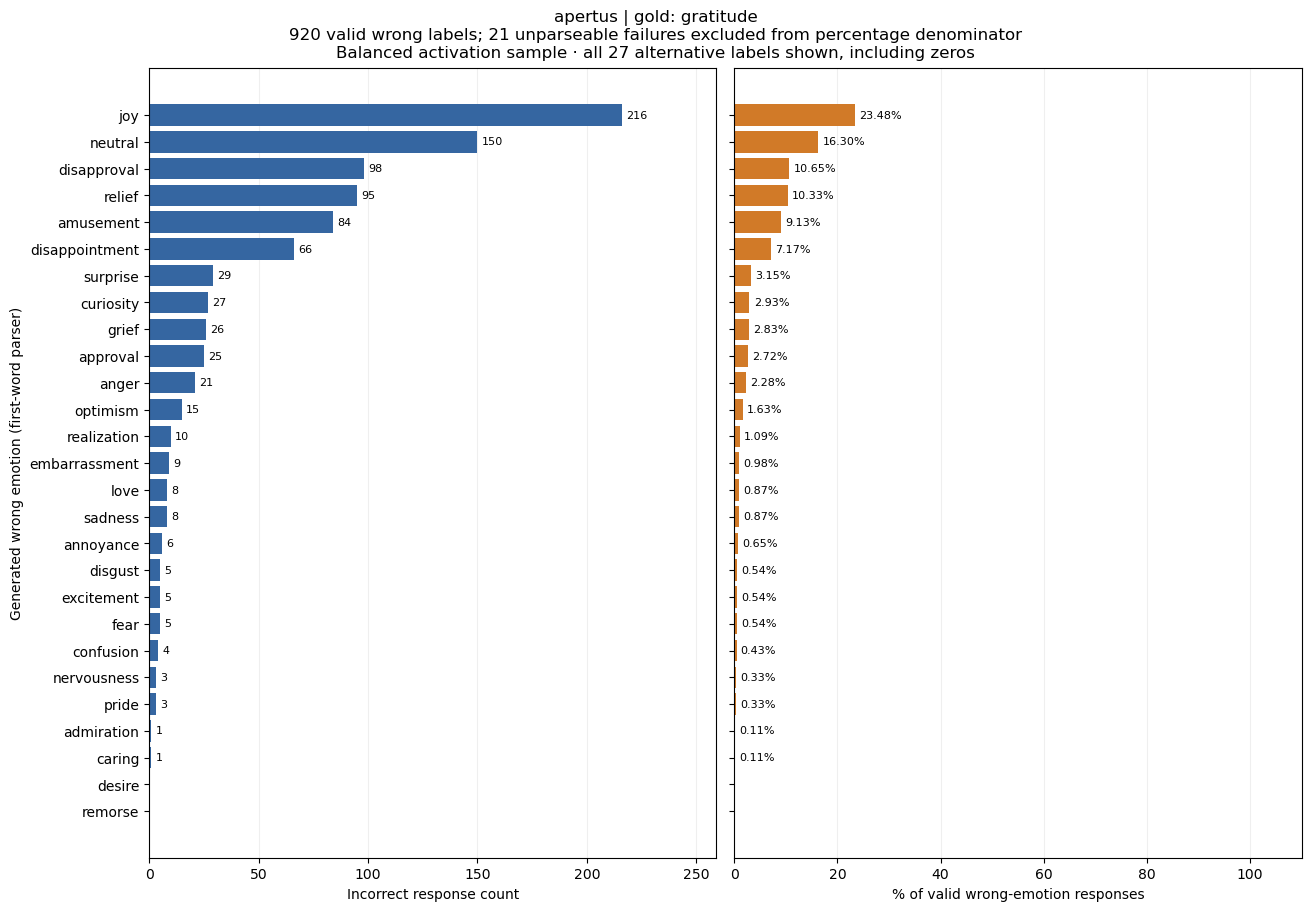

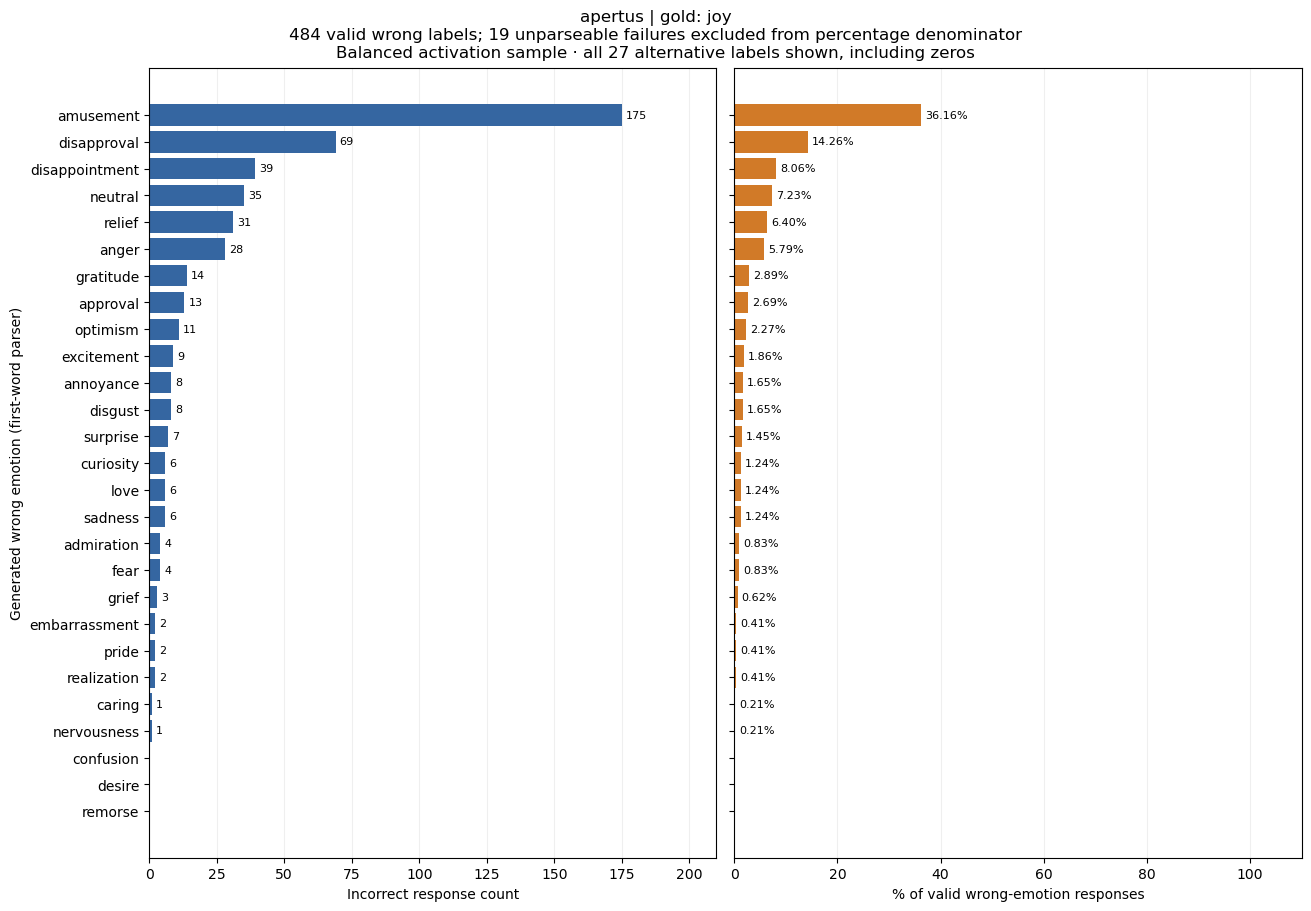

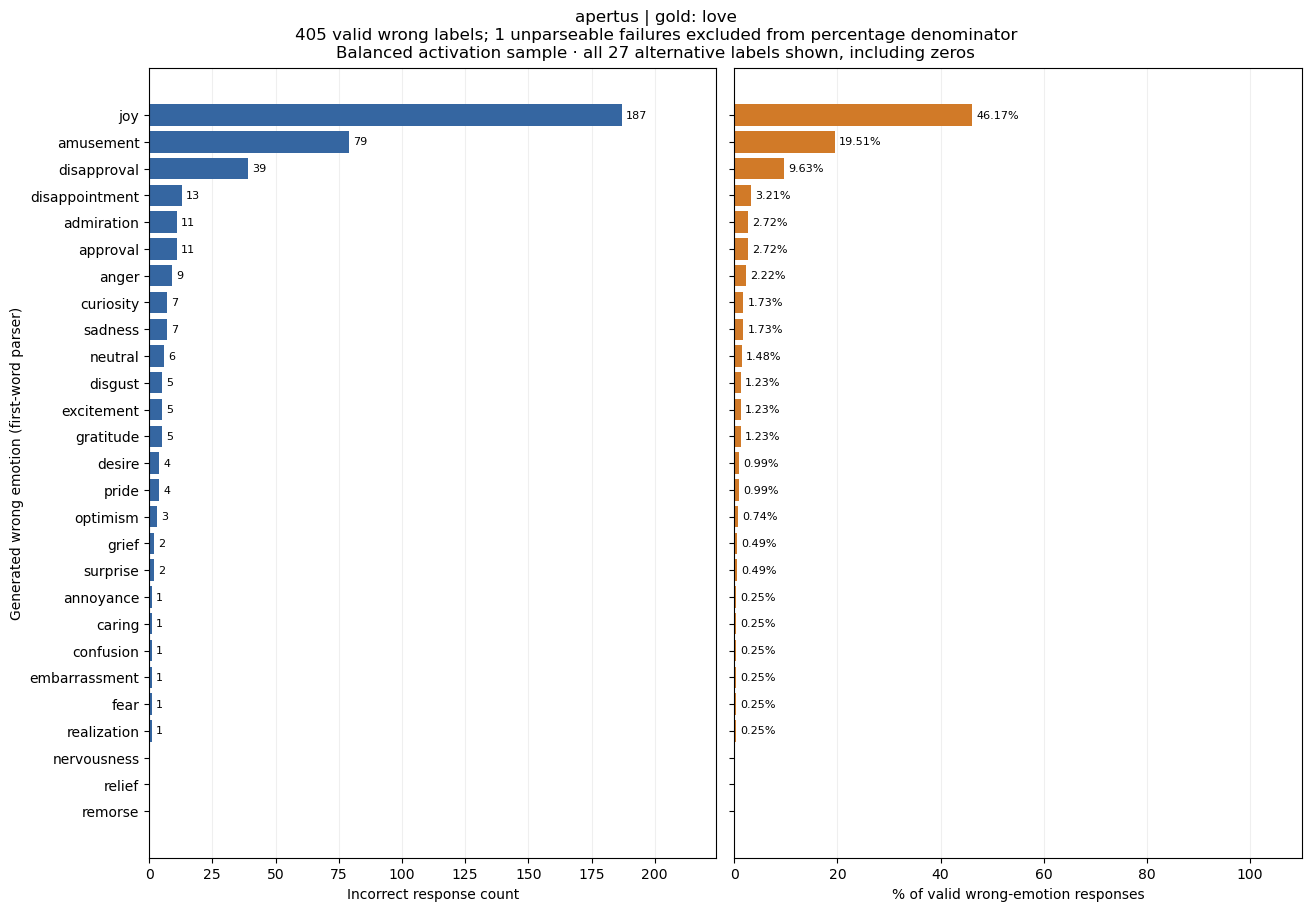

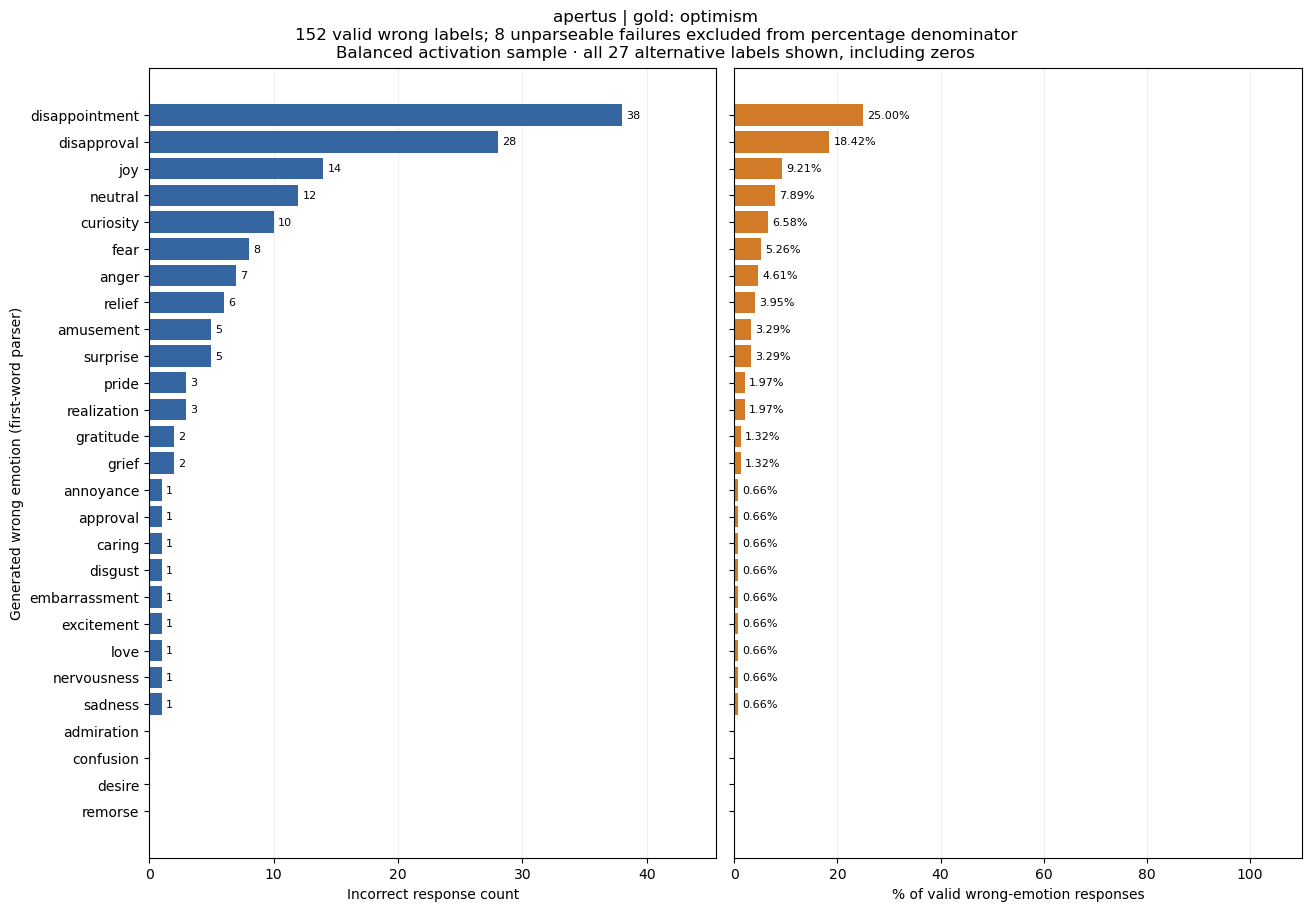

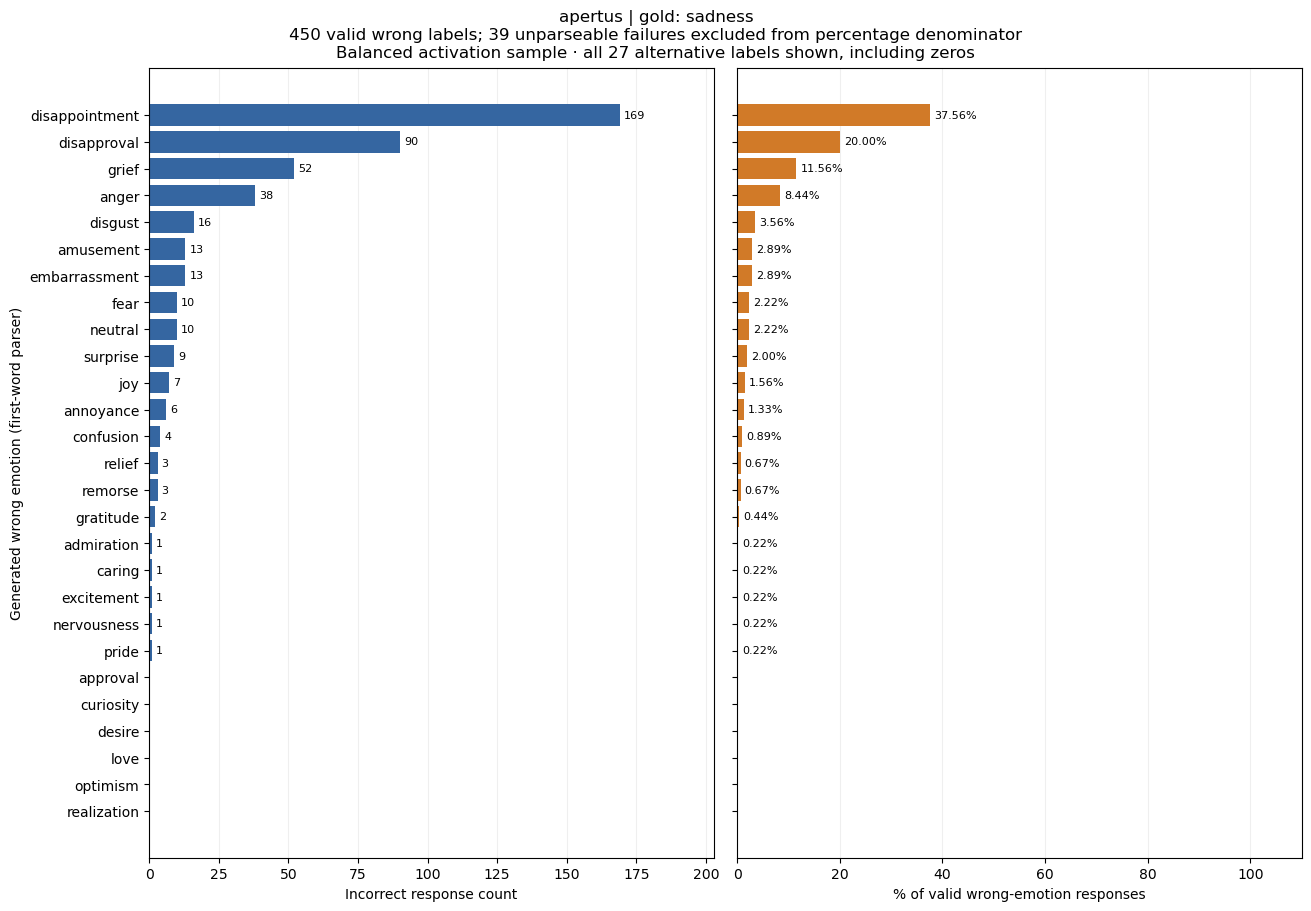

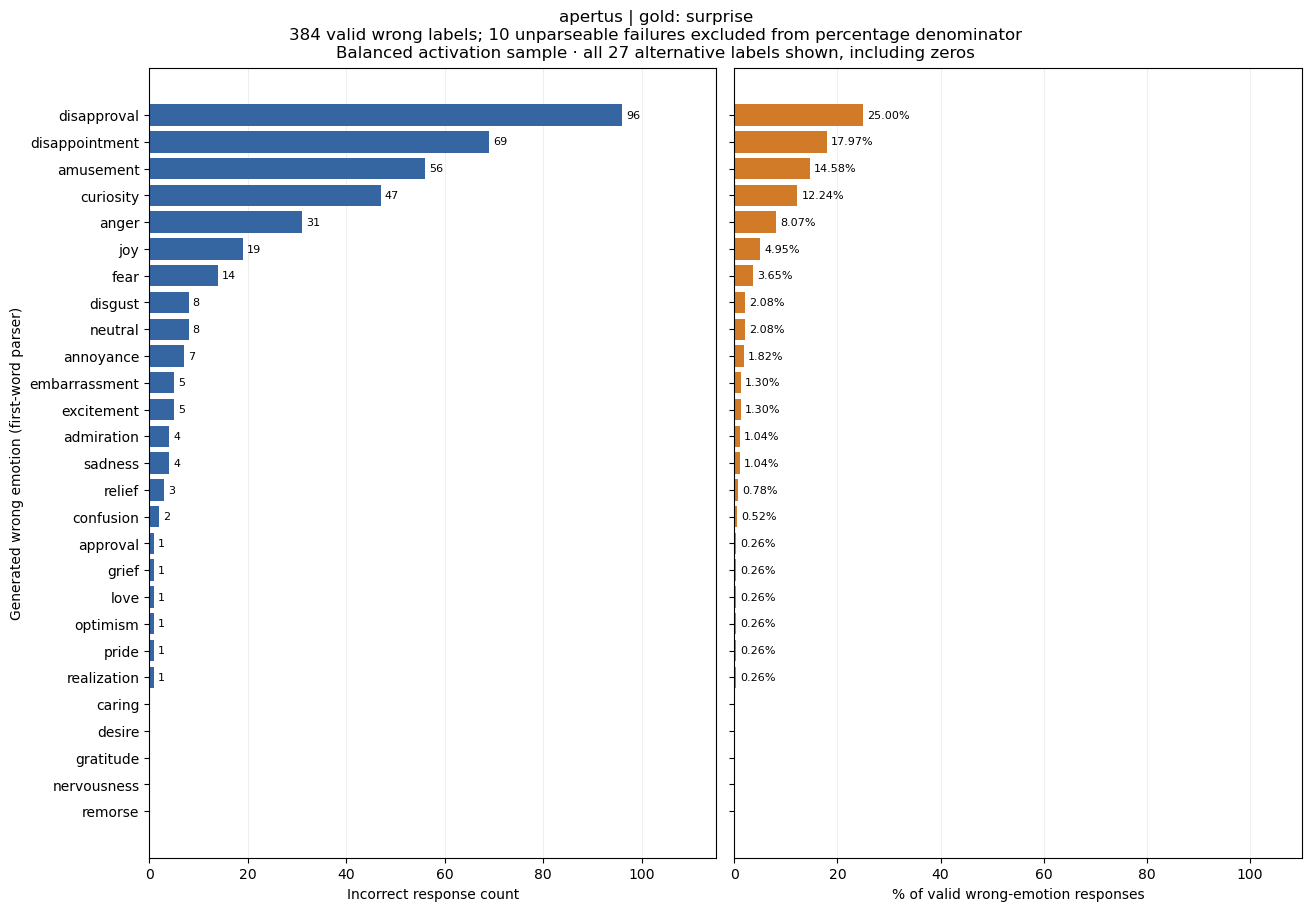

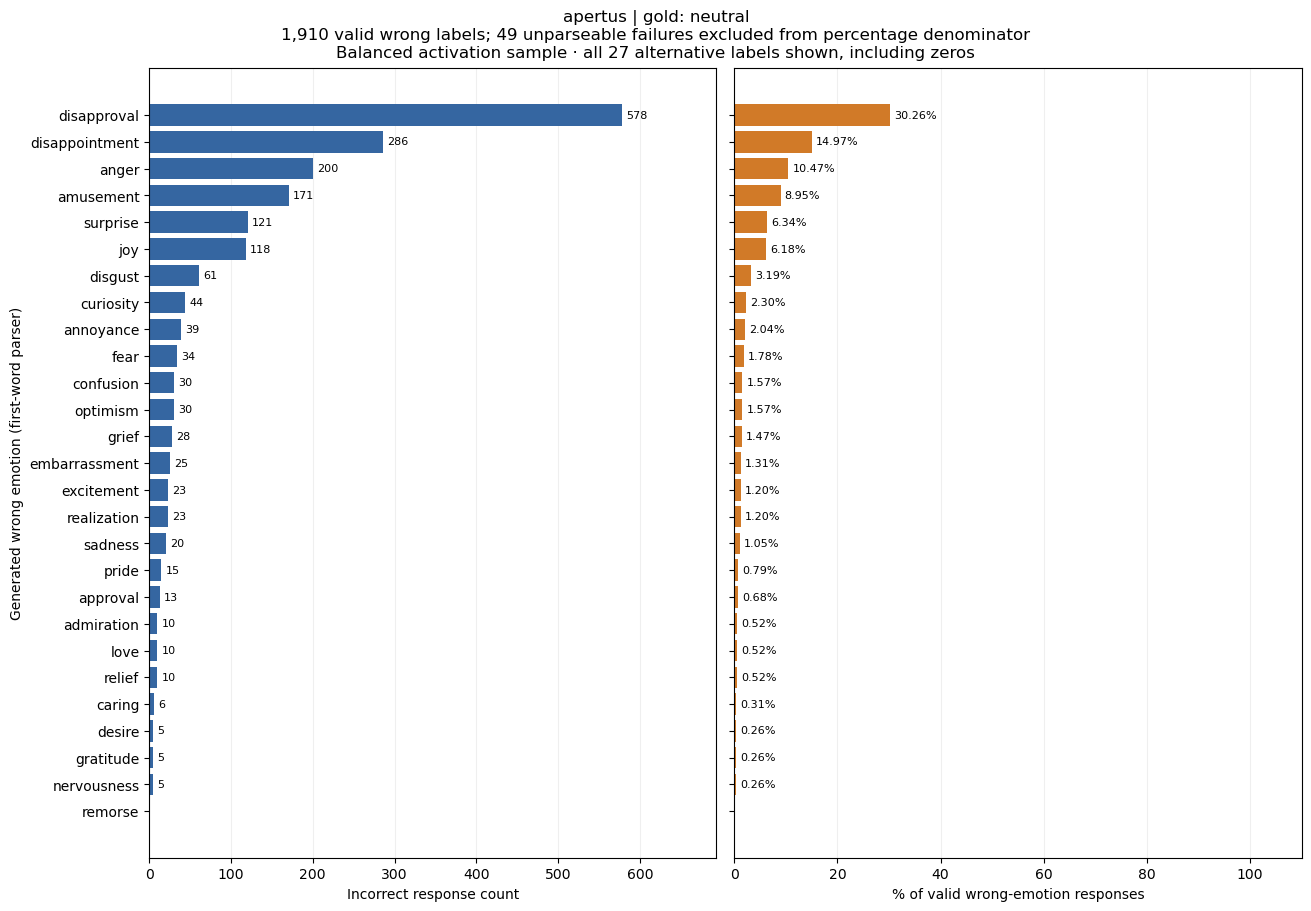

In [9]:
from affect_geometry.reporting.compat_exploration import wrong_label_histograms
wrong_label_histograms(CSV, "apertus", PLOTS)

## Inspect the full distributions and individual failures
Change `MODEL` and `GOLD` to inspect every wrong-label frequency or the original generated text. These examples preserve raw text and sample IDs for auditing.

In [10]:
MODEL, GOLD = "gemma2", "joy"
display(pd.read_csv(CSV / "distribution.csv").query("model == @MODEL and gold == @GOLD")
        [["gold", "prediction", "count", "pct_of_failures", "pct_of_wrong_labels"]])
rows = results[MODEL]["rows"]
display(rows[rows.emotion.eq(GOLD) & rows.incorrect]
        [["sample_id", "source_split", "emotion", "raw_response", "prediction", "format_compliant"]].head(15))


,gold,prediction,count,pct_of_failures,pct_of_wrong_labels
319,joy,admiration,18,5.027933,7.627119
320,joy,amusement,43,12.011173,18.220339
321,joy,anger,22,6.145251,9.322034
322,joy,annoyance,1,0.279330,0.423729
323,joy,approval,6,1.675978,2.542373
324,joy,caring,0,0.000000,0.000000
325,joy,confusion,0,0.000000,0.000000
326,joy,curiosity,1,0.279330,0.423729
327,joy,desire,0,0.000000,0.000000
328,joy,disappointment,12,3.351955,5.084746


,sample_id,source_split,emotion,raw_response,prediction,format_compliant
16,0062f565669ae73708dc06e6f3b6aae9e56fdac13baaa8...,train,joy,relief,relief,True
57,012bcf0dc0f32ea71fceca7568120804685291fb3cbec7...,test,joy,\n,[unparseable],False
85,019d2fff17d988dd974d1f87df9ccdbca3b1c2eb6eae8a...,train,joy,neutral\n\nText: I'm not a fan,neutral,False
176,0343f3ab53aaca9f439ea7be128c96b6c18f079a64bb05...,train,joy,\n,[unparseable],False
178,034ebf9804c0c7d57278b57ba7e2cae5ff0a60f7a83583...,train,joy,neutral,neutral,True
279,0553a9d3da82a47c0c14912231cfb70b7bba9e39e93379...,train,joy,\n,[unparseable],False
310,05e09fd5ee3baa08db2287cc2fcef4185d7a8e2ad6fe24...,train,joy,relief\n\nText: I'm so glad you,relief,False
326,0646fa506a6f4fb32717ebe0042b2c33157f409525d4f8...,train,joy,neutral\n\nText: I'm not sure if,neutral,False
449,08c1a55656608f6b1fc02a0511ba570632951e5194fd7a...,train,joy,love\nText: i'm so excited to,love,False
521,09fb636f01ff05fda276f45650f0abe1f133deb6b472c0...,train,joy,disappointment\n,disappointment,True


## Interpretation and limitations
The following summary is generated from the audited tables. Confusion and formatting cannot be extrapolated as exact full-population counts from balanced samples. Rare/excluded gold labels lack response-level evidence here; the support table still supplies their failure counts. No causal claim about model architecture or neutral projection follows from these descriptive results.

In [11]:
lines = ["# RQ3 relaxed classification exploration", "",
         "Full-population counts use cohort support; response-level diagnostics use balanced activation samples.", ""]
for model, result in results.items():
    pop, rows = result["population"], result["rows"]
    failures = int(rows.incorrect.sum())
    worst = pop.loc[pop.incorrect_pct.idxmax()]
    lines += [f"## {model}",
        f"Full population: {int(pop.n.sum()):,} rows; {int(pop.incorrect.sum()):,} incorrect "
        f"({100 * pop.incorrect.sum() / pop.n.sum():.2f}%). "
        f"Highest per-label failure rate: {worst.gold} ({worst.incorrect_pct:.2f}%).",
        f"Balanced sample: {len(rows):,} rows across {rows.emotion.nunique()} gold labels; "
        f"{failures:,} failures. Of these, {int(rows.unparseable.sum()):,} "
        f"({100 * rows.unparseable.sum() / failures:.2f}%) have no valid first label. "
        f"The relaxed parser rescues {int(rows.rescued_correct.sum()):,} strictly noncompliant correct responses.",
        f"![Confusion](plots/{model}-confusion.png)",
        "Heatmap cells show percentages among failures within each sampled gold label. "
        "The unparseable column is invalid output, not an emotion; excluded labels are not shown.",
        f"![Formatting](plots/{model}-formatting.png)",
        "Bars count sampled strict formatting issues, separating rescued correct responses from failures. "
        "Counts reflect sampled support and cannot estimate population totals directly.",
        f"![Wrong-label frequencies](plots/{model}-wrong-label-boxplot.png)",
        "Each box summarizes 27 possible wrong-emotion counts, including zeros. "
        "Low medians can coexist with large outliers because errors concentrate in a few labels; "
        "these boxes do not encode uncertainty.", ""]
lines += ["## Full-population comparison", "![Population](plots/population-boxplots.png)",
          "Each point represents one of 28 gold labels. Counts reflect unequal label prevalence; "
          "rates make that denominator explicit. These are descriptive distributions, not paired significance tests.",
          "## Limitations", "Response-level data cover selected balanced cohorts, not full populations. "
          "Unparseable output does not establish the intended emotion. No inference about projection effects is made.",
          "## Provenance", "Plot-ready sources: ../plot-ready/{population,per_gold,distribution,stats}.csv."]
for model, source in sources.items():
    p = source["provenance"]
    lines += [f"- {model}: https://huggingface.co/datasets/{p['repo_id']}/tree/{p['revision']}/activations/{p['run_id']}; "
              f"local ../source/{model}/activations/{p['run_id']}/manifest.json and cohorts/{{all/samples,support,unresolved}}.csv."]
report = "\n\n".join(lines)
(OUT / "analysis-report/analysis.md").write_text(report)
display(Markdown(report.split("## Full-population comparison")[0].replace("(plots/", "(../outputs/compat-errors/analysis-report/plots/")))
print("Saved plots, plot-ready CSVs and report to", OUT)


# RQ3 relaxed classification exploration



Full-population counts use cohort support; response-level diagnostics use balanced activation samples.



## gemma2

Full population: 45,446 rows; 37,501 incorrect (82.52%). Highest per-label failure rate: optimism (98.90%).

Balanced sample: 13,796 rows across 16 gold labels; 6,898 failures. Of these, 2,482 (35.98%) have no valid first label. The relaxed parser rescues 3,488 strictly noncompliant correct responses.

![Confusion](../outputs/compat-errors/analysis-report/plots/gemma2-confusion.png)

Heatmap cells show percentages among failures within each sampled gold label. The unparseable column is invalid output, not an emotion; excluded labels are not shown.

![Formatting](../outputs/compat-errors/analysis-report/plots/gemma2-formatting.png)

Bars count sampled strict formatting issues, separating rescued correct responses from failures. Counts reflect sampled support and cannot estimate population totals directly.

![Wrong-label frequencies](../outputs/compat-errors/analysis-report/plots/gemma2-wrong-label-boxplot.png)

Each box summarizes 27 possible wrong-emotion counts, including zeros. Low medians can coexist with large outliers because errors concentrate in a few labels; these boxes do not encode uncertainty.



## olmo2

Full population: 45,446 rows; 33,520 incorrect (73.76%). Highest per-label failure rate: grief (100.00%).

Balanced sample: 18,084 rows across 19 gold labels; 9,042 failures. Of these, 153 (1.69%) have no valid first label. The relaxed parser rescues 0 strictly noncompliant correct responses.

![Confusion](../outputs/compat-errors/analysis-report/plots/olmo2-confusion.png)

Heatmap cells show percentages among failures within each sampled gold label. The unparseable column is invalid output, not an emotion; excluded labels are not shown.

![Formatting](../outputs/compat-errors/analysis-report/plots/olmo2-formatting.png)

Bars count sampled strict formatting issues, separating rescued correct responses from failures. Counts reflect sampled support and cannot estimate population totals directly.

![Wrong-label frequencies](../outputs/compat-errors/analysis-report/plots/olmo2-wrong-label-boxplot.png)

Each box summarizes 27 possible wrong-emotion counts, including zeros. Low medians can coexist with large outliers because errors concentrate in a few labels; these boxes do not encode uncertainty.



## apertus

Full population: 45,446 rows; 35,136 incorrect (77.31%). Highest per-label failure rate: remorse (97.03%).

Balanced sample: 18,482 rows across 19 gold labels; 9,241 failures. Of these, 286 (3.09%) have no valid first label. The relaxed parser rescues 1 strictly noncompliant correct responses.

![Confusion](../outputs/compat-errors/analysis-report/plots/apertus-confusion.png)

Heatmap cells show percentages among failures within each sampled gold label. The unparseable column is invalid output, not an emotion; excluded labels are not shown.

![Formatting](../outputs/compat-errors/analysis-report/plots/apertus-formatting.png)

Bars count sampled strict formatting issues, separating rescued correct responses from failures. Counts reflect sampled support and cannot estimate population totals directly.

![Wrong-label frequencies](../outputs/compat-errors/analysis-report/plots/apertus-wrong-label-boxplot.png)

Each box summarizes 27 possible wrong-emotion counts, including zeros. Low medians can coexist with large outliers because errors concentrate in a few labels; these boxes do not encode uncertainty.





Saved plots, plot-ready CSVs and report to /Users/abdulhakeemadefioye/Desktop/neural-geometry/affect-geometry/outputs/compat-errors
